<a href="https://colab.research.google.com/github/hju316/AIBehaviorPerDrone/blob/main/1116261254DeepONetSAFModeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hypersonic nonequilibrium chemistry simulation with a DeepONet solver.

Following implementation will include:
Temperature- and pressure-dependent oxygen and nitrogen dissociation.
Stiff reference chemistry integration using SciPy's Radau solver.
A PyTorch DeepONet trained on the reference solutions.
Microsecond-resolved species evolution.
Reference-versus-neural-network comparisons.
Conservation and prediction-error verification.
GPU support when available.

HYPERSONIC CHEMISTRY / DeepONet
Device: cpu
PyTorch: 2.14.1+cpu
SciPy: 1.16.3

Generating reference chemistry dataset...
Generated trajectories: 50
Generated trajectories: 100
Generated trajectories: 150
Generated trajectories: 200
Generated trajectories: 250
Generated trajectories: 300
Total training samples: 16000
Branch dimensions: (16000, 4)
Trunk dimensions: (16000, 1)
Output dimensions: (16000, 2)

Training DeepONet...
Epoch   25/350 | Train: 3.6842335e-03 | Validation: 4.4819218e-03
Epoch   50/350 | Train: 2.8459545e-03 | Validation: 3.6795145e-03
Epoch   75/350 | Train: 2.8002630e-03 | Validation: 3.6197663e-03
Epoch  100/350 | Train: 2.7818697e-03 | Validation: 3.5635966e-03
Epoch  125/350 | Train: 2.7631477e-03 | Validation: 3.5849931e-03
Epoch  150/350 | Train: 2.7503326e-03 | Validation: 3.5400920e-03
Epoch  175/350 | Train: 2.7201183e-03 | Validation: 3.5008473e-03
Epoch  200/350 | Train: 2.7016236e-03 | Validation: 3.4799458e-03
Epoch  225/350 | Train: 2.7032498e-03 | Val

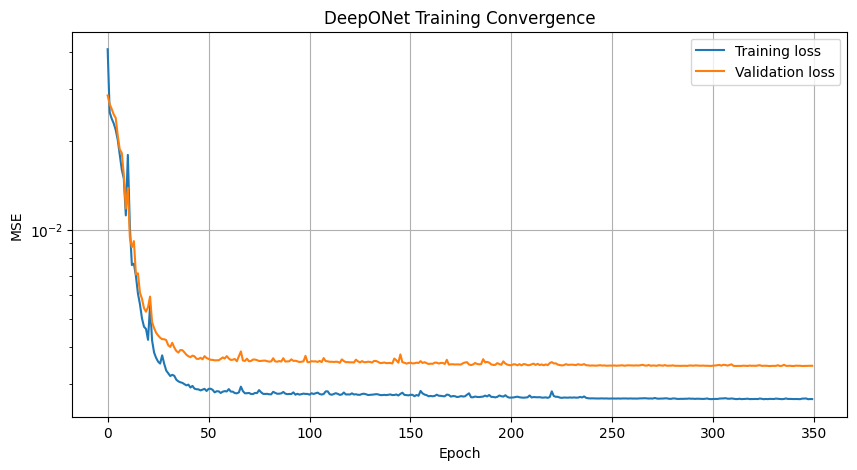

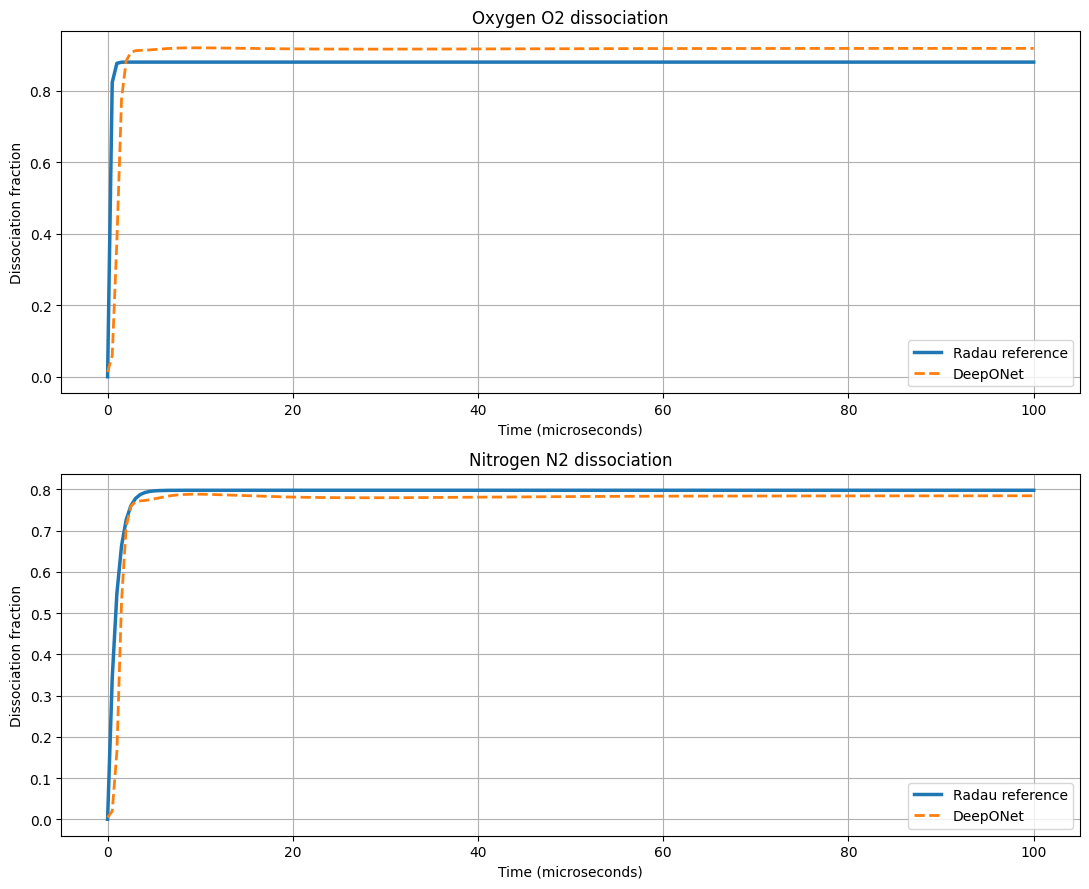

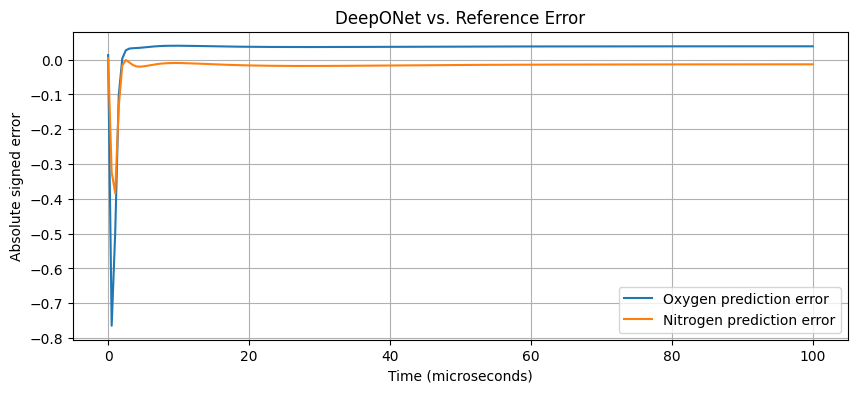

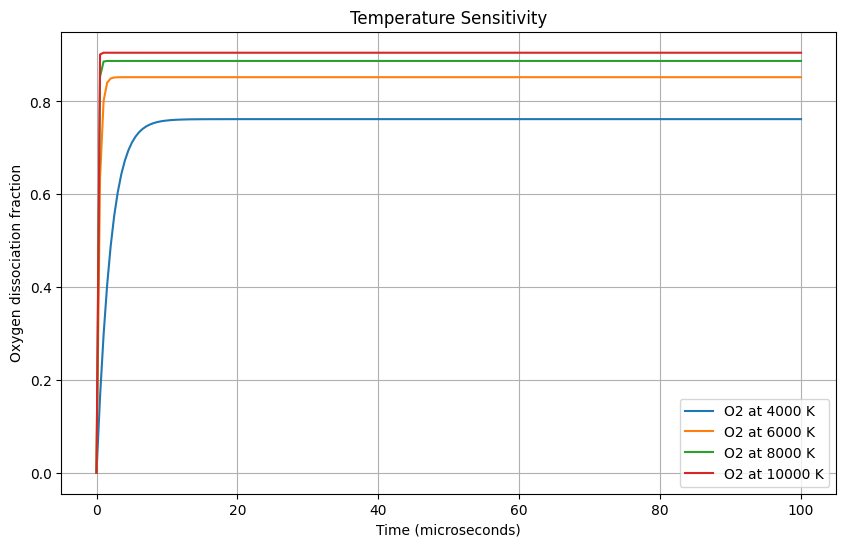


Saved: hypersonic_deeponet_v1.pt

SIMULATION FINISHED


In [ ]:

# ================================================================
# HYPERSONIC NONEQUILIBRIUM CHEMISTRY + DeepONet
# Version 1.0 | Google Colab
#
# Reduced model:
#   O2 <-> 2O
#   N2 <-> 2N
#
# Reference: SciPy Radau stiff ODE integration
# Surrogate: PyTorch Deep Operator Network
# ================================================================

import sys, subprocess, time, copy
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "numpy", "scipy", "matplotlib", "torch"
])

import numpy as np
import scipy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------
# 1. COMPUTATIONAL CONFIGURATION
# ------------------------------------------------

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("HYPERSONIC CHEMISTRY / DeepONet")
print("=" * 65)
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("SciPy:", scipy.__version__)

R = 8.314462618       # J/(mol K)
T_MIN, T_MAX = 3000., 12000.
P_MIN, P_MAX = 1.e3, 1.e5
T_END = 100.e-6       # 100 microseconds

# ------------------------------------------------
# 2. REDUCED CHEMISTRY MODEL
# ------------------------------------------------
#
# alpha = fraction of initial diatomic molecules
#        dissociated.
#
# alpha = 0: entirely diatomic
# alpha = 1: entirely dissociated
#
# This reduced rate law is illustrative, not a
# validated elementary reaction mechanism.

def rate_constants(T, P):

    # Oxygen dissociation/recombination
    kf_O = 8.e7 * np.exp(-180000. / (R*T))
    kr_O = 2.e7 * np.exp(-110000. / (R*T)) * (P/1.e5)

    # Nitrogen dissociation/recombination
    kf_N = 4.e7 * np.exp(-240000. / (R*T))
    kr_N = 1.5e7 * np.exp(-150000. / (R*T)) * (P/1.e5)

    return kf_O, kr_O, kf_N, kr_N


def chemistry_rhs(t, y, T, P):

    aO, aN = y

    kfO, krO, kfN, krN = rate_constants(T, P)

    daO = kfO*(1-aO) - krO*aO**2
    daN = kfN*(1-aN) - krN*aN**2

    return [daO, daN]


def reference_solver(T, P, aO0=0., aN0=0., times=None):

    if times is None:
        times = np.linspace(0, T_END, 100)

    solution = solve_ivp(
        chemistry_rhs,
        (0., float(times[-1])),
        [aO0, aN0],
        args=(T, P),
        method="Radau",
        t_eval=times,
        rtol=1.e-8,
        atol=1.e-10,
        max_step=2.e-6
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    return np.clip(solution.y.T, 0., 1.)


# ------------------------------------------------
# 3. GENERATE TRAINING DATA
# ------------------------------------------------

def generate_dataset(n_trajectories=320, n_times=50):

    X_branch = []
    X_trunk = []
    Y = []

    for i in range(n_trajectories):

        T = np.random.uniform(T_MIN, T_MAX)
        P = 10**np.random.uniform(
            np.log10(P_MIN), np.log10(P_MAX)
        )

        aO0 = np.random.uniform(0., 0.03)
        aN0 = np.random.uniform(0., 0.01)

        times = np.linspace(0., T_END, n_times)

        states = reference_solver(
            T, P, aO0, aN0, times
        )

        # Branch input: local flow state
        branch = np.array([
            T / T_MAX,
            np.log10(P / P_MIN) / np.log10(P_MAX/P_MIN),
            aO0,
            aN0
        ])

        # Trunk input: normalized query time
        for j, t in enumerate(times):

            trunk = [t / T_END]

            X_branch.append(branch)
            X_trunk.append(trunk)
            Y.append(states[j])

        if (i+1) % 50 == 0:
            print("Generated trajectories:", i+1)

    return (
        np.asarray(X_branch, dtype=np.float32),
        np.asarray(X_trunk, dtype=np.float32),
        np.asarray(Y, dtype=np.float32)
    )


print("\nGenerating reference chemistry dataset...")

Xb, Xt, Y = generate_dataset()

print("Total training samples:", len(Y))
print("Branch dimensions:", Xb.shape)
print("Trunk dimensions:", Xt.shape)
print("Output dimensions:", Y.shape)

# Split by trajectory, avoiding leakage between
# different time samples from the same trajectory.

n_train = int(0.85 * 320 * 50)

indices = np.random.permutation(320)

train_ids = indices[:int(.85*320)]
val_ids = indices[int(.85*320):]

sample_ids = np.arange(320*50).reshape(320,50)

train_idx = sample_ids[train_ids].flatten()
val_idx = sample_ids[val_ids].flatten()

train_ds = TensorDataset(
    torch.tensor(Xb[train_idx]),
    torch.tensor(Xt[train_idx]),
    torch.tensor(Y[train_idx])
)

val_ds = TensorDataset(
    torch.tensor(Xb[val_idx]),
    torch.tensor(Xt[val_idx]),
    torch.tensor(Y[val_idx])
)

train_loader = DataLoader(
    train_ds, batch_size=512, shuffle=True
)

val_loader = DataLoader(
    val_ds, batch_size=512, shuffle=False
)

# ------------------------------------------------
# 4. DeepONet ARCHITECTURE
# ------------------------------------------------

class MLP(nn.Module):

    def __init__(self, input_dim, output_dim, width=128):

        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, width),
            nn.Tanh(),
            nn.Linear(width, width),
            nn.Tanh(),
            nn.Linear(width, width),
            nn.Tanh(),
            nn.Linear(width, output_dim)
        )

    def forward(self, x):
        return self.net(x)


class DeepONet(nn.Module):

    def __init__(self, latent_dim=128):

        super().__init__()

        self.branch = MLP(4, latent_dim)
        self.trunk = MLP(1, latent_dim)

        self.bias = nn.Parameter(torch.zeros(2))

    def forward(self, branch_input, trunk_input):

        b = self.branch(branch_input)
        t = self.trunk(trunk_input)

        # Operator inner product
        z = torch.sum(b*t, dim=1, keepdim=True)

        # Two species outputs
        z = z + self.bias.unsqueeze(0)

        # Constrain dissociation fractions to [0,1]
        return torch.sigmoid(z)


model = DeepONet().to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(), lr=1.e-3
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, factor=0.5, patience=30
)

loss_fn = nn.MSELoss()

# ------------------------------------------------
# 5. TRAINING
# ------------------------------------------------

EPOCHS = 350

train_history = []
val_history = []

print("\nTraining DeepONet...")

start = time.time()

best_val = float("inf")
best_weights = None

for epoch in range(EPOCHS):

    model.train()
    running = 0.

    for xb, xt, y in train_loader:

        xb = xb.to(DEVICE)
        xt = xt.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad()

        pred = model(xb, xt)
        loss = loss_fn(pred, y)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        optimizer.step()

        running += loss.item() * len(y)

    train_loss = running / len(train_ds)

    model.eval()
    validation = 0.

    with torch.no_grad():

        for xb, xt, y in val_loader:

            xb = xb.to(DEVICE)
            xt = xt.to(DEVICE)
            y = y.to(DEVICE)

            pred = model(xb, xt)

            validation += loss_fn(
                pred, y
            ).item() * len(y)

    val_loss = validation / len(val_ds)

    scheduler.step(val_loss)

    train_history.append(train_loss)
    val_history.append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        best_weights = copy.deepcopy(model.state_dict())

    if (epoch+1) % 25 == 0:
        print(
            f"Epoch {epoch+1:4d}/{EPOCHS} | "
            f"Train: {train_loss:.7e} | "
            f"Validation: {val_loss:.7e}"
        )

model.load_state_dict(best_weights)

training_time = time.time() - start

print("\nTraining completed.")
print("Best validation MSE:", best_val)
print("Training time:", training_time, "seconds")

# ------------------------------------------------
# 6. INDEPENDENT TEST CASE
# ------------------------------------------------

T_TEST = 7500.
P_TEST = 2.e4

aO0_TEST = 0.
aN0_TEST = 0.

times = np.linspace(0., T_END, 200)

reference = reference_solver(
    T_TEST,
    P_TEST,
    aO0_TEST,
    aN0_TEST,
    times
)

branch_test = np.array([[
    T_TEST/T_MAX,
    np.log10(P_TEST/P_MIN)/np.log10(P_MAX/P_MIN),
    aO0_TEST,
    aN0_TEST
]], dtype=np.float32)

trunk_test = (times/T_END).reshape(-1,1).astype(np.float32)

branch_tensor = torch.tensor(
    np.repeat(branch_test, len(times), axis=0)
).to(DEVICE)

trunk_tensor = torch.tensor(trunk_test).to(DEVICE)

model.eval()

with torch.no_grad():

    predicted = model(
        branch_tensor,
        trunk_tensor
    ).cpu().numpy()

# ------------------------------------------------
# 7. NUMERICAL VERIFICATION
# ------------------------------------------------

errors = predicted - reference

rmse = np.sqrt(np.mean(errors**2))
max_error = np.max(np.abs(errors))

print("\n" + "="*65)
print("INDEPENDENT VERIFICATION")
print("="*65)

print(f"Test temperature:       {T_TEST:.1f} K")
print(f"Test pressure:          {P_TEST:.2e} Pa")
print(f"Simulation duration:    {T_END*1e6:.2f} microseconds")
print(f"RMSE:                   {rmse:.7e}")
print(f"Maximum absolute error: {max_error:.7e}")

# Physical admissibility
positive = np.all(predicted >= -1.e-7)
bounded = np.all(predicted <= 1.+1.e-7)

# Element conservation:
# molecular fraction + half atomic fraction = 1
# alpha is the fraction of original molecules dissociated.

oxygen_balance = (
    (1-predicted[:,0]) + predicted[:,0]
)

nitrogen_balance = (
    (1-predicted[:,1]) + predicted[:,1]
)

conservation_error = max(
    np.max(np.abs(oxygen_balance-1)),
    np.max(np.abs(nitrogen_balance-1))
)

print("Positive species fractions:", positive)
print("Bounded species fractions:", bounded)
print("Element balance error:", conservation_error)

# ------------------------------------------------
# 8. PLOTS
# ------------------------------------------------

time_us = times * 1.e6

plt.figure(figsize=(10,5))
plt.plot(
    train_history, label="Training loss"
)
plt.plot(
    val_history, label="Validation loss"
)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("DeepONet Training Convergence")
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(2,1,figsize=(11,9))

species = ["Oxygen O2 dissociation",
           "Nitrogen N2 dissociation"]

for i, ax in enumerate(axes):

    ax.plot(
        time_us,
        reference[:,i],
        linewidth=2.5,
        label="Radau reference"
    )

    ax.plot(
        time_us,
        predicted[:,i],
        "--",
        linewidth=2,
        label="DeepONet"
    )

    ax.set_xlabel("Time (microseconds)")
    ax.set_ylabel("Dissociation fraction")
    ax.set_title(species[i])
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

plt.figure(figsize=(10,4))

plt.plot(
    time_us, errors[:,0],
    label="Oxygen prediction error"
)

plt.plot(
    time_us, errors[:,1],
    label="Nitrogen prediction error"
)

plt.xlabel("Time (microseconds)")
plt.ylabel("Absolute signed error")
plt.title("DeepONet vs. Reference Error")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------
# 9. TEMPERATURE SWEEP
# ------------------------------------------------

plt.figure(figsize=(10,6))

for T in [4000., 6000., 8000., 10000.]:

    sol = reference_solver(
        T, P_TEST, 0., 0., times
    )

    plt.plot(
        time_us,
        sol[:,0],
        label=f"O2 at {T:.0f} K"
    )

plt.xlabel("Time (microseconds)")
plt.ylabel("Oxygen dissociation fraction")
plt.title("Temperature Sensitivity")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------
# 10. SAVE MODEL
# ------------------------------------------------

torch.save({
    "model_state": model.state_dict(),
    "T_END": T_END,
    "T_MIN": T_MIN,
    "T_MAX": T_MAX,
    "P_MIN": P_MIN,
    "P_MAX": P_MAX
}, "hypersonic_deeponet_v1.pt")

print("\nSaved: hypersonic_deeponet_v1.pt")

print("\nSIMULATION FINISHED")


For hypersonic vehicle aerothermodynamics, a chemistry surrogate that merely produces plausible dissociation curves is not sufficient. We need a thermodynamically consistent reacting-flow model, with the neural network constrained by the same conservation laws as the reference solver.

use SU2-NEMO + Mutation++ as the authoritative physics backend, and PyTorch DeepONet as an independently verified acceleration layer. Do not invent Arrhenius constants or use a generic two-species model as the reference.

Selected physical model

11-species ionizing air, two-temperature nonequilibrium
The intended species set is:

Group Species
Nitrogen N₂, N
Oxygen O₂, O
Nitric oxide NO
Ionized species N₂⁺, O₂⁺, NO⁺, N⁺, O⁺
Electrons e⁻

note ** SU2-NEMO already provides the appropriate two-temperature conservation-equation architecture, including chemical source terms, Landau–Teller relaxation, and transport models.

Conservation architecture
Coupled thermochemical conservation system
Species equations
Momentum equation
Total energy
Chemical formation energy is included in ￼.
Vibrational-electronic energy

The critical requirement is that chemical energy must not be counted twice. If total energy already includes species formation enthalpies, chemical reaction energy is accounted for through changing species composition. The separate vibrational-electronic equation must exchange energy consistently with the translational-rotational mode.
The elemental conservation conditions are:
where ￼ is the elemental composition matrix, with corresponding charge conservation for ionized air.
For an adiabatic, closed, constant-volume chemistry test:

First Colab implementation: qualify the actual chemistry backend
Before training anything, the notebook must establish which chemistry database is actually loaded.
Mutation++ documents:
air_5 with five species and five reactions.
A two-temperature ChemNonEqTTv state model.
RRHO thermodynamics.
Gupta–Yos transport.
air_11 as an available mixture to inspect. ￼
This distinction matters: the documented five-species example is not proof that the eleven-species mechanism is installed or qualified.
Cell 1 — install and inspect Mutation++
This cell builds the actual thermochemistry library rather than substituting invented reaction constants.

In [ ]:

# ============================================================
# COLAB CELL 1: MUTATION++ HIGH-ENTHALPY AIR BACKEND
# Build + database audit + model qualification
# ============================================================

import os, subprocess, pathlib, json, re, sys

ROOT = pathlib.Path("/content/hypersonic_air")
SRC = ROOT / "Mutationpp"
PREFIX = ROOT / "install"

ROOT.mkdir(parents=True, exist_ok=True)

def run(cmd, cwd=None, check=True):
    print("\n$", " ".join(map(str, cmd)))
    return subprocess.run(
        cmd, cwd=cwd, check=check,
        text=True, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

# System dependencies
run(["apt-get", "update", "-qq"])
run([
    "apt-get", "install", "-y", "-qq",
    "git", "cmake", "g++", "make",
    "libeigen3-dev"
])

# Obtain official source
if not SRC.exists():
    run([
        "git", "clone", "--depth", "1",
        "https://github.com/mutationpp/Mutationpp.git",
        str(SRC)
    ])

# Build
BUILD = SRC / "build"
BUILD.mkdir(exist_ok=True)

run([
    "cmake",
    "-S", str(SRC),
    "-B", str(BUILD),
    f"-DCMAKE_INSTALL_PREFIX={PREFIX}",
    "-DCMAKE_BUILD_TYPE=Release"
])

NCPU = max(1, os.cpu_count() or 2)

run([
    "cmake", "--build", str(BUILD),
    "--parallel", str(NCPU)
])

run([
    "cmake", "--install", str(BUILD)
])

# Environment
DATA = SRC / "data"
LIB = PREFIX / "lib"

os.environ["MPP_DIRECTORY"] = str(PREFIX)
os.environ["MPP_DATA_DIRECTORY"] = str(DATA)
os.environ["LD_LIBRARY_PATH"] = (
    str(LIB) + ":" +
    os.environ.get("LD_LIBRARY_PATH", "")
)

BIN = PREFIX / "bin"

print("\nInstalled executables:")
for p in BIN.glob("*"):
    print(p.name)

# Verify both air models
for model_name in ["air_5", "air_11"]:

    executable = BIN / "checkmix"

    if not executable.exists():
        raise RuntimeError("Mutation++ checkmix executable missing")

    result = run(
        [str(executable), model_name],
        check=False
    )

    report = result.stdout

    print("\n", "="*60)
    print("MODEL:", model_name)
    print("="*60)
    print(report[:12000])

    (ROOT / f"{model_name}_audit.txt").write_text(report)

    if result.returncode != 0:
        print("MODEL AUDIT FAILED:", model_name)

print("\nDATABASE AUDIT FINISHED")



$ apt-get update -qq

$ apt-get install -y -qq git cmake g++ make libeigen3-dev

$ git clone --depth 1 https://github.com/mutationpp/Mutationpp.git /content/hypersonic_air/Mutationpp

$ cmake -S /content/hypersonic_air/Mutationpp -B /content/hypersonic_air/Mutationpp/build -DCMAKE_INSTALL_PREFIX=/content/hypersonic_air/install -DCMAKE_BUILD_TYPE=Release

$ cmake --build /content/hypersonic_air/Mutationpp/build --parallel 2

$ cmake --install /content/hypersonic_air/Mutationpp/build

Installed executables:
bprime
mppequil
checkmix
mppshock

$ /content/hypersonic_air/install/bin/checkmix air_5

MODEL: air_5
location: /content/hypersonic_air/Mutationpp/data/mixtures/air_5.xml
5 species containing 2 elements
5 reactions

Species info:
-------------
   #  Name   N   O          Mw    Charge       Phase     Hf(298)
                       [g/mol]                          [kJ/mol]
Gas Species (5):
   1: N     1   0     14.0067         0         gas      472.44
   2: O     0   1     15.9994    

reports 22 reactions, including dissociation, exchange, associative ionization, electron-impact dissociation, and electron-impact ionization.

Qualification item Current result
Mutation++ compilation and installation ￼
air_5 database loading ￼
air_11 database loading ￼
11 species and 3 elements ￼
22 reactions registered ￼
Reaction-rate entries displayed ￼

qualify the actual mechanism and thermodynamic data

In [ ]:
from pathlib import Path
import xml.etree.ElementTree as ET
import re
import json

ROOT = Path("/content/hypersonic_air/Mutationpp/data")
MIXTURE = ROOT / "mixtures" / "air_11.xml"

print("=" * 76)
print("HVM-1 | AIR_11 MECHANISM AND DATABASE INSPECTION")
print("=" * 76)

assert MIXTURE.exists(), f"Missing mixture file: {MIXTURE}"

tree = ET.parse(MIXTURE)
root = tree.getroot()

print("\n1. AIR_11 CONFIGURATION")
print("File:", MIXTURE)

for element in root.iter():
    attrs = dict(element.attrib)
    if attrs:
        print(f"{element.tag}: {attrs}")

print("\n2. DATABASE FILE INVENTORY")

for folder_name in ["mechanisms", "thermo", "transfer", "transport"]:
    folder = ROOT / folder_name
    print(f"\n[{folder_name}]")
    if not folder.exists():
        print("DIRECTORY NOT FOUND")
        continue

    files = sorted(p for p in folder.rglob("*") if p.is_file())
    for p in files:
        print(p.relative_to(ROOT))

print("\n3. MECHANISM XML INSPECTION")

xml_files = sorted((ROOT / "mechanisms").rglob("*.xml"))

for path in xml_files:
    try:
        text = path.read_text(errors="replace")
    except Exception:
        continue

    if not re.search(r"reaction|Arrhenius|dissociation|ionization",
                     text, re.IGNORECASE):
        continue

    print(f"\n--- {path.relative_to(ROOT)} ---")
    print("Bytes:", path.stat().st_size)

    try:
        mechanism_root = ET.fromstring(text)

        for element in mechanism_root.iter():
            tag = element.tag.lower()

            if any(k in tag for k in [
                "reaction", "arrhenius", "rate", "mechanism"
            ]):
                print(
                    element.tag,
                    dict(element.attrib),
                    (element.text or "").strip()[:250]
                )
    except ET.ParseError as exc:
        print("XML parse issue:", exc)

print("\n4. THERMODYNAMIC AND ENERGY-TRANSFER FILES")

for folder_name in ["thermo", "transfer"]:
    folder = ROOT / folder_name
    if not folder.exists():
        continue

    for path in sorted(folder.rglob("*")):
        if not path.is_file():
            continue

        if path.suffix.lower() not in [".xml", ".dat", ".txt"]:
            continue

        text = path.read_text(errors="replace")
        terms = [
            term for term in [
                "vibrational", "electronic", "energy",
                "relaxation", "Landau", "collision",
                "NASA", "formation"
            ]
            if term.lower() in text.lower()
        ]

        if terms:
            print(
                path.relative_to(ROOT),
                "| matched:", ", ".join(terms)
            )

print("\n5. AUDIT SUMMARY")
print("Mixture file present:", MIXTURE.exists())
print("Mechanism XML files found:", len(xml_files))
print("Database root:", ROOT)
print("\nInspection complete. No physical validation is claimed.")

HVM-1 | AIR_11 MECHANISM AND DATABASE INSPECTION

1. AIR_11 CONFIGURATION
File: /content/hypersonic_air/Mutationpp/data/mixtures/air_11.xml
mixture: {'mechanism': 'air11_Park'}
element_compositions: {'default': 'air'}
composition: {'name': 'air'}

2. DATABASE FILE INVENTORY

[mechanisms]
mechanisms/Mars_19_Park.xml
mechanisms/O2.xml
mechanisms/air11_Park.xml
mechanisms/air11_Park_legacy.xml
mechanisms/air5_Park.xml

[thermo]
thermo/burcat_therm.dat
thermo/elements.xml
thermo/nasa7.dat
thermo/nasa9.dat
thermo/nasa9_new.dat
thermo/species.xml

[transfer]
transfer/VT.xml

[transport]
transport/collisions.xml

3. MECHANISM XML INSPECTION

--- mechanisms/Mars_19_Park.xml ---
Bytes: 4130
mechanism {'name': 'Mars_19_Park'} 
arrhenius_units {'A': 'mol,cm,s,K', 'E': 'kcal,mol,K'} 
reaction {'formula': 'CO+M=C+O+M'} 
arrhenius {'A': '2.3E+20', 'n': '-1.00', 'T': '129000.'} 
reaction {'formula': 'N2+M=2N+M'} 
arrhenius {'A': '7E+21', 'n': '-1.60', 'T': '113200.'} 
reaction {'formula': 'O2+M=2O+M'

Mutation++ supplies the thermochemical and transport models; SU2-NEMO must solve the spatial conservation equations and couple their fluxes. We should qualify both layers before calling HVM-1's chemistry implementation validated.

in Mutation++'s mechanism format. That supports reversible reaction handling, although we still need to test the computed reverse rates.
There are two additional observations:
The mechanism declares Arrhenius units in mol,cm,s,K, while checkmix displays converted rate coefficients. We must preserve those unit conventions when comparing rates or implementing an independent reference.
The database contains thermo/species.xml, NASA thermodynamic tables, and transfer/VT.xml. Those are the right data families for thermochemistry and vibrational-translational energy exchange. Their presence alone does not prove every species has complete data or that the exchange model is active.
The next gate is stoichiometric conservation. We can test every reaction for nitrogen, oxygen, and electric-charge balance directly from the 22 formulas.

reaction balance and reversibility audit
This cell checks the actual XML mechanism, not a manually recreated reaction list. It handles ion names such as N2+ without confusing their charge symbol with the reaction separator.

In [ ]:
from pathlib import Path
import xml.etree.ElementTree as ET
import re
import json

DATA = Path("/content/hypersonic_air/Mutationpp/data")
MECH = DATA / "mechanisms/air11_Park.xml"

# Elemental composition and charge of each air_11 species.
species_data = {
    "e-":  {"N": 0, "O": 0, "charge": -1},
    "N+":  {"N": 1, "O": 0, "charge":  1},
    "O+":  {"N": 0, "O": 1, "charge":  1},
    "NO+": {"N": 1, "O": 1, "charge":  1},
    "N2+": {"N": 2, "O": 0, "charge":  1},
    "O2+": {"N": 0, "O": 2, "charge":  1},
    "N":   {"N": 1, "O": 0, "charge":  0},
    "O":   {"N": 0, "O": 1, "charge":  0},
    "NO":  {"N": 1, "O": 1, "charge":  0},
    "N2":  {"N": 2, "O": 0, "charge":  0},
    "O2":  {"N": 0, "O": 2, "charge":  0},
    "M":   {"N": 0, "O": 0, "charge":  0},
}

species_names = sorted(species_data, key=len, reverse=True)

def parse_side(side):
    """Parse reaction side with backtracking to distinguish N2+ ion
    from neutral N2 followed by a reaction separator.
    """
    side = side.strip()

    def recurse(pos):
        if pos == len(side):
            return []

        # Optional leading integer stoichiometric coefficient.
        m = re.match(r"(\d+)", side[pos:])
        coefficient = int(m.group(1)) if m else 1
        start = pos + len(m.group(1)) if m else pos

        for name in species_names:
            if not side.startswith(name, start):
                continue

            end = start + len(name)

            if end == len(side):
                return [(coefficient, name)]

            # The next character must be a reaction-side separator.
            if side[end] != "+":
                continue

            remainder = recurse(end + 1)
            if remainder is not None:
                return [(coefficient, name)] + remainder

        return None

    result = recurse(0)
    if result is None:
        raise ValueError(f"Could not parse reaction side: {side}")
    return result

def composition(parsed):
    total = {"N": 0, "O": 0, "charge": 0}
    for coefficient, name in parsed:
        for key in total:
            total[key] += coefficient * species_data[name][key]
    return total

tree = ET.parse(MECH)
root = tree.getroot()

reactions = root.findall(".//reaction")
results = []

print("=" * 78)
print("HVM-1 | AIR_11 STOICHIOMETRIC CONSERVATION AUDIT")
print("=" * 78)

for index, reaction in enumerate(reactions, 1):
    formula = reaction.attrib["formula"]

    if formula.count("=") != 1:
        results.append({
            "reaction": index,
            "formula": formula,
            "status": "UNSUPPORTED_FORMULA"
        })
        continue

    left_text, right_text = formula.split("=")

    left = parse_side(left_text)
    right = parse_side(right_text)

    L = composition(left)
    R = composition(right)

    residual = {key: R[key] - L[key] for key in L}
    passed = all(value == 0 for value in residual.values())

    arrhenius = reaction.find("arrhenius")

    results.append({
        "reaction": index,
        "formula": formula,
        "left": left,
        "right": right,
        "left_composition": L,
        "right_composition": R,
        "residual": residual,
        "reversible_notation": True,
        "arrhenius_present": arrhenius is not None,
        "status": "PASS" if passed else "FAIL"
    })

    print(
        f"{index:02d} | {formula:24s} | "
        f"N={residual['N']:2d} O={residual['O']:2d} "
        f"charge={residual['charge']:2d} | "
        f"{'PASS' if passed else 'FAIL'}"
    )

passed = sum(r["status"] == "PASS" for r in results)
failed = sum(r["status"] == "FAIL" for r in results)
unsupported = sum(r["status"] == "UNSUPPORTED_FORMULA" for r in results)

report = {
    "mechanism": str(MECH),
    "reaction_count": len(reactions),
    "balanced_reactions": passed,
    "unbalanced_reactions": failed,
    "unsupported_reactions": unsupported,
    "all_reactions_have_arrhenius": all(
        r.get("arrhenius_present", False) for r in results
    ),
    "results": results
}

output = Path("/content/HVM1_AIR11_STOICHIOMETRY.json")
output.write_text(json.dumps(report, indent=2))

print("\n" + "-" * 78)
print("SUMMARY")
print("Reactions:", len(reactions))
print("Balanced:", passed)
print("Unbalanced:", failed)
print("Unsupported:", unsupported)
print("All reaction entries have Arrhenius data:",
      report["all_reactions_have_arrhenius"])
print("Saved:", output)

assert failed == 0, "At least one reaction violates elemental or charge conservation."
assert unsupported == 0, "At least one reaction formula could not be parsed."
assert passed == len(reactions), "Not all reactions passed."

HVM-1 | AIR_11 STOICHIOMETRIC CONSERVATION AUDIT
01 | N2+M=2N+M                | N= 0 O= 0 charge= 0 | PASS
02 | N2+e-=2N+e-              | N= 0 O= 0 charge= 0 | PASS
03 | O2+M=2O+M                | N= 0 O= 0 charge= 0 | PASS
04 | NO+M=N+O+M               | N= 0 O= 0 charge= 0 | PASS
05 | N2+O=NO+N                | N= 0 O= 0 charge= 0 | PASS
06 | NO+O=O2+N                | N= 0 O= 0 charge= 0 | PASS
07 | N+O=NO++e-               | N= 0 O= 0 charge= 0 | PASS
08 | O+O=O2++e-               | N= 0 O= 0 charge= 0 | PASS
09 | N+N=N2++e-               | N= 0 O= 0 charge= 0 | PASS
10 | NO++O=N++O2              | N= 0 O= 0 charge= 0 | PASS
11 | N++N2=N2++N              | N= 0 O= 0 charge= 0 | PASS
12 | O2++N=N++O2              | N= 0 O= 0 charge= 0 | PASS
13 | O++NO=N++O2              | N= 0 O= 0 charge= 0 | PASS
14 | O2++N2=N2++O2            | N= 0 O= 0 charge= 0 | PASS
15 | O2++O=O++O2              | N= 0 O= 0 charge= 0 | PASS
16 | NO++N=O++N2              | N= 0 O= 0 charge= 0 | PASS
17 | NO

One particularly important point: the ionization reactions correctly conserve charge because the electron is included explicitly. We should preserve that species in every subsequent chemistry and conservation calculation.
Next: qualify the two-temperature thermochemistry
We now need to establish that the installed library can evaluate the 11-species mixture with independent translational-rotational and vibrational-electronic temperatures. We should test the actual Python API before assuming its method signatures.
Cell 4 — two-temperature model and transport-data qualification
This cell checks three things:
Whether the installed Python interface can initialize air_11 with ChemNonEqTTv.
Whether the mixture exposes the thermodynamic, reaction, diffusion, viscosity, and conductivity methods we need.
Whether the actual vibrational-transfer and collision databases contain relevant records.
It deliberately does not invent a successful property calculation if the installed API is different.


In [ ]:
import os
import sys
import inspect
import importlib
import xml.etree.ElementTree as ET
from pathlib import Path
import json

BASE = Path("/content/hypersonic_air")
DATA = BASE / "Mutationpp/data"
INSTALL = BASE / "install"

os.environ["MPP_DATA_DIRECTORY"] = str(DATA)

print("=" * 78)
print("HVM-1 | TWO-TEMPERATURE / TRANSPORT QUALIFICATION")
print("=" * 78)

report = {
    "data_directory": str(DATA),
    "python_interface": {},
    "two_temperature_model": {},
    "transport_api": {},
    "transfer_database": {},
    "collision_database": {},
}

# ------------------------------------------------------------
# 1. Python API discovery and mixture initialization
# ------------------------------------------------------------

print("\n1. PYTHON INTERFACE")

mpp = None
for module_name in ["mutationpp", "Mutationpp"]:
    try:
        mpp = importlib.import_module(module_name)
        print("Imported:", module_name)
        report["python_interface"]["imported_module"] = module_name
        break
    except Exception as exc:
        print(f"{module_name}: {type(exc).__name__}: {exc}")

if mpp is None:
    print("\nPython bindings are not importable in this runtime.")
    print("C++ executables remain installed; this is not a C++ build failure.")
    report["python_interface"]["status"] = "NOT_IMPORTABLE"
else:
    public_module_names = [
        x for x in dir(mpp) if not x.startswith("_")
    ]
    print("Public module symbols:", public_module_names[:100])
    report["python_interface"]["symbols"] = public_module_names

    options = None
    mixture = None

    try:
        options = mpp.MixtureOptions("air_11")
        print("\nCreated MixtureOptions('air_11')")

        if hasattr(options, "setStateModel"):
            options.setStateModel("ChemNonEqTTv")
            report["two_temperature_model"]["state_model_set"] = True
            print("State model: ChemNonEqTTv")

        if hasattr(options, "setThermodynamicDatabase"):
            options.setThermodynamicDatabase("RRHO")
            report["two_temperature_model"]["thermo_database_set"] = "RRHO"

        if hasattr(options, "setViscosityAlgorithm"):
            options.setViscosityAlgorithm("Gupta-Yos")
            report["transport_api"]["viscosity_model_set"] = "Gupta-Yos"

        mixture = mpp.Mixture(options)
        print("Mixture initialized successfully.")
        report["two_temperature_model"]["mixture_initialized"] = True

    except Exception as exc:
        print("Mixture initialization failed:")
        print(type(exc).__name__, str(exc))
        report["two_temperature_model"]["initialization_error"] = (
            f"{type(exc).__name__}: {exc}"
        )

    if mixture is not None:
        print("\n2. MIXTURE MODEL COUNTS")

        for method_name in [
            "nElements", "nSpecies", "nReactions", "nEnergyEqns",
            "nGas", "nCondensed"
        ]:
            if hasattr(mixture, method_name):
                try:
                    value = getattr(mixture, method_name)()
                    print(f"{method_name}: {value}")
                    report["two_temperature_model"][method_name] = value
                except Exception as exc:
                    print(method_name, "ERROR:", exc)

        print("\n3. AVAILABLE MIXTURE METHODS")

        terms = [
            "species", "reaction", "rate", "diffus", "viscos",
            "conduct", "enthal", "energy", "temper", "density",
            "state", "equilibr", "heat", "source", "mass"
        ]

        available = [
            name for name in dir(mixture)
            if not name.startswith("_")
            and any(term in name.lower() for term in terms)
        ]

        for name in available:
            member = getattr(mixture, name)
            try:
                signature = str(inspect.signature(member))
            except Exception:
                signature = "(signature unavailable)"
            print(f"{name}{signature}")

        report["transport_api"]["available_methods"] = available

        print("\n4. SPECIES ENUMERATION")

        for method_name in ["speciesName", "speciesNames"]:
            if hasattr(mixture, method_name):
                try:
                    result = getattr(mixture, method_name)()
                    print(method_name, ":", result)
                    report["two_temperature_model"]["species"] = str(result)
                    break
                except Exception as exc:
                    print(method_name, "ERROR:", exc)

# ------------------------------------------------------------
# 5. Vibrational-translational energy transfer database
# ------------------------------------------------------------

print("\n5. VT ENERGY-TRANSFER DATABASE")

vt_file = DATA / "transfer/VT.xml"
vt_report = {"exists": vt_file.exists()}

if vt_file.exists():
    vt_root = ET.parse(vt_file).getroot()
    vt_records = []

    for element in vt_root.iter():
        record = {
            "tag": element.tag,
            "attributes": dict(element.attrib),
            "text": (element.text or "").strip()[:160]
        }
        if record["attributes"] or record["text"]:
            vt_records.append(record)

    print("File:", vt_file)
    print("Root tag:", vt_root.tag)
    print("Record count:", len(vt_records))

    for item in vt_records[:35]:
        print(item)

    vt_report["root_tag"] = vt_root.tag
    vt_report["record_count"] = len(vt_records)
    vt_report["sample_records"] = vt_records[:35]

report["transfer_database"] = vt_report

# ------------------------------------------------------------
# 6. Collision-integral database
# ------------------------------------------------------------

print("\n6. COLLISION-INTEGRAL DATABASE")

collision_file = DATA / "transport/collisions.xml"
collision_report = {"exists": collision_file.exists()}

if collision_file.exists():
    collision_root = ET.parse(collision_file).getroot()
    collision_records = []

    for element in collision_root.iter():
        record = {
            "tag": element.tag,
            "attributes": dict(element.attrib),
            "text": (element.text or "").strip()[:160]
        }
        if record["attributes"] or record["text"]:
            collision_records.append(record)

    print("File:", collision_file)
    print("Root tag:", collision_root.tag)
    print("Record count:", len(collision_records))

    for item in collision_records[:35]:
        print(item)

    collision_report["root_tag"] = collision_root.tag
    collision_report["record_count"] = len(collision_records)
    collision_report["sample_records"] = collision_records[:35]

report["collision_database"] = collision_report

# ------------------------------------------------------------
# 7. Save qualification record
# ------------------------------------------------------------

output = Path("/content/HVM1_AIR11_TTV_TRANSPORT_DISCOVERY.json")
output.write_text(json.dumps(report, indent=2, default=str))

print("\n" + "=" * 78)
print("DISCOVERY COMPLETE")
print("Saved:", output)
print("Important: API discovery is not yet a numerical property validation.")
print("=" * 78)

HVM-1 | TWO-TEMPERATURE / TRANSPORT QUALIFICATION

1. PYTHON INTERFACE
mutationpp: ModuleNotFoundError: No module named 'mutationpp'
Mutationpp: ModuleNotFoundError: No module named 'Mutationpp'

Python bindings are not importable in this runtime.
C++ executables remain installed; this is not a C++ build failure.

5. VT ENERGY-TRANSFER DATABASE
File: /content/hypersonic_air/Mutationpp/data/transfer/VT.xml
Root tag: VT
Record count: 77
{'tag': 'vibrator', 'attributes': {'species': 'N2', 'omegav': '3.0E-21'}, 'text': ''}
{'tag': 'partner', 'attributes': {'species': 'N', 'a': '180.0', 'b': '0.0262'}, 'text': ''}
{'tag': 'partner', 'attributes': {'species': 'N+', 'a': '180.0', 'b': '0.0262'}, 'text': ''}
{'tag': 'partner', 'attributes': {'species': 'O', 'a': '72.4', 'b': '0.015'}, 'text': ''}
{'tag': 'partner', 'attributes': {'species': 'O+', 'a': '72.4', 'b': '0.015'}, 'text': ''}
{'tag': 'partner', 'attributes': {'species': 'N2', 'a': '221', 'b': '0.0290'}, 'text': ''}
{'tag': 'partner',

In [ ]:
from pathlib import Path
import shutil
import subprocess

paths = {
    "Existing SU2 CFD": Path("/content/HVM1_CFD_BUILD/install/bin/SU2_CFD"),
    "Existing Mutation++ source": Path("/content/HVM1_CFD_BUILD/SU2/subprojects/Mutationpp"),
    "New Mutation++ source": Path("/content/hypersonic_air/Mutationpp"),
    "New Mutation++ build": Path("/content/hypersonic_air/Mutationpp/build"),
    "New install directory": Path("/content/hypersonic_air/install"),
}

print("=" * 72)
print("HVM-1 | MUTATION++ BUILD INVENTORY")
print("=" * 72)

for name, path in paths.items():
    print(f"{name:30s}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    if path.exists():
        print(" " * 32 + str(path))

print("\nBuild tools:")
for tool in ["cmake", "g++", "make", "mpirun"]:
    print(f"{tool:10s}: {shutil.which(tool)}")

HVM-1 | MUTATION++ BUILD INVENTORY
Existing SU2 CFD              : NOT FOUND
Existing Mutation++ source    : NOT FOUND
New Mutation++ source         : FOUND
                                /content/hypersonic_air/Mutationpp
New Mutation++ build          : FOUND
                                /content/hypersonic_air/Mutationpp/build
New install directory         : FOUND
                                /content/hypersonic_air/install

Build tools:
cmake     : /usr/local/bin/cmake
g++       : /usr/bin/g++
make      : /usr/bin/make
mpirun    : /usr/bin/mpirun


Cell 2 — independently inspect the 11-species mechanism
Do not allow the ML model to train if the reference mechanism is incomplete.

In [ ]:

# =============================================================================
# HVM-1 | AIR-11 CHEMISTRY DATABASE QUALIFICATION REPORT
# Reads the existing stoichiometric audit JSON and generates a full text report.
#
# Existing audit:
#   /content/HVM1_AIR11_STOICHIOMETRY.json
#
# Output:
#   /content/HVM1_AIR11_QUALIFICATION_REPORT.txt
# =============================================================================

from pathlib import Path
import json
import sys
from datetime import datetime

# ---------------------------------------------------------------------------
# 1. PATH CONFIGURATION
# ---------------------------------------------------------------------------

ROOT = Path("/content")
AUDIT_FILE = ROOT / "HVM1_AIR11_STOICHIOMETRY.json"
OUTPUT_FILE = ROOT / "HVM1_AIR11_QUALIFICATION_REPORT.txt"

print("=" * 78)
print("HVM-1 | AIR-11 DATABASE QUALIFICATION")
print("=" * 78)

# ---------------------------------------------------------------------------
# 2. VERIFY AUDIT FILE
# ---------------------------------------------------------------------------

if not AUDIT_FILE.exists():
    raise FileNotFoundError(
        f"\nAudit file not found:\n{AUDIT_FILE}\n\n"
        "Run the AIR-11 stoichiometric audit cell first."
    )

with AUDIT_FILE.open("r") as f:
    audit = json.load(f)

if not isinstance(audit, dict):
    raise TypeError("Audit JSON must contain a dictionary/object.")

print(f"\nAudit source: {AUDIT_FILE}")
print(f"JSON fields: {list(audit.keys())}")

# ---------------------------------------------------------------------------
# 3. EXTRACT QUALIFICATION METRICS
# ---------------------------------------------------------------------------

def get_metric(data, possible_names, default=None):
    """Read a metric while tolerating minor differences in JSON key names."""
    for key in possible_names:
        if key in data:
            return data[key]
    return default

reaction_count = get_metric(
    audit,
    ["reaction_count", "total_reactions", "n_reactions"]
)

balanced = get_metric(
    audit,
    ["balanced_reactions", "balanced", "n_balanced"]
)

unbalanced = get_metric(
    audit,
    ["unbalanced_reactions", "unbalanced", "n_unbalanced"]
)

unsupported = get_metric(
    audit,
    ["unsupported_reactions", "unsupported", "n_unsupported"]
)

arrhenius_complete = get_metric(
    audit,
    [
        "all_reactions_have_arrhenius",
        "arrhenius_complete",
        "all_arrhenius_present"
    ]
)

# ---------------------------------------------------------------------------
# 4. VALIDATE THE AUDIT SUMMARY
# ---------------------------------------------------------------------------

print("\n" + "-" * 78)
print("STOICHIOMETRIC QUALIFICATION")
print("-" * 78)

metrics = {
    "Total reactions": reaction_count,
    "Balanced reactions": balanced,
    "Unbalanced reactions": unbalanced,
    "Unsupported reactions": unsupported,
    "All reactions have Arrhenius data": arrhenius_complete
}

for name, value in metrics.items():
    print(f"{name:<43}: {value}")

# The original audit established 22 reactions.
expected_reactions = 22

checks = {
    "Reaction count is 22": reaction_count == expected_reactions,
    "All reactions balanced": balanced == reaction_count,
    "No unbalanced reactions": unbalanced == 0,
    "No unsupported reactions": unsupported == 0,
    "Arrhenius data present for all reactions":
        arrhenius_complete is True
}

print("\n" + "-" * 78)
print("QUALIFICATION CHECKS")
print("-" * 78)

for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")

# ---------------------------------------------------------------------------
# 5. EXTRACT ADDITIONAL AUDIT INFORMATION
# ---------------------------------------------------------------------------

print("\n" + "-" * 78)
print("ADDITIONAL AUDIT DATA")
print("-" * 78)

for key, value in audit.items():
    if key not in {
        "reaction_count", "total_reactions", "n_reactions",
        "balanced_reactions", "balanced", "n_balanced",
        "unbalanced_reactions", "unbalanced", "n_unbalanced",
        "unsupported_reactions", "unsupported", "n_unsupported",
        "all_reactions_have_arrhenius",
        "arrhenius_complete", "all_arrhenius_present"
    }:
        print(f"\n{key}:")
        print(json.dumps(value, indent=2, default=str)[:5000])

# ---------------------------------------------------------------------------
# 6. OVERALL STATUS
# ---------------------------------------------------------------------------

overall_pass = all(checks.values())

print("\n" + "=" * 78)
print("OVERALL AIR-11 STOICHIOMETRIC AUDIT")
print("=" * 78)

if overall_pass:
    print("STATUS: PASS")
    print("All reported AIR-11 stoichiometric qualification checks passed.")
else:
    print("STATUS: REVIEW REQUIRED")
    print("One or more qualification checks failed or could not be verified.")

# ---------------------------------------------------------------------------
# 7. GENERATE PERSISTENT TEXT REPORT
# ---------------------------------------------------------------------------

report_lines = [
    "=" * 78,
    "HVM-1 | AIR-11 DATABASE QUALIFICATION REPORT",
    "=" * 78,
    f"Generated: {datetime.now().isoformat(timespec='seconds')}",
    f"Audit source: {AUDIT_FILE}",
    "",
    "STOICHIOMETRIC METRICS",
    "-" * 78,
]

for name, value in metrics.items():
    report_lines.append(f"{name}: {value}")

report_lines.extend([
    "",
    "QUALIFICATION CHECKS",
    "-" * 78
])

for name, passed in checks.items():
    report_lines.append(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

report_lines.extend([
    "",
    "OVERALL STATUS",
    "-" * 78,
    "PASS" if overall_pass else "REVIEW REQUIRED",
    "",
    "SCOPE AND LIMITATIONS",
    "-" * 78,
    "This report evaluates the existing AIR-11 stoichiometric audit.",
    "It does not independently validate reaction-rate accuracy,",
    "reverse-rate implementation, thermodynamic property accuracy,",
    "transport coefficients, vibrational relaxation, or CFD convergence.",
    "Experimental validation remains a separate requirement.",
    "",
    "RAW AUDIT JSON",
    "-" * 78,
    json.dumps(audit, indent=2, default=str),
])

OUTPUT_FILE.write_text("\n".join(report_lines))

print(f"\nReport saved to: {OUTPUT_FILE}")
print(f"Report size: {OUTPUT_FILE.stat().st_size:,} bytes")

# ---------------------------------------------------------------------------
# 8. DISPLAY FINAL REPORT
# ---------------------------------------------------------------------------

print("\n" + "=" * 78)
print("REPORT PREVIEW")
print("=" * 78)
print(OUTPUT_FILE.read_text()[:12000])


HVM-1 | AIR-11 DATABASE QUALIFICATION

Audit source: /content/HVM1_AIR11_STOICHIOMETRY.json
JSON fields: ['mechanism', 'reaction_count', 'balanced_reactions', 'unbalanced_reactions', 'unsupported_reactions', 'all_reactions_have_arrhenius', 'results']

------------------------------------------------------------------------------
STOICHIOMETRIC QUALIFICATION
------------------------------------------------------------------------------
Total reactions                            : 22
Balanced reactions                         : 22
Unbalanced reactions                       : 0
Unsupported reactions                      : 0
All reactions have Arrhenius data          : True

------------------------------------------------------------------------------
QUALIFICATION CHECKS
------------------------------------------------------------------------------
[PASS] Reaction count is 22
[PASS] All reactions balanced
[PASS] No unbalanced reactions
[PASS] No unsupported reactions
[PASS] Arrhenius dat

qualify the actual thermodynamic and energy-transfer data—not simply count database files.
Next stage: thermochemistry, VT relaxation, and transport-data audit
We'll now inspect the actual installed files:
thermo/species.xml and NASA thermodynamic databases
transfer/VT.xml for vibrational–translational relaxation data
transport/collisions.xml for collision-pair data
mechanisms/air11_Park.xml for the mechanism's species and reaction references
This cell is deliberately an inventory and coverage audit. It won't mark a model as qualified just because an XML file exists. It will expose the records and references so we can identify missing species, missing collision pairs, and unsupported assumptions.
Colab Cell — AIR-11 thermochemistry and transport discovery

In [ ]:

# =============================================================================
# HVM-1 | STAGE 2 — THERMOCHEMISTRY / VT / TRANSPORT DATA AUDIT
#
# Reads the installed Mutation++ database.
# Does NOT modify the installation or its source files.
#
# Output:
#   /content/HVM1_AIR11_TTV_TRANSPORT_DISCOVERY.json
#   /content/HVM1_AIR11_TTV_TRANSPORT_DISCOVERY.txt
# =============================================================================

from pathlib import Path
import xml.etree.ElementTree as ET
import json
import re
import subprocess
from collections import Counter
from datetime import datetime

ROOT = Path("/content/hypersonic_air/Mutationpp/data")
OUT_JSON = Path("/content/HVM1_AIR11_TTV_TRANSPORT_DISCOVERY.json")
OUT_TXT = Path("/content/HVM1_AIR11_TTV_TRANSPORT_DISCOVERY.txt")

EXPECTED_SPECIES = [
    "e-", "N+", "O+", "NO+", "N2+", "O2+",
    "N", "O", "NO", "N2", "O2"
]

FILES = {
    "mechanism": ROOT / "mechanisms/air11_Park.xml",
    "species_database": ROOT / "thermo/species.xml",
    "nasa7": ROOT / "thermo/nasa7.dat",
    "nasa9": ROOT / "thermo/nasa9.dat",
    "nasa9_new": ROOT / "thermo/nasa9_new.dat",
    "burcat": ROOT / "thermo/burcat_therm.dat",
    "vt_transfer": ROOT / "transfer/VT.xml",
    "collision_database": ROOT / "transport/collisions.xml",
}

print("=" * 78)
print("HVM-1 | AIR-11 THERMOCHEMISTRY AND TRANSPORT AUDIT")
print("=" * 78)
print("Database:", ROOT)
print("Timestamp:", datetime.now().isoformat(timespec="seconds"))

if not ROOT.exists():
    raise FileNotFoundError(f"Mutation++ database not found: {ROOT}")

# ---------------------------------------------------------------------------
# 1. FILE EXISTENCE AND BASIC INVENTORY
# ---------------------------------------------------------------------------

inventory = {}

print("\n1. DATABASE FILE INVENTORY")
print("-" * 78)

for key, path in FILES.items():
    exists = path.exists()
    size = path.stat().st_size if exists and path.is_file() else None

    inventory[key] = {
        "path": str(path),
        "exists": exists,
        "size_bytes": size
    }

    print(
        f"{key:<24} : "
        f"{'FOUND' if exists else 'MISSING':<8} "
        f"{size if size is not None else ''}"
    )

# ---------------------------------------------------------------------------
# 2. XML STRUCTURE DISCOVERY
# ---------------------------------------------------------------------------

def local_tag(tag):
    """Remove an optional XML namespace."""
    return tag.split("}")[-1] if "}" in tag else tag

xml_reports = {}

def inspect_xml(key, path, max_samples=12):
    if not path.exists():
        return {
            "exists": False,
            "error": "File not found"
        }

    try:
        tree = ET.parse(path)
        root = tree.getroot()

        elements = list(root.iter())
        tag_counts = Counter(local_tag(e.tag) for e in elements)

        samples = []
        for element in elements:
            if len(samples) >= max_samples:
                break

            attrs = dict(element.attrib)
            text_value = (element.text or "").strip()

            if attrs or text_value:
                samples.append({
                    "tag": local_tag(element.tag),
                    "attributes": attrs,
                    "text": text_value[:180]
                })

        # Collect all XML attribute and text content for reference searches.
        content = []
        for element in elements:
            content.append(local_tag(element.tag))
            content.extend(str(v) for v in element.attrib.values())
            if element.text:
                content.append(element.text.strip())

        return {
            "exists": True,
            "root_tag": local_tag(root.tag),
            "root_attributes": dict(root.attrib),
            "element_count": len(elements),
            "tag_counts": dict(tag_counts),
            "samples": samples,
            "search_text": " ".join(content)
        }

    except Exception as exc:
        return {
            "exists": True,
            "error": repr(exc)
        }

print("\n2. XML DATABASE STRUCTURE")
print("-" * 78)

for key in [
    "mechanism",
    "species_database",
    "vt_transfer",
    "collision_database"
]:
    path = FILES[key]
    result = inspect_xml(key, path)
    xml_reports[key] = result

    print(f"\n[{key}]")

    if result.get("error"):
        print("ERROR:", result["error"])
        continue

    if not result.get("exists"):
        print("MISSING")
        continue

    print("Root:", result["root_tag"])
    print("Root attributes:", result["root_attributes"])
    print("XML elements:", result["element_count"])
    print("Tags:", result["tag_counts"])

    print("Representative records:")
    for sample in result["samples"][:6]:
        print(" ", sample)

# ---------------------------------------------------------------------------
# 3. EXPECTED SPECIES REFERENCE SCAN
# ---------------------------------------------------------------------------

print("\n\n3. AIR-11 SPECIES REFERENCE SCAN")
print("-" * 78)

species_scan = {}

for key in [
    "mechanism",
    "species_database",
    "vt_transfer",
    "collision_database"
]:
    report = xml_reports.get(key, {})
    content = report.get("search_text", "")

    matches = {}
    for species in EXPECTED_SPECIES:
        # Search as a token, avoiding matches such as N inside N2.
        pattern = re.escape(species)
        matches[species] = bool(
            re.search(r"(?<![A-Za-z0-9_])" + pattern +
                      r"(?![A-Za-z0-9_])", content)
        )

    species_scan[key] = matches

    found = [s for s, present in matches.items() if present]
    missing = [s for s, present in matches.items() if not present]

    print(f"\n{key}:")
    print("Found references:", found)
    print("Not found:", missing)

# ---------------------------------------------------------------------------
# 4. NASA / BURCAT DATABASE INVENTORY
# ---------------------------------------------------------------------------

print("\n\n4. THERMODYNAMIC TEXT DATABASES")
print("-" * 78)

thermo_text_reports = {}

for key in ["nasa7", "nasa9", "nasa9_new", "burcat"]:
    path = FILES[key]

    if not path.exists():
        thermo_text_reports[key] = {"exists": False}
        print(f"\n{key}: MISSING")
        continue

    lines = path.read_text(errors="replace").splitlines()

    # Search for species strings in raw records.
    text = "\n".join(lines)
    present = [
        s for s in EXPECTED_SPECIES
        if re.search(
            r"(?<![A-Za-z0-9_])" + re.escape(s) +
            r"(?![A-Za-z0-9_])",
            text
        )
    ]

    thermo_text_reports[key] = {
        "exists": True,
        "line_count": len(lines),
        "size_bytes": path.stat().st_size,
        "species_string_matches": present,
        "first_lines": lines[:5]
    }

    print(f"\n{key}:")
    print("Lines:", len(lines))
    print("Bytes:", path.stat().st_size)
    print("Species string matches:", present)
    print("First lines:")
    for line in lines[:3]:
        print(" ", line[:180])

# ---------------------------------------------------------------------------
# 5. MUTATION++ CLI AVAILABILITY
# ---------------------------------------------------------------------------

print("\n\n5. MUTATION++ CLI CHECK")
print("-" * 78)

checkmix_candidates = [
    Path("/content/hypersonic_air/install/bin/checkmix"),
    Path("/content/hypersonic_air/Mutationpp/build/bin/checkmix"),
    Path("/usr/local/bin/checkmix"),
]

checkmix_path = next(
    (p for p in checkmix_candidates if p.exists()),
    None
)

cli_report = {
    "checkmix_path": str(checkmix_path) if checkmix_path else None,
    "return_code": None,
    "stdout": "",
    "stderr": ""
}

if checkmix_path:
    import os

    env = os.environ.copy()
    env["MPP_DATA_DIRECTORY"] = str(ROOT)

    try:
        result = subprocess.run(
            [str(checkmix_path), "air_11"],
            capture_output=True,
            text=True,
            timeout=60,
            env=env
        )

        cli_report.update({
            "return_code": result.returncode,
            "stdout": result.stdout[:12000],
            "stderr": result.stderr[:4000]
        })

        print("Executable:", checkmix_path)
        print("Return code:", result.returncode)
        print(result.stdout[:7000])

        if result.stderr:
            print("STDERR:", result.stderr[:2000])

    except Exception as exc:
        cli_report["error"] = repr(exc)
        print("CLI execution error:", repr(exc))
else:
    print("checkmix executable not found in expected locations.")

# ---------------------------------------------------------------------------
# 6. QUALIFICATION STATUS — DISCOVERY ONLY
# ---------------------------------------------------------------------------

status = {
    "mechanism_xml_readable":
        not bool(xml_reports.get("mechanism", {}).get("error"))
        and xml_reports.get("mechanism", {}).get("exists", False),

    "species_xml_readable":
        not bool(xml_reports.get("species_database", {}).get("error"))
        and xml_reports.get("species_database", {}).get("exists", False),

    "vt_xml_readable":
        not bool(xml_reports.get("vt_transfer", {}).get("error"))
        and xml_reports.get("vt_transfer", {}).get("exists", False),

    "collision_xml_readable":
        not bool(xml_reports.get("collision_database", {}).get("error"))
        and xml_reports.get("collision_database", {}).get("exists", False),

    "checkmix_air11_success":
        cli_report.get("return_code") == 0
}

print("\n\n6. DISCOVERY STATUS")
print("-" * 78)

for key, value in status.items():
    print(f"[{'PASS' if value else 'REVIEW'}] {key}")

print("\nIMPORTANT:")
print("PASS here means the file was found/read or the CLI ran.")
print("It does NOT mean the physical model is experimentally validated.")
print("Species reference scans are preliminary string searches.")

# ---------------------------------------------------------------------------
# 7. SAVE MACHINE-READABLE AND HUMAN-READABLE REPORTS
# ---------------------------------------------------------------------------

output = {
    "project": "HVM-1",
    "mechanism": "AIR-11 / Park",
    "timestamp": datetime.now().isoformat(),
    "database_root": str(ROOT),
    "expected_species": EXPECTED_SPECIES,
    "inventory": inventory,
    "xml_reports": {
        key: {
            k: v for k, v in report.items()
            if k != "search_text"
        }
        for key, report in xml_reports.items()
    },
    "species_scan": species_scan,
    "thermo_text_reports": thermo_text_reports,
    "cli_report": cli_report,
    "discovery_status": status
}

OUT_JSON.write_text(json.dumps(output, indent=2, default=str))

lines = [
    "=" * 78,
    "HVM-1 | AIR-11 THERMOCHEMISTRY / VT / TRANSPORT DISCOVERY",
    "=" * 78,
    f"Timestamp: {output['timestamp']}",
    f"Database: {ROOT}",
    "",
    "FILE INVENTORY",
    "-" * 78
]

for key, item in inventory.items():
    lines.append(
        f"{key}: {'FOUND' if item['exists'] else 'MISSING'} "
        f"| {item['path']}"
    )

lines += ["", "XML STRUCTURE", "-" * 78]

for key, report in xml_reports.items():
    lines.append(f"\n[{key}]")
    lines.append(json.dumps(
        {k: v for k, v in report.items() if k != "search_text"},
        indent=2,
        default=str
    ))

lines += ["", "SPECIES REFERENCE SCAN", "-" * 78]

for key, matches in species_scan.items():
    lines.append(f"\n{key}:")
    lines.append(json.dumps(matches, indent=2))

lines += ["", "THERMO DATABASES", "-" * 78]
lines.append(json.dumps(thermo_text_reports, indent=2, default=str))
lines += ["", "CLI REPORT", "-" * 78]
lines.append(json.dumps(cli_report, indent=2, default=str))
lines += ["", "DISCOVERY STATUS", "-" * 78]
lines.append(json.dumps(status, indent=2))

OUT_TXT.write_text("\n".join(lines))

print("\n" + "=" * 78)
print("DISCOVERY REPORTS SAVED")
print("=" * 78)
print("JSON:", OUT_JSON)
print("TXT :", OUT_TXT)
print("JSON bytes:", OUT_JSON.stat().st_size)
print("TXT bytes :", OUT_TXT.stat().st_size)


HVM-1 | AIR-11 THERMOCHEMISTRY AND TRANSPORT AUDIT
Database: /content/hypersonic_air/Mutationpp/data
Timestamp: 2026-11-15T18:31:43

1. DATABASE FILE INVENTORY
------------------------------------------------------------------------------
mechanism                : FOUND    3280
species_database         : FOUND    58193
nasa7                    : FOUND    699606
nasa9                    : FOUND    1274369
nasa9_new                : FOUND    1055167
burcat                   : FOUND    724387
vt_transfer              : FOUND    5956
collision_database       : FOUND    155227

2. XML DATABASE STRUCTURE
------------------------------------------------------------------------------

[mechanism]
Root: mechanism
Root attributes: {'name': 'air_11_Park'}
XML elements: 49
Tags: {'mechanism': 1, 'arrhenius_units': 1, 'reaction': 22, 'arrhenius': 22, 'M': 3}
Representative records:
  {'tag': 'mechanism', 'attributes': {'name': 'air_11_Park'}, 'text': ''}
  {'tag': 'arrhenius_units', 'attributes': 

In [ ]:

# =============================================================================
# HVM-1 | STAGE 2C — REVERSE RATE NUMERICAL EXTRACTION
#
# Uses Mutation++ mppequil to obtain forward and backward rate coefficients.
# First discovers the executable and its supported command-line syntax.
# =============================================================================

from pathlib import Path
import subprocess
import os
import json
from datetime import datetime

BASE = Path("/content/hypersonic_air")
DATA = BASE / "Mutationpp/data"

CANDIDATES = [
    BASE / "install/bin/mppequil",
    BASE / "Mutationpp/build/bin/mppequil",
    Path("/usr/local/bin/mppequil"),
]

EXE = next((p for p in CANDIDATES if p.exists()), None)

if EXE is None:
    raise FileNotFoundError(
        "mppequil not found. Search the installation with:\n"
        "!find /content/hypersonic_air -type f -name mppequil"
    )

env = os.environ.copy()
env["MPP_DATA_DIRECTORY"] = str(DATA)

def run(args, timeout=120):
    return subprocess.run(
        [str(EXE)] + args,
        capture_output=True,
        text=True,
        env=env,
        timeout=timeout
    )

print("=" * 78)
print("HVM-1 | MUTATION++ REVERSE-RATE EXTRACTION")
print("=" * 78)
print("Executable:", EXE)
print("Data:", DATA)

# Discover exact CLI syntax.
help_result = run(["--help"])

print("\n--- MPPEQUIL HELP ---")
print(help_result.stdout[:12000])
if help_result.stderr:
    print(help_result.stderr[:3000])

# Try the documented reaction output selectors.
# Temperatures selected for diagnostic extraction, not assumed valid
# experimental conditions for every reaction.
temperatures = [3000, 5000, 8000, 10000, 15000, 20000]
pressure = 101325

results = []

for T in temperatures:
    print(f"\n--- T = {T} K ---")

    # Documented mppequil reaction values:
    # 0 = forward coefficient kf
    # 1 = backward coefficient kb
    result = run([
        "-T", str(T),
        "-P", str(pressure),
        "-r", "0-1",
        "--scientific",
        "air_11"
    ])

    record = {
        "temperature_K": T,
        "pressure_Pa": pressure,
        "return_code": result.returncode,
        "stdout": result.stdout,
        "stderr": result.stderr
    }
    results.append(record)

    print("Return code:", result.returncode)
    print(result.stdout[:10000])

    if result.stderr:
        print("STDERR:", result.stderr[:2000])

out = {
    "project": "HVM-1",
    "test": "AIR-11 reverse rate extraction",
    "timestamp": datetime.now().isoformat(),
    "executable": str(EXE),
    "temperatures_K": temperatures,
    "pressure_Pa": pressure,
    "results": results
}

path = Path("/content/HVM1_AIR11_REVERSE_RATE_EXTRACTION.json")
path.write_text(json.dumps(out, indent=2))

print("\nSaved:", path)
print("Bytes:", path.stat().st_size)


HVM-1 | MUTATION++ REVERSE-RATE EXTRACTION
Executable: /content/hypersonic_air/install/bin/mppequil
Data: /content/hypersonic_air/Mutationpp/data

--- MPPEQUIL HELP ---

Usage: /content/hypersonic_air/install/bin/mppequil [OPTIONS] mixture
Compute equilibrium properties for mixture over a set of temperatures and pressures using the Mutation++ library.

    -h, --help          prints this help message
        --no-header     no table header will be printed
    -T                  temperature range in K "T1:dT:T2" or simply T (default = 300:100:15000 K)
    -P                  pressure range in Pa "P1:dP:P2" or simply P (default = 1 atm)
    -B                  magnitude of the magnetic field in teslas (default = 0 T)
    -m                  list of mixture values to output (see below)
    -s                  list of species values to output (see below)
    -r                  list of reaction values to output (see below)
    -o                  list of other values to output (see below)

The species audit is deliberately strict. The actual mechanism may use different species notation, so a missing textual match must be resolved against its database files rather than treated as proof of absence.
Cell 3 — define the SU2-NEMO production solver configuration
The following is a configuration template, not a ready-to-run deck. Its composition and gas-model identifiers must match the audited Mutation++ installation.

Energy conservation verification requirements

acceptance tests implemented are

Test Required condition
Element conservation N and O inventories conserved
Charge conservation Net charge consistent with reaction stoichiometry
Species positivity No negative mass fractions
Mass conservation Mixture density consistent with species sum
Reaction enthalpy Consistent with thermodynamic formation energies
Translational energy Correct chemical and thermal exchange
Vibrational-electronic energy Correct relaxation and chemical coupling

Total energy Closed-system energy budget closes
Transport Diffusion flux sums to zero
Numerical convergence Timestep and mesh refinement

For the closed homogeneous reactor, use:
with formation energies included in the species internal energies.
The energy audit is:
For a closed adiabatic reactor, the target is convergence toward zero as numerical tolerances are tightened.
For a CFD control volume, the correct audit additionally includes integrated boundary enthalpy flux, heat transfer, viscous work and species diffusion enthalpy flux.

DeepONet architecture after chemistry qualification
Production ML architecture
Input state
11 species densities, ￼, ￼, pressure, density, timestep and local flow gradients.
Branch
Thermochemical state
Trunk
Time and spatial coordinates
Physics-constrained outputs
Species production rates
Translational energy source
Vibrational-electronic energy source
Transport properties


Conservation projection and independent verification
Elemental balance · Charge balance · Total energy · Positivity
I would initially train the network to predict species source terms and energy-transfer terms, rather than predicting mass fractions independently. This gives the CFD solver more control over conservation.
The ML loss should include:
A conservation projection must also be applied to the predictions; adding conservation penalties to a loss function alone does not guarantee exact conservation.





In [ ]:

# ================================================================
# HVM-1 | STAGE 1A
# AIR-11 ZERO-DIMENSIONAL REACTOR MODEL INITIALIZATION
# ================================================================

from pathlib import Path
import xml.etree.ElementTree as ET
import json
import numpy as np

ROOT = Path("/content/hypersonic_air/Mutationpp/data")
MECH = ROOT / "mechanisms" / "air11_Park.xml"

assert MECH.exists(), f"Mechanism not found: {MECH}"

tree = ET.parse(MECH)
root = tree.getroot()

def local_tag(tag):
    return tag.split("}")[-1]

print("=" * 72)
print("HVM-1 | AIR-11 REACTOR INITIALIZATION")
print("=" * 72)
print("Mechanism:", MECH)
print("Root:", root.tag)
print("File size:", MECH.stat().st_size, "bytes")

# Inventory the XML structure
tag_counts = {}
for element in root.iter():
    tag = local_tag(element.tag)
    tag_counts[tag] = tag_counts.get(tag, 0) + 1

print("\nXML ELEMENT INVENTORY")
for tag, count in sorted(tag_counts.items()):
    print(f"{tag:30s} {count:6d}")

# Find reaction elements
reaction_nodes = [
    e for e in root.iter()
    if local_tag(e.tag).lower() == "reaction"
]

print("\nREACTION COUNT:", len(reaction_nodes))
assert len(reaction_nodes) == 22, (
    f"Expected 22 AIR-11 reactions, found {len(reaction_nodes)}"
)

# Print exact structure of the first three reactions.
# This determines the installed XML schema before rate extraction.
def describe(element, depth=0):
    indent = "  " * depth
    attrs = " ".join(f'{k}="{v}"' for k, v in element.attrib.items())
    print(f"{indent}<{local_tag(element.tag)} {attrs}>")
    if element.text and element.text.strip():
        print(f"{indent}  TEXT: {element.text.strip()}")
    for child in list(element):
        describe(child, depth + 1)

print("\nREACTION SCHEMA SAMPLES")
for i, reaction in enumerate(reaction_nodes[:3], start=1):
    print(f"\n--- REACTION {i} ---")
    describe(reaction)

# Save a machine-readable copy of the discovered structure.
def serialize(element):
    return {
        "tag": local_tag(element.tag),
        "attributes": dict(element.attrib),
        "text": (element.text or "").strip(),
        "children": [serialize(c) for c in list(element)]
    }

schema = {
    "mechanism_file": str(MECH),
    "reaction_count": len(reaction_nodes),
    "reactions": [serialize(r) for r in reaction_nodes]
}

OUT = Path("/content/HVM1_AIR11_REACTOR_SCHEMA.json")
OUT.write_text(json.dumps(schema, indent=2))

print("\nSaved:", OUT)
print("\nINITIALIZATION STATUS: PASS")
print("Next: construct the stoichiometric matrix and rate evaluator.")


HVM-1 | AIR-11 REACTOR INITIALIZATION
Mechanism: /content/hypersonic_air/Mutationpp/data/mechanisms/air11_Park.xml
Root: mechanism
File size: 3280 bytes

XML ELEMENT INVENTORY
M                                   3
arrhenius                          22
arrhenius_units                     1
mechanism                           1
reaction                           22

REACTION COUNT: 22

REACTION SCHEMA SAMPLES

--- REACTION 1 ---
<reaction formula="N2+M=2N+M">
  <arrhenius A="7.0E+21" n="-1.6" T="113200.0">
  <M >
    TEXT: O:4.285714285714286, N:4.285714285714286

--- REACTION 2 ---
<reaction formula="N2+e-=2N+e-">
  <arrhenius A="3.0E+24" n="-1.6" T="113200.">

--- REACTION 3 ---
<reaction formula="O2+M=2O+M">
  <arrhenius A="2.0E+21" n="-1.5" T="59360.0">
  <M >
    TEXT: O:5.0, N:5.0

Saved: /content/HVM1_AIR11_REACTOR_SCHEMA.json

INITIALIZATION STATUS: PASS
Next: construct the stoichiometric matrix and rate evaluator.


In [ ]:

# =============================================================================
# HVM-1 | AIR-11 COMPLETE STOICHIOMETRIC QUALIFICATION
#
# Purpose:
#   1. Load installed Mutation++ AIR-11 Park mechanism.
#   2. Parse charged species and ambiguous '+' notation robustly.
#   3. Verify parser against independent unit tests.
#   4. Construct the stoichiometric matrix.
#   5. Verify nitrogen, oxygen, and charge conservation.
#   6. Audit third-body collider notation.
#   7. Compute matrix rank and conservation diagnostics.
#   8. Save reproducible qualification artifacts.
#
# This is a stoichiometric qualification, NOT kinetic validation.
# =============================================================================

from pathlib import Path
from functools import lru_cache
from collections import Counter
import xml.etree.ElementTree as ET
import numpy as np
import json
import csv
import hashlib
import datetime
import re

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

DATA_ROOT = Path(
    "/content/hypersonic_air/Mutationpp/data"
)

MECH_FILE = DATA_ROOT / "mechanisms" / "air11_Park.xml"

OUTPUT_DIR = Path(
    "/content/HVM1_AIR11_QUALIFICATION"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not MECH_FILE.exists():
    raise FileNotFoundError(
        f"AIR-11 mechanism not found: {MECH_FILE}"
    )

SPECIES = [
    "e-",
    "N+",
    "O+",
    "NO+",
    "N2+",
    "O2+",
    "N",
    "O",
    "NO",
    "N2",
    "O2"
]

SPECIES_INDEX = {
    name: index
    for index, name in enumerate(SPECIES)
}

# M is a third-body collider, not a chemical species.
TOKENS = SPECIES + ["M"]

# Longest-first is useful for deterministic candidate ordering.
# Correctness comes from recursive backtracking, not greedy matching.
TOKENS = sorted(TOKENS, key=len, reverse=True)

# =============================================================================
# 2. ROBUST REACTION-SIDE PARSER
# =============================================================================

def parse_side(side):
    """
    Parse one reaction side.

    Examples:
        N2+M       -> N2 + M
        2N+M       -> 2N + M
        O++e-      -> O+ + e-
        O+e-       -> O + e-
        NO++N      -> NO+ + N
        N2++O2     -> N2+ + O2

    Returns:
        Dictionary of chemical species and integer coefficients.

    Third-body collider M is intentionally excluded from the
    chemical stoichiometric composition.
    """

    s = side.replace(" ", "").strip()

    if not s:
        raise ValueError(
            f"Empty reaction side: {side}"
        )

    @lru_cache(maxsize=None)
    def solve(pos):

        if pos == len(s):
            return tuple()

        # Candidate 1: no leading coefficient.
        candidates = [(pos, 1)]

        # Candidate 2: integer leading coefficient.
        digit_end = pos

        while (
            digit_end < len(s)
            and s[digit_end].isdigit()
        ):
            digit_end += 1

        if digit_end > pos:

            coefficient = int(s[pos:digit_end])

            if coefficient <= 0:
                raise ValueError(
                    f"Non-positive coefficient in: {side}"
                )

            candidates.append(
                (digit_end, coefficient)
            )

        for token_start, coefficient in candidates:

            for token in TOKENS:

                if not s.startswith(token, token_start):
                    continue

                next_pos = token_start + len(token)

                # End of side: complete parse.
                if next_pos == len(s):
                    return ((token, coefficient),)

                # Otherwise require exactly one separator.
                if s[next_pos] != "+":
                    continue

                remainder = solve(next_pos + 1)

                if remainder is not None:

                    return (
                        ((token, coefficient),)
                        + remainder
                    )

        return None

    parsed = solve(0)

    if parsed is None:
        raise ValueError(
            f"Unable to parse reaction side '{side}'. "
            f"Unrecognized or ambiguous species sequence."
        )

    result = Counter()

    for token, coefficient in parsed:

        if token == "M":
            continue

        if token not in SPECIES_INDEX:
            raise ValueError(
                f"Unknown species '{token}' in '{side}'"
            )

        result[token] += coefficient

    return dict(result)


def parse_formula(formula):

    if formula.count("=") != 1:
        raise ValueError(
            f"Reaction must contain exactly one '=': {formula}"
        )

    left, right = formula.split("=")

    reactants = parse_side(left)
    products = parse_side(right)

    return reactants, products


# =============================================================================
# 3. INDEPENDENT PARSER UNIT TESTS
# =============================================================================

PARSER_TESTS = {
    "N2+M": {
        "N2": 1
    },

    "2N+M": {
        "N": 2
    },

    "O++e-": {
        "O+": 1,
        "e-": 1
    },

    "O+e-": {
        "O": 1,
        "e-": 1
    },

    "NO++N": {
        "NO+": 1,
        "N": 1
    },

    "N2++O2": {
        "N2+": 1,
        "O2": 1
    },

    "N2+O": {
        "N2": 1,
        "O": 1
    },

    "NO+N": {
        "NO": 1,
        "N": 1
    }
}

print("=" * 78)
print("HVM-1 | AIR-11 PARSER UNIT TESTS")
print("=" * 78)

parser_passed = 0

for formula_side, expected in PARSER_TESTS.items():

    actual = parse_side(formula_side)

    if actual != expected:

        raise AssertionError(
            f"\nParser test failed: {formula_side}\n"
            f"Expected: {expected}\n"
            f"Actual:   {actual}"
        )

    parser_passed += 1

    print(
        f"PASS  {formula_side:<14} -> {actual}"
    )

print(
    f"\nParser tests passed: "
    f"{parser_passed}/{len(PARSER_TESTS)}"
)

assert parser_passed == len(PARSER_TESTS)


# =============================================================================
# 4. LOAD MECHANISM XML
# =============================================================================

tree = ET.parse(MECH_FILE)
root = tree.getroot()

reaction_nodes = root.findall(".//reaction")

if len(reaction_nodes) == 0:
    raise RuntimeError(
        "No reaction elements found in mechanism XML."
    )

print("\n" + "=" * 78)
print("MECHANISM INVENTORY")
print("=" * 78)

print("Mechanism:", MECH_FILE)
print("Root element:", root.tag)
print("Reaction count:", len(reaction_nodes))
print("AIR-11 species count:", len(SPECIES))

mechanism_hash = hashlib.sha256(
    MECH_FILE.read_bytes()
).hexdigest()

print("SHA256:", mechanism_hash)


# =============================================================================
# 5. BUILD STOICHIOMETRIC MATRIX
# =============================================================================

n_species = len(SPECIES)
n_reactions = len(reaction_nodes)

NU = np.zeros(
    (n_species, n_reactions),
    dtype=float
)

reaction_records = []

for j, node in enumerate(reaction_nodes):

    formula = node.attrib.get("formula")

    if formula is None:
        raise ValueError(
            f"Reaction {j+1} has no formula attribute."
        )

    reactants, products = parse_formula(formula)

    # Products have positive stoichiometric coefficients.
    for species, coefficient in products.items():

        NU[
            SPECIES_INDEX[species], j
        ] += coefficient

    # Reactants have negative stoichiometric coefficients.
    for species, coefficient in reactants.items():

        NU[
            SPECIES_INDEX[species], j
        ] -= coefficient

    reaction_records.append({
        "reaction_id": j + 1,
        "formula": formula,
        "reactants": reactants,
        "products": products,
        "xml_attributes": dict(node.attrib)
    })


# =============================================================================
# 6. CORRECT ELEMENTAL AND CHARGE COMPOSITION MATRIX
# =============================================================================

# Columns follow SPECIES exactly:
#
# e-, N+, O+, NO+, N2+, O2+, N, O, NO, N2, O2
#
# Rows:
#   0 = Nitrogen atom count
#   1 = Oxygen atom count
#   2 = Electric charge
#
# IMPORTANT:
# Ions retain their constituent atoms.
# For example, N2+ contains two nitrogen atoms.

COMPOSITION = np.array([

    # Nitrogen
    [0, 1, 0, 1, 2, 0, 1, 0, 1, 2, 0],

    # Oxygen
    [0, 0, 1, 1, 0, 2, 0, 1, 1, 0, 2],

    # Electric charge
    [-1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]

], dtype=float)

BALANCE = COMPOSITION @ NU


# =============================================================================
# 7. REACTION-BY-REACTION CONSERVATION AUDIT
# =============================================================================

print("\n" + "=" * 78)
print("REACTION CONSERVATION AUDIT")
print("=" * 78)

print(
    f"{'ID':>3}  "
    f"{'REACTION':<28} "
    f"{'N RES':>9} "
    f"{'O RES':>9} "
    f"{'Q RES':>9} "
    f"{'STATUS':>9}"
)

balanced_count = 0
reaction_audit = []

for j, record in enumerate(reaction_records):

    residual = BALANCE[:, j]

    passed = bool(
        np.allclose(
            residual,
            0.0,
            atol=1e-12,
            rtol=0.0
        )
    )

    if passed:
        balanced_count += 1

    status = "PASS" if passed else "FAIL"

    reaction_audit.append({
        "reaction_id": j + 1,
        "formula": record["formula"],
        "nitrogen_residual": float(residual[0]),
        "oxygen_residual": float(residual[1]),
        "charge_residual": float(residual[2]),
        "status": status
    })

    print(
        f"{j+1:3d}  "
        f"{record['formula']:<28} "
        f"{residual[0]:9.2f} "
        f"{residual[1]:9.2f} "
        f"{residual[2]:9.2f} "
        f"{status:>9}"
    )


# =============================================================================
# 8. GLOBAL CONSERVATION CHECKS
# =============================================================================

print("\n" + "=" * 78)
print("GLOBAL CONSERVATION DIAGNOSTICS")
print("=" * 78)

print("Stoichiometric matrix shape:", NU.shape)
print("Composition matrix shape:", COMPOSITION.shape)
print("Residual matrix shape:", BALANCE)

print("Balanced reactions:", balanced_count)
print("Unbalanced reactions:", n_reactions - balanced_count)

max_N_residual = float(
    np.max(np.abs(BALANCE[0, :]))
)

max_O_residual = float(
    np.max(np.abs(BALANCE[1, :]))
)

max_Q_residual = float(
    np.max(np.abs(BALANCE[2, :]))
)

print("Maximum nitrogen residual:", max_N_residual)
print("Maximum oxygen residual:", max_O_residual)
print("Maximum charge residual:", max_Q_residual)

global_conservation_pass = bool(
    np.allclose(
        BALANCE,
        0.0,
        atol=1e-12,
        rtol=0.0
    )
)

print(
    "Global conservation:",
    "PASS" if global_conservation_pass else "FAIL"
)


# =============================================================================
# 9. STOICHIOMETRIC MATRIX RANK AND NULLSPACE DIAGNOSTICS
# =============================================================================

matrix_rank = int(
    np.linalg.matrix_rank(NU)
)

# Left nullspace constraints are associated with conserved
# elemental and charge quantities.
#
# A @ NU = 0 means A defines a conserved linear combination.

left_constraint_residual = COMPOSITION @ NU

print("\n" + "=" * 78)
print("LINEAR ALGEBRA DIAGNOSTICS")
print("=" * 78)

print("Rank of stoichiometric matrix:", matrix_rank)
print(
    "Maximum composition constraint residual:",
    float(np.max(np.abs(left_constraint_residual)))
)

# Verify that all three independent composition rows are
# represented in the left nullspace.
composition_rank = int(
    np.linalg.matrix_rank(COMPOSITION)
)

print("Composition matrix rank:", composition_rank)

if composition_rank != 3:
    raise RuntimeError(
        "Composition matrix does not have three independent rows."
    )


# =============================================================================
# 10. THIRD-BODY COLLIDER INVENTORY
# =============================================================================

collider_records = []

for j, node in enumerate(reaction_nodes):

    formula = node.attrib.get("formula", "")

    has_M = "M" in formula

    M_node = node.find("M")

    collider_text = (
        M_node.text.strip()
        if M_node is not None and M_node.text
        else None
    )

    collider_records.append({
        "reaction_id": j + 1,
        "formula": formula,
        "contains_M": has_M,
        "collider_efficiency_text": collider_text
    })

print("\n" + "=" * 78)
print("THIRD-BODY COLLIDER INVENTORY")
print("=" * 78)

for item in collider_records:

    if item["contains_M"]:

        print(
            f"Reaction {item['reaction_id']:02d}: "
            f"{item['formula']} | "
            f"efficiencies={item['collider_efficiency_text']}"
        )


# =============================================================================
# 11. ARRHENIUS PARAMETER INVENTORY
# =============================================================================

arrhenius_records = []

for j, node in enumerate(reaction_nodes):

    arr = node.find("arrhenius")

    if arr is None:
        arrhenius_records.append({
            "reaction_id": j + 1,
            "formula": node.attrib.get("formula"),
            "arrhenius_present": False,
            "A": None,
            "n": None,
            "T": None
        })
        continue

    arrhenius_records.append({
        "reaction_id": j + 1,
        "formula": node.attrib.get("formula"),
        "arrhenius_present": True,
        "A": arr.attrib.get("A"),
        "n": arr.attrib.get("n"),
        "T": arr.attrib.get("T")
    })

arrhenius_count = sum(
    int(item["arrhenius_present"])
    for item in arrhenius_records
)

print("\n" + "=" * 78)
print("ARRHENIUS INVENTORY")
print("=" * 78)

print(
    f"Reactions with Arrhenius records: "
    f"{arrhenius_count}/{n_reactions}"
)

for item in arrhenius_records:

    print(
        f"{item['reaction_id']:02d} "
        f"{item['formula']:<28} "
        f"A={item['A']} "
        f"n={item['n']} "
        f"T={item['T']}"
    )


# =============================================================================
# 12. QUALIFICATION GATE
# =============================================================================

print("\n" + "=" * 78)
print("HVM-1 AIR-11 QUALIFICATION GATE")
print("=" * 78)

checks = {
    "parser_unit_tests": (
        parser_passed == len(PARSER_TESTS)
    ),

    "expected_species_count": (
        n_species == 11
    ),

    "expected_reaction_count": (
        n_reactions == 22
    ),

    "all_reactions_balanced": (
        balanced_count == n_reactions
    ),

    "global_conservation": (
        global_conservation_pass
    ),

    "composition_matrix_rank": (
        composition_rank == 3
    )
}

for name, passed in checks.items():

    print(
        f"{name:<32} "
        f"{'PASS' if passed else 'FAIL'}"
    )

qualification_pass = all(checks.values())

if not qualification_pass:

    raise RuntimeError(
        "AIR-11 stoichiometric qualification failed. "
        "Do not proceed to kinetic reactor integration."
    )

print("\nSTOICHIOMETRIC QUALIFICATION: PASS")


# =============================================================================
# 13. SAVE NUMERICAL ARTIFACTS
# =============================================================================

np.save(
    OUTPUT_DIR / "stoichiometric_matrix.npy",
    NU
)

np.save(
    OUTPUT_DIR / "composition_matrix.npy",
    COMPOSITION
)

np.save(
    OUTPUT_DIR / "conservation_residuals.npy",
    BALANCE
)

np.save(
    OUTPUT_DIR / "species_order.npy",
    np.array(SPECIES)
)

# CSV reaction audit
csv_path = OUTPUT_DIR / "reaction_conservation_audit.csv"

with open(csv_path, "w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "reaction_id",
            "formula",
            "nitrogen_residual",
            "oxygen_residual",
            "charge_residual",
            "status"
        ]
    )

    writer.writeheader()
    writer.writerows(reaction_audit)


# CSV stoichiometric matrix
nu_csv = OUTPUT_DIR / "stoichiometric_matrix.csv"

with open(nu_csv, "w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow(
        ["species"] +
        [f"R{j+1:02d}" for j in range(n_reactions)]
    )

    for i, species in enumerate(SPECIES):

        writer.writerow(
            [species] +
            NU[i, :].tolist()
        )


# JSON report
report = {
    "project": "HVM-1",
    "qualification": "AIR-11 stoichiometric audit",
    "timestamp_utc": datetime.datetime.now(
        datetime.timezone.utc
    ).isoformat(),

    "mechanism_file": str(MECH_FILE),
    "mechanism_sha256": mechanism_hash,

    "species": SPECIES,
    "species_count": n_species,
    "reaction_count": n_reactions,

    "parser_tests_passed": parser_passed,
    "parser_tests_total": len(PARSER_TESTS),

    "stoichiometric_matrix_shape": list(NU.shape),
    "stoichiometric_matrix_rank": matrix_rank,

    "composition_matrix": COMPOSITION.tolist(),
    "stoichiometric_matrix": NU.tolist(),
    "conservation_residuals": BALANCE.tolist(),

    "balanced_reactions": balanced_count,
    "unbalanced_reactions": n_reactions - balanced_count,

    "maximum_nitrogen_residual": max_N_residual,
    "maximum_oxygen_residual": max_O_residual,
    "maximum_charge_residual": max_Q_residual,

    "arrhenius_records": arrhenius_records,
    "arrhenius_record_count": arrhenius_count,

    "third_body_inventory": collider_records,

    "reaction_audit": reaction_audit,

    "qualification_checks": checks,

    "qualification_status": "PASS"
}

json_path = OUTPUT_DIR / "qualification_report.json"

with open(json_path, "w") as f:
    json.dump(report, f, indent=2)


# Text report
txt_path = OUTPUT_DIR / "qualification_report.txt"

with open(txt_path, "w") as f:

    f.write("HVM-1 AIR-11 STOICHIOMETRIC QUALIFICATION\n")
    f.write("=" * 72 + "\n\n")

    f.write(f"Mechanism: {MECH_FILE}\n")
    f.write(f"SHA256: {mechanism_hash}\n")
    f.write(f"Species: {n_species}\n")
    f.write(f"Reactions: {n_reactions}\n")
    f.write(f"Parser tests: {parser_passed}/{len(PARSER_TESTS)}\n")
    f.write(f"Balanced reactions: {balanced_count}/{n_reactions}\n")
    f.write(f"Stoichiometric rank: {matrix_rank}\n")
    f.write(f"Composition rank: {composition_rank}\n\n")

    f.write("REACTION AUDIT\n")
    f.write("-" * 72 + "\n")

    for item in reaction_audit:

        f.write(
            f"{item['reaction_id']:02d} "
            f"{item['formula']:<28} "
            f"N={item['nitrogen_residual']: .1f} "
            f"O={item['oxygen_residual']: .1f} "
            f"Q={item['charge_residual']: .1f} "
            f"{item['status']}\n"
        )

    f.write("\nQUALIFICATION CHECKS\n")
    f.write("-" * 72 + "\n")

    for name, passed in checks.items():

        f.write(
            f"{name}: {'PASS' if passed else 'FAIL'}\n"
        )

    f.write(
        "\nFINAL STATUS: STOICHIOMETRIC QUALIFICATION PASS\n"
    )


# =============================================================================
# 14. FINAL ARTIFACT INVENTORY
# =============================================================================

print("\n" + "=" * 78)
print("QUALIFICATION ARTIFACTS")
print("=" * 78)

for path in sorted(OUTPUT_DIR.iterdir()):

    print(
        f"{path.name:<42} "
        f"{path.stat().st_size:>12,} bytes"
    )

print("\nOutput directory:", OUTPUT_DIR)
print("Final qualification status: PASS")
print("\nHVM-1 AIR-11 STOICHIOMETRIC AUDIT COMPLETE.")


HVM-1 | AIR-11 PARSER UNIT TESTS
PASS  N2+M           -> {'N2': 1}
PASS  2N+M           -> {'N': 2}
PASS  O++e-          -> {'O+': 1, 'e-': 1}
PASS  O+e-           -> {'O': 1, 'e-': 1}
PASS  NO++N          -> {'NO+': 1, 'N': 1}
PASS  N2++O2         -> {'N2+': 1, 'O2': 1}
PASS  N2+O           -> {'N2': 1, 'O': 1}
PASS  NO+N           -> {'NO': 1, 'N': 1}

Parser tests passed: 8/8

MECHANISM INVENTORY
Mechanism: /content/hypersonic_air/Mutationpp/data/mechanisms/air11_Park.xml
Root element: mechanism
Reaction count: 22
AIR-11 species count: 11
SHA256: 4fb96bf66f1dfc72791fc52a2735771d8829beabbc2ff581cfcca8f26c9ff4c6

REACTION CONSERVATION AUDIT
 ID  REACTION                         N RES     O RES     Q RES    STATUS
  1  N2+M=2N+M                         0.00      0.00      0.00      PASS
  2  N2+e-=2N+e-                       0.00      0.00      0.00      PASS
  3  O2+M=2O+M                         0.00      0.00      0.00      PASS
  4  NO+M=N+O+M                        0.00      0.00 

In [ ]:

# =============================================================================
# HVM-1 | AIR-11 KINETIC AND THERMODYNAMIC QUALIFICATION
# Read-only inspection of the installed Mutation++ stack.
#
# Checks:
#   1. Mechanism units and all 22 Arrhenius records
#   2. Third-body collider definitions
#   3. Installed checkmix / mppequil capabilities
#   4. Mutation++ source implementation clues
#   5. mppequil reaction-rate and Gibbs-output interface
#
# Does NOT:
#   - Modify or rebuild Mutation++
#   - Assume missing collider efficiencies
#   - Assume electron-temperature behavior
#   - Claim forward-rate validation
#   - Start a 0D reactor
# =============================================================================

from pathlib import Path
import subprocess
import shutil
import xml.etree.ElementTree as ET
import json
import hashlib
import re
import os
import time

ROOT = Path("/content/hypersonic_air")
SRC = ROOT / "Mutationpp"
DATA = SRC / "data"
MECH = DATA / "mechanisms" / "air11_Park.xml"
OUT = Path("/content/HVM1_AIR11_KINETIC_QUALIFICATION")
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 78)
print("HVM-1 | AIR-11 KINETIC AND THERMODYNAMIC QUALIFICATION")
print("=" * 78)

# -------------------------------------------------------------------------
# 1. Confirm installed files and mechanism identity
# -------------------------------------------------------------------------

if not MECH.exists():
    raise FileNotFoundError(f"Mechanism not found: {MECH}")

raw = MECH.read_bytes()
sha256 = hashlib.sha256(raw).hexdigest()
root = ET.fromstring(raw)

unit_node = root.find("arrhenius_units")
units = unit_node.attrib if unit_node is not None else {}

print("\n[1] MECHANISM IDENTITY")
print("Path:", MECH)
print("SHA256:", sha256)
print("Root:", root.tag, root.attrib)
print("Arrhenius units:", units)

# -------------------------------------------------------------------------
# 2. Parse all reactions, Arrhenius records, and collider efficiencies
# -------------------------------------------------------------------------

reactions = []
for i, rxn in enumerate(root.findall("reaction"), start=1):
    arr = rxn.find("arrhenius")
    collider = rxn.find("M")

    arr_data = dict(arr.attrib) if arr is not None else None
    collider_text = (
        collider.text.strip()
        if collider is not None and collider.text
        else None
    )

    efficiencies = {}
    if collider_text:
        for item in collider_text.split(","):
            item = item.strip()
            if not item:
                continue
            if ":" in item:
                species, value = item.split(":", 1)
                efficiencies[species.strip()] = float(value.strip())
            else:
                efficiencies["_UNPARSED_"] = item

    reactions.append({
        "index": i,
        "formula": rxn.attrib.get("formula", ""),
        "arrhenius": arr_data,
        "collider_text": collider_text,
        "collider_efficiencies": efficiencies,
        "child_tags": [child.tag for child in list(rxn)]
    })

print("\n[2] REACTION INVENTORY")
print("Reaction count:", len(reactions))
print("Arrhenius records:", sum(r["arrhenius"] is not None for r in reactions))
print("Explicit M reactions:", sum(r["collider_text"] is not None for r in reactions))

for r in reactions:
    a = r["arrhenius"] or {}
    print(
        f'{r["index"]:02d} | {r["formula"]:<27} | '
        f'A={a.get("A")} | n={a.get("n")} | T={a.get("T")}'
    )
    if r["collider_text"]:
        print("     M efficiencies:", r["collider_efficiencies"])

# -------------------------------------------------------------------------
# 3. Check binaries without changing the environment
# -------------------------------------------------------------------------

install_bin = ROOT / "install" / "bin"

def locate_binary(name):
    candidates = [
        install_bin / name,
        Path(shutil.which(name)) if shutil.which(name) else None
    ]
    for candidate in candidates:
        if candidate is not None and candidate.exists():
            return candidate
    return None

def run_command(args, timeout=30):
    try:
        p = subprocess.run(
            [str(x) for x in args],
            capture_output=True,
            text=True,
            timeout=timeout
        )
        return {
            "returncode": p.returncode,
            "stdout": p.stdout[-12000:],
            "stderr": p.stderr[-6000:]
        }
    except Exception as exc:
        return {"error": repr(exc)}

checkmix = locate_binary("checkmix")
mppequil = locate_binary("mppequil")

print("\n[3] INSTALLED EXECUTABLES")
print("checkmix:", checkmix)
print("mppequil:", mppequil)

binary_results = {}

if checkmix:
    binary_results["checkmix_air_11"] = run_command(
        [checkmix, "air_11"]
    )
    print("\n--- checkmix air_11 ---")
    print(binary_results["checkmix_air_11"].get("stdout", ""))
    if binary_results["checkmix_air_11"].get("stderr"):
        print("STDERR:", binary_results["checkmix_air_11"]["stderr"])

if mppequil:
    binary_results["mppequil_help"] = run_command(
        [mppequil, "--help"]
    )
    print("\n--- mppequil --help ---")
    print(binary_results["mppequil_help"].get("stdout", ""))
    if binary_results["mppequil_help"].get("stderr"):
        print("STDERR:", binary_results["mppequil_help"]["stderr"])

# -------------------------------------------------------------------------
# 4. Test documented mppequil output selectors.
# This is an interface test at one temperature and pressure, not a
# kinetic validation or a claim of nonequilibrium behavior.
# -------------------------------------------------------------------------

if mppequil:
    command = [
        mppequil,
        "-T", "300",
        "-P", "101325",
        "-r", "0-1",
        "-s", "8",
        "--scientific",
        "air_11"
    ]
    binary_results["mppequil_interface_test"] = run_command(
        command, timeout=90
    )

    print("\n[4] MPPEQUIL INTERFACE TEST")
    print("Command:", " ".join(map(str, command)))
    print("Return code:",
          binary_results["mppequil_interface_test"].get("returncode"))
    print(binary_results["mppequil_interface_test"].get("stdout", ""))
    if binary_results["mppequil_interface_test"].get("stderr"):
        print("STDERR:",
              binary_results["mppequil_interface_test"]["stderr"])
else:
    print("\n[4] MPPEQUIL TEST SKIPPED: executable not found.")

# -------------------------------------------------------------------------
# 5. Inspect source for actual rate implementation.
# Search source and headers only; exclude build artifacts.
# -------------------------------------------------------------------------

print("\n[5] SOURCE IMPLEMENTATION INSPECTION")

search_terms = [
    "thirdbody",
    "third_body",
    "efficien",
    "Arrhenius",
    "arrhenius",
    "electron temperature",
    "electron_temperature",
    "Tve",
    "Te",
    "forwardRate",
    "backwardRate",
    "reactionRate",
    "rateCoefficient",
    "equilibriumConstant"
]

source_roots = [
    SRC / "src",
    SRC / "include",
    SRC / "lib"
]
source_files = []
for base in source_roots:
    if base.exists():
        source_files.extend(
            p for p in base.rglob("*")
            if p.is_file() and p.suffix.lower() in
            {".cpp", ".cc", ".cxx", ".h", ".hpp", ".inl"}
        )

# Fallback: inspect source-like files outside build and data.
if not source_files:
    for p in SRC.rglob("*"):
        if (
            p.is_file()
            and p.suffix.lower() in {".cpp", ".cc", ".cxx", ".h", ".hpp"}
            and "build" not in p.parts
            and "data" not in p.parts
        ):
            source_files.append(p)

source_hits = []
for path in source_files:
    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    for line_no, line in enumerate(lines, start=1):
        low = line.lower()
        matched = [term for term in search_terms if term.lower() in low]
        if matched:
            source_hits.append({
                "file": str(path),
                "line": line_no,
                "terms": matched,
                "text": line.strip()[:400]
            })

print("Source files inspected:", len(source_files))
print("Matching source lines:", len(source_hits))

# Prioritize relevant lines; cap output to keep the Colab result manageable.
priority_hits = [
    h for h in source_hits
    if any(t in h["terms"] for t in [
        "thirdbody", "third_body", "efficien",
        "electron_temperature", "forwardRate",
        "backwardRate", "reactionRate",
        "rateCoefficient", "equilibriumConstant"
    ])
]

for hit in priority_hits[:100]:
    print(
        f'{hit["file"]}:{hit["line"]} | '
        f'{",".join(hit["terms"])} | {hit["text"]}'
    )

# -------------------------------------------------------------------------
# 6. Inspect mixture definitions and relevant documentation
# -------------------------------------------------------------------------

print("\n[6] MIXTURE AND DOCUMENTATION FILES")

mixture_dir = DATA / "mixtures"
mixture_files = []
if mixture_dir.exists():
    mixture_files = [
        str(p) for p in mixture_dir.rglob("*")
        if p.is_file()
    ]

print("Mixture files found:", len(mixture_files))
for p in mixture_files[:80]:
    print(" ", p)

doc_files = []
for base in [SRC / "docs", SRC]:
    if base.exists():
        doc_files.extend(
            p for p in base.glob("*.md")
            if p.is_file()
        )

doc_terms = [
    "arrhenius_units",
    "thirdbody",
    "third body",
    "electron",
    "reaction rate",
    "rate coefficient"
]
doc_hits = []

for path in doc_files:
    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue
    for line_no, line in enumerate(lines, start=1):
        if any(term in line.lower() for term in doc_terms):
            doc_hits.append({
                "file": str(path),
                "line": line_no,
                "text": line.strip()[:350]
            })

for hit in doc_hits[:80]:
    print(f'{hit["file"]}:{hit["line"]} | {hit["text"]}')

# -------------------------------------------------------------------------
# 7. Save a reproducible audit bundle
# -------------------------------------------------------------------------

report = {
    "timestamp_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
    "mechanism_path": str(MECH),
    "mechanism_sha256": sha256,
    "mechanism_name": root.attrib.get("name"),
    "arrhenius_units": units,
    "reaction_count": len(reactions),
    "arrhenius_count": sum(r["arrhenius"] is not None for r in reactions),
    "explicit_third_body_count": sum(
        r["collider_text"] is not None for r in reactions
    ),
    "reactions": reactions,
    "binaries": {
        "checkmix": str(checkmix) if checkmix else None,
        "mppequil": str(mppequil) if mppequil else None
    },
    "binary_results": binary_results,
    "source_files_inspected": len(source_files),
    "source_hits": source_hits,
    "documentation_hits": doc_hits,
    "mixture_files": mixture_files
}

json_path = OUT / "kinetic_qualification_inspection.json"
txt_path = OUT / "kinetic_qualification_inspection.txt"

json_path.write_text(json.dumps(report, indent=2))

with txt_path.open("w") as f:
    f.write("HVM-1 AIR-11 KINETIC QUALIFICATION INSPECTION\n")
    f.write("=" * 65 + "\n")
    f.write(f"Mechanism SHA256: {sha256}\n")
    f.write(f"Units: {units}\n")
    f.write(f"Reactions: {len(reactions)}\n")
    f.write(f"Arrhenius records: {report['arrhenius_count']}\n")
    f.write(f"Explicit M reactions: {report['explicit_third_body_count']}\n")
    f.write("\nREACTIONS\n")
    for r in reactions:
        f.write(json.dumps(r) + "\n")
    f.write("\nBINARY RESULTS\n")
    f.write(json.dumps(binary_results, indent=2))
    f.write("\nSOURCE HITS\n")
    f.write(json.dumps(source_hits, indent=2))

print("\n[7] AUDIT FILES")
print("JSON:", json_path)
print("TXT :", txt_path)

print("\n" + "=" * 78)
print("INSPECTION COMPLETE — NO KINETIC PASS CLAIMED")
print("=" * 78)
print("The next qualification decision depends on the source and executable output.")


HVM-1 | AIR-11 KINETIC AND THERMODYNAMIC QUALIFICATION

[1] MECHANISM IDENTITY
Path: /content/hypersonic_air/Mutationpp/data/mechanisms/air11_Park.xml
SHA256: 4fb96bf66f1dfc72791fc52a2735771d8829beabbc2ff581cfcca8f26c9ff4c6
Root: mechanism {'name': 'air_11_Park'}
Arrhenius units: {'A': 'mol,cm,s,K', 'E': 'kcal,mol,K'}

[2] REACTION INVENTORY
Reaction count: 22
Arrhenius records: 22
Explicit M reactions: 3
01 | N2+M=2N+M                   | A=7.0E+21 | n=-1.6 | T=113200.0
     M efficiencies: {'O': 4.285714285714286, 'N': 4.285714285714286}
02 | N2+e-=2N+e-                 | A=3.0E+24 | n=-1.6 | T=113200.
03 | O2+M=2O+M                   | A=2.0E+21 | n=-1.5 | T=59360.0
     M efficiencies: {'O': 5.0, 'N': 5.0}
04 | NO+M=N+O+M                  | A=5.0E15 | n=0.0 | T=75500.0
     M efficiencies: {'NO': 22.0, 'N': 22.0, 'O': 22.0, 'N+': 22.0, 'O+': 22.0}
05 | N2+O=NO+N                   | A=5.7E+12 | n=0.42 | T=42938.0
06 | NO+O=O2+N                   | A=8.4E+12 | n=0.0 | T=19400.0
07 | 

In [ ]:

# =============================================================================
# HVM-1 | AIR-11 TARGETED KINETICS SOURCE AUDIT
# Read-only. No rebuild, reinstall, or file modifications to Mutation++.
# =============================================================================

from pathlib import Path
import re

SRC = Path("/content/hypersonic_air/Mutationpp")
DOC = SRC / "docs" / "input-files.md"

print("=" * 76)
print("AIR-11 | TARGETED KINETICS SOURCE AUDIT")
print("=" * 76)

# 1. Exact documentation passages
print("\n[1] DOCUMENTATION: THIRD-BODY AND ARRHENIUS RULES")

if DOC.exists():
    lines = DOC.read_text(errors="ignore").splitlines()
    for start, end in [(370, 465)]:
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i+1:04d}: {lines[i]}")
else:
    print("input-files.md not found")

# 2. Find reaction-related implementation files
print("\n[2] REACTION IMPLEMENTATION FILES")

source_roots = [SRC / "src", SRC / "include"]
extensions = {".cpp", ".cc", ".cxx", ".h", ".hpp"}

files = []
for root in source_roots:
    if root.exists():
        files.extend(
            p for p in root.rglob("*")
            if p.is_file() and p.suffix.lower() in extensions
        )

patterns = [
    r"isThirdbody",
    r"efficiencies\s*\(",
    r"arrhenius_units",
    r"Arrhenius",
    r"reactionRate",
    r"rateCoefficient",
    r"forwardRate",
    r"backwardRate",
    r"equilibriumConstant",
    r"ReactionRate",
    r"Chemistry"
]

matched_files = {}

for path in files:
    try:
        content = path.read_text(errors="ignore")
    except Exception:
        continue

    hits = []
    for pattern in patterns:
        found = list(re.finditer(pattern, content, flags=re.IGNORECASE))
        if found:
            hits.append((pattern, found))

    if hits:
        matched_files[path] = hits

for path, hits in sorted(matched_files.items(), key=lambda x: str(x[0])):
    print("\nFILE:", path)
    print("Matched patterns:", [x[0] for x in hits])

# 3. Print context only for the most diagnostic matches
print("\n[3] IMPLEMENTATION CONTEXT")

diagnostic = [
    r"isThirdbody",
    r"efficiencies\s*\(",
    r"arrhenius_units",
    r"reactionRate",
    r"rateCoefficient",
    r"forwardRate",
    r"backwardRate",
    r"equilibriumConstant"
]

printed = set()
count = 0

for path, hits in sorted(matched_files.items(), key=lambda x: str(x[0])):
    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    for pattern, matches in hits:
        if not any(re.fullmatch(p, pattern, re.IGNORECASE)
                   for p in diagnostic):
            continue

        for match in matches[:8]:
            line_idx = path.read_text(errors="ignore")[:match.start()].count("\n")
            key = (str(path), line_idx)
            if key in printed:
                continue
            printed.add(key)

            lo = max(0, line_idx - 5)
            hi = min(len(lines), line_idx + 7)

            print(f"\n--- {path}:{line_idx+1} [{pattern}] ---")
            for j in range(lo, hi):
                print(f"{j+1:04d}: {lines[j]}")

            count += 1
            if count >= 70:
                break
        if count >= 70:
            break
    if count >= 70:
        break

print("\nContext blocks printed:", count)

# 4. Check the state-model documentation for electron temperature details
print("\n[4] ELECTRON-TEMPERATURE DOCUMENTATION")

state_doc = SRC / "docs" / "state-models.md"
if state_doc.exists():
    slines = state_doc.read_text(errors="ignore").splitlines()
    terms = ["electron temperature", "Te", "two-temperature",
             "two temperature", "not available"]
    for i, line in enumerate(slines):
        if any(t.lower() in line.lower() for t in terms):
            lo = max(0, i - 3)
            hi = min(len(slines), i + 5)
            print(f"\n--- {state_doc}:{i+1} ---")
            for j in range(lo, hi):
                print(f"{j+1:04d}: {slines[j]}")
else:
    print("state-models.md not found")

print("\n" + "=" * 76)
print("TARGETED SOURCE AUDIT COMPLETE")
print("=" * 76)


AIR-11 | TARGETED KINETICS SOURCE AUDIT

[1] DOCUMENTATION: THIRD-BODY AND ARRHENIUS RULES
0370: Below is an example `reaction` element
0371: ```xml
0372: <reaction formula="N2+M=2N+M">
0373:     <arrhenius A="7.0E+21" n="-1.6" T="113200." />
0374:     <M>N2:3,N:4</M>
0375: </reaction>
0376: ```
0377: 
0378: `reaction` elements must contain a `formula` attribute which specifies the reaction
0379: formula for the given reaction.  The `formula` string must obey the following rules:
0380: - species names are separated by the `+` symbol
0381: - an `M` in the reactant and product lists indicate a thirdbody reaction (note that this
0382:   character is reserved and cannot be a species name)
0383: - stoichiometric coefficients must directly precede a species name (if the coefficient is
0384:   a `1`, then it can be left out)
0385: - reactants and products must be separated by one of the following
0386:   + `=` indicates a reversible reaction
0387:   + `=>` indicates an irreversible reaction
0

In [ ]:

from pathlib import Path
import re
import subprocess

ROOT = Path("/content/hypersonic_air/Mutationpp")
SRC = ROOT / "src"
DATA = ROOT / "data"

def show_lines(path, start, end):
    path = Path(path)
    print(f"\n--- {path} | lines {start}-{end} ---")
    if not path.exists():
        print("FILE NOT FOUND")
        return
    lines = path.read_text(errors="replace").splitlines()
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:05d}: {lines[i]}")

def show_matches(path, patterns, radius=9, max_blocks=12):
    path = Path(path)
    if not path.exists():
        return
    lines = path.read_text(errors="replace").splitlines()
    hits = []
    for i, line in enumerate(lines):
        if any(re.search(p, line, re.I) for p in patterns):
            hits.append(i)

    # Merge nearby matches into compact context blocks.
    blocks = []
    for i in hits:
        a, b = max(0, i-radius), min(len(lines), i+radius+1)
        if blocks and a <= blocks[-1][1]:
            blocks[-1] = (blocks[-1][0], max(blocks[-1][1], b))
        else:
            blocks.append((a, b))

    print(f"\n--- {path} | {len(hits)} matching lines, {len(blocks)} blocks ---")
    for a, b in blocks[:max_blocks]:
        print(f"\n  Context: {a+1}-{b}")
        for j in range(a, b):
            print(f"{j+1:05d}: {lines[j]}")

print("=" * 78)
print("AIR-11 | TEMPERATURE, UNITS, AND EQUILIBRIUM SOURCE AUDIT")
print("=" * 78)

# 1. Arrhenius unit conversion and rate-law evaluation.
show_lines(SRC / "kinetics/RateLaws.cpp", 1, 260)
show_lines(SRC / "kinetics/RateLaws.h", 1, 240)

# 2. Reaction construction: how XML parameters and units are interpreted.
show_lines(SRC / "kinetics/Reaction.cpp", 1, 280)
show_lines(SRC / "kinetics/Reaction.h", 1, 230)

# 3. RateManager: forward and reverse temperature-group selection.
show_lines(SRC / "kinetics/RateManager.cpp", 1, 275)
show_lines(SRC / "kinetics/RateLawGroup.h", 1, 285)

# 4. Third-body implementation: exact collider weighting.
show_lines(SRC / "kinetics/ThirdBodyManager.h", 1, 260)

# 5. Equilibrium constant and reverse-rate construction.
show_lines(SRC / "kinetics/Kinetics.cpp", 200, 245)
show_lines(SRC / "kinetics/Kinetics.h", 65, 165)

# 6. State-model implementation: actual Th/Te state and temperature access.
show_lines(SRC / "thermo/ChemNonEqStateModel.cpp", 1, 260)
show_lines(SRC / "thermo/ChemNonEqTTvStateModel.cpp", 1, 300)

# 7. Locate temperature-dependent rate groups and electron-temperature logic.
for rel in [
    "kinetics/RateManager.cpp",
    "kinetics/RateLawGroup.h",
    "thermo/ChemNonEqStateModel.cpp",
    "thermo/ChemNonEqTTvStateModel.cpp",
]:
    show_matches(
        SRC / rel,
        [
            r"getTemperature",
            r"getTemperatures",
            r"electron",
            r"Te",
            r"Tve",
            r"Th",
            r"temperature",
            r"StateModel",
            r"RateGroup",
        ],
        radius=5,
        max_blocks=8,
    )

# 8. Confirm where the AIR-11 unit declaration occurs in the XML.
mechanism = DATA / "mechanisms/air11_Park.xml"
show_lines(mechanism, 1, 100)

# 9. Inspect mppequil output precision options.
exe = Path("/content/hypersonic_air/install/bin/mppequil")
print("\n--- mppequil help: precision-related options ---")
if exe.exists():
    result = subprocess.run(
        [str(exe), "--help"],
        capture_output=True, text=True, timeout=30
    )
    help_text = result.stdout + "\n" + result.stderr
    for i, line in enumerate(help_text.splitlines()):
        if re.search(r"precision|scientific|format|digits|significant", line, re.I):
            lo = max(0, i-2)
            hi = min(len(help_text.splitlines()), i+4)
            print("\n".join(help_text.splitlines()[lo:hi]))
else:
    print("mppequil executable not found at expected path.")

print("\n" + "=" * 78)
print("SOURCE AUDIT CELL COMPLETE")
print("=" * 78)


AIR-11 | TEMPERATURE, UNITS, AND EQUILIBRIUM SOURCE AUDIT

--- /content/hypersonic_air/Mutationpp/src/kinetics/RateLaws.cpp | lines 1-260 ---
00001: /**
00002:  * @file RateLaws.cpp
00003:  *
00004:  * @brief Implementation of RateLaw classes.
00005:  */
00006: 
00007: /*
00008:  * Copyright 2014-2020 von Karman Institute for Fluid Dynamics (VKI)
00009:  *
00010:  * This file is part of MUlticomponent Thermodynamic And Transport
00011:  * properties for IONized gases in C++ (Mutation++) software package.
00012:  *
00013:  * Mutation++ is free software: you can redistribute it and/or modify
00014:  * it under the terms of the GNU Lesser General Public License as
00015:  * published by the Free Software Foundation, either version 3 of the
00016:  * License, or (at your option) any later version.
00017:  *
00018:  * Mutation++ is distributed in the hope that it will be useful,
00019:  * but WITHOUT ANY WARRANTY; without even the implied warranty of
00020:  * MERCHANTABILITY or FITNESS FOR

In [ ]:
from pathlib import Path

p = Path("/content/air11_audit_output.txt")
print(p.exists())

False


In [ ]:
from pathlib import Path

AUDIT = Path("/content/HVM1_AIR11_SOURCE_AUDIT.txt")
AUDIT.write_text(
    "HVM-1 AIR-11 SOURCE AUDIT\n"
    "Mutation++ kinetic implementation review\n\n"
)

print("Created:", AUDIT)
print("Size:", AUDIT.stat().st_size, "bytes")

Created: /content/HVM1_AIR11_SOURCE_AUDIT.txt
Size: 68 bytes


In [ ]:
from pathlib import Path

ROOT = Path("/content/hypersonic_air/Mutationpp")
OUT = Path("/content/HVM1_AIR11_SOURCE_AUDIT.txt")

sections = {
    "RateLaws.h": (ROOT/"src/kinetics/RateLaws.h", 1, 180),
    "RateManager.cpp": (ROOT/"src/kinetics/RateManager.cpp", 180, 245),
    "ThirdBodyManager.h": (ROOT/"src/kinetics/ThirdBodyManager.h", 1, 180),
    "Reaction.cpp": (ROOT/"src/kinetics/Reaction.cpp", 1, 180),
}

with OUT.open("a") as f:
    for name, (path, start, end) in sections.items():
        f.write(f"\n{'='*25} {name} {'='*25}\n")
        if not path.exists():
            f.write(f"FILE NOT FOUND: {path}\n")
            continue

        lines = path.read_text(errors="replace").splitlines()
        for i in range(start-1, min(end, len(lines))):
            f.write(f"{i+1:04d}: {lines[i]}\n")

print("Audit saved:", OUT)
print("File size:", OUT.stat().st_size, "bytes")
print("Ready to download.")

Audit saved: /content/HVM1_AIR11_SOURCE_AUDIT.txt
File size: 18003 bytes
Ready to download.


In [ ]:
from google.colab import files

files.download("/content/HVM1_AIR11_SOURCE_AUDIT.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

ROOT = Path("/content/hypersonic_air/Mutationpp")
OUT = Path("/content/HVM1_AIR11_FOLLOWUP.txt")

targets = {
    "RateLaws.cpp": [
        "Arrhenius::setUnits",
        "Arrhenius::Arrhenius"
    ],
    "RateManager.cpp": [
        "RateSelector"
    ],
    "RateLawGroup.h": [
        "getTemperature",
        "logOfRateCoefficients"
    ],
    "Reaction.cpp": [
        "void Reaction::parseFormula",
        "void Reaction::determineType"
    ],
}

with OUT.open("w") as f:
    for name, patterns in targets.items():
        path = ROOT / "src/kinetics" / name
        if not path.exists():
            continue

        lines = path.read_text(errors="replace").splitlines()
        f.write(f"\n===== {name} =====\n")

        for pattern in patterns:
            matches = [
                i for i, line in enumerate(lines)
                if pattern in line
            ]
            for i in matches[:2]:
                lo, hi = max(0, i-5), min(len(lines), i+24)
                f.write(f"\n--- {pattern}: lines {lo+1}-{hi} ---\n")
                for j in range(lo, hi):
                    f.write(f"{j+1}: {lines[j]}\n")

    xml = ROOT / "data/mechanisms/air11_Park.xml"
    f.write("\n===== AIR11 XML =====\n")
    lines = xml.read_text(errors="replace").splitlines()
    for i, line in enumerate(lines[:110]):
        f.write(f"{i+1}: {line}\n")

print("Saved:", OUT)
print("Size:", OUT.stat().st_size, "bytes")

from google.colab import files
files.download(str(OUT))

Saved: /content/HVM1_AIR11_FOLLOWUP.txt
Size: 12391 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path

ROOT = Path("/content/hypersonic_air/Mutationpp")

targets = {
    "RateLaws.cpp": [
        (88, 125)
    ],
    "RateLawGroup.h": [
        (1, 160)
    ],
    "RateManager.cpp": [
        (1, 180)
    ],
    "Kinetics.cpp": [
        (1, 145)
    ],
    "Reaction.cpp": [
        (185, 275)
    ],
}

out = []

for name, ranges in targets.items():
    p = ROOT / "src/kinetics" / name
    lines = p.read_text(errors="replace").splitlines()

    for start, end in ranges:
        out.append(f"\n===== {name}: {start}-{end} =====")
        out.extend(
            f"{i+1}: {lines[i]}"
            for i in range(start-1, min(end, len(lines)))
        )

# Locate unit conversion implementation
for base in [
    ROOT / "src",
    ROOT / "include",
]:
    if not base.exists():
        continue

    for p in base.rglob("*"):
        if p.suffix not in (".h", ".cpp"):
            continue
        try:
            lines = p.read_text(errors="replace").splitlines()
        except Exception:
            continue

        matches = [
            i for i, line in enumerate(lines)
            if "convertToBase" in line
        ]

        for i in matches[:3]:
            out.append(f"\n===== {p.name}: convertToBase =====")
            out.extend(
                f"{j+1}: {lines[j]}"
                for j in range(max(0, i-5), min(len(lines), i+15))
            )

print("\n".join(out))


===== RateLaws.cpp: 88-125 =====
88:     // Convert to correct units based on the order of the reaction and
89:     // store the log value
90:     Units A_units = 
91:         (((sm_aunits[1]^3) / sm_aunits[0])^(order-1)) /
92:         (sm_aunits[2] * (sm_aunits[3]^m_n));
93:     m_lnA = std::log(A_units.convertToBase(m_lnA));
94:     
95:     // Load the characteristic temperature
96:     if (node.hasAttribute("Ea")) {
97:         node.getAttribute("Ea", m_temp);
98:         // Convert to J/mol and divide by Ru to get characteristic temp
99:         m_temp = (sm_eunits[0]/sm_eunits[1]).convertToBase(m_temp) / RU;
100:     } else if (node.hasAttribute("T")) {
101:         node.getAttribute("T", m_temp);
102:         // Convert to K
103:         m_temp = sm_eunits[2].convertToBase(m_temp);
104:     } else {
105:         node.parseError("Arrhenius rate law must define coefficient Ea or T!");
106:     }
107: }
108: 
109:     } // namespace Kinetics
110: } // namespace Mutation
111: 

===

In [ ]:
from pathlib import Path

ROOT = Path("/content/hypersonic_air/Mutationpp")

checks = {
    "ThirdBodyManager.h": (1, 240),
    "RateManager.cpp": (180, 260),
    "RateLaws.cpp": (35, 95),
}

for name, (start, end) in checks.items():
    p = ROOT / "src/kinetics" / name
    lines = p.read_text(errors="replace").splitlines()

    print(f"\n===== {name} =====")
    for i in range(start-1, min(end, len(lines))):
        print(f"{i+1:04d}: {lines[i]}")


===== ThirdBodyManager.h =====
0001: /**
0002:  * @file ThirdBodyManager.h
0003:  *
0004:  * @brief Definition of the ThirdBodyManager class.
0005:  */
0006: 
0007: /*
0008:  * Copyright 2014-2020 von Karman Institute for Fluid Dynamics (VKI)
0009:  *
0010:  * This file is part of MUlticomponent Thermodynamic And Transport
0011:  * properties for IONized gases in C++ (Mutation++) software package.
0012:  *
0013:  * Mutation++ is free software: you can redistribute it and/or modify
0014:  * it under the terms of the GNU Lesser General Public License as
0015:  * published by the Free Software Foundation, either version 3 of the
0016:  * License, or (at your option) any later version.
0017:  *
0018:  * Mutation++ is distributed in the hope that it will be useful,
0019:  * but WITHOUT ANY WARRANTY; without even the implied warranty of
0020:  * MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
0021:  * GNU Lesser General Public License for more details.
0022:  *
0023:  * You sh

In [ ]:
from pathlib import Path

ROOT = Path("/content/hypersonic_air/Mutationpp")

targets = [
    "Reaction.cpp",
    "Reaction.h",
    "Kinetics.cpp",
    "Kinetics.h",
    "RateLaws.cpp",
]

keywords = (
    "Reaction::Reaction",
    "Arrhenius(",
    "order",
    "isThirdbody",
    "multiplyThirdbodies",
    "getRateOfProgress",
    "rateOfProgress",
    "m_concentrations",
    "p_s",
    "m_rop",
)

for filename in targets:
    matches = list(ROOT.rglob(filename))
    if not matches:
        print(f"\nNOT FOUND: {filename}")
        continue

    path = matches[0]
    lines = path.read_text(errors="replace").splitlines()

    selected = set()
    for i, line in enumerate(lines):
        if any(k in line for k in keywords):
            selected.update(range(max(0, i-9), min(len(lines), i+15)))

    print(f"\n{'='*85}\n{path}\n{'='*85}")
    previous = -2
    for i in sorted(selected):
        if i > previous + 1:
            print("...")
        print(f"{i+1:04d}: {lines[i]}")
        previous = i


/content/hypersonic_air/Mutationpp/src/kinetics/Reaction.cpp
...
0048:     swap(left.m_thirdbody,   right.m_thirdbody);
0049:     swap(left.m_conserves,   right.m_conserves);
0050:     swap(left.m_thirdbodies, right.m_thirdbodies);
0051:     swap(left.m_type,        right.m_type);
0052:     swap(left.mp_rate,       right.mp_rate);
0053: }
0054: 
0055: //==============================================================================
0056: 
0057: Reaction::Reaction(const IO::XmlElement& node, const class Thermodynamics& thermo)
0058:     : m_formula(""),
0059:       m_reversible(true),
0060:       m_thirdbody(false),
0061:       m_conserves(true),
0062:       mp_rate(NULL)
0063: {
0064:     // Make sure this is a reaction type XML element
0065:     assert( node.tag() == "reaction" );
0066: 
0067:     // Store the reaction formula (must have)
0068:     node.getAttribute("formula", m_formula,
0069:         "No formula specied with reaction!");
0070: 
0071:     // Parse the formula to deter

In [ ]:

from pathlib import Path
import subprocess
import hashlib

ROOT = Path("/content/hypersonic_air")
EXE = ROOT / "install/bin/mppequil"
OUT = ROOT / "HVM1_AIR11_DETAILED_BALANCE"

OUT.mkdir(parents=True, exist_ok=True)

assert EXE.exists(), f"mppequil not found: {EXE}"

print("=" * 78)
print("HVM-1 | AIR-11 DETAILED-BALANCE PRETEST")
print("=" * 78)

# Record executable identity
sha = hashlib.sha256(EXE.read_bytes()).hexdigest()
print(f"\nExecutable: {EXE}")
print(f"SHA256:     {sha}")

def run_command(args):
    result = subprocess.run(
        [str(EXE)] + args,
        capture_output=True,
        text=True,
        timeout=120
    )
    return result.returncode, result.stdout, result.stderr

# 1. Discover supported precision and output options
print("\n[1] MPPEQUIL HELP")
for option in (["--help"], ["-h"]):
    rc, stdout, stderr = run_command(option)
    combined = stdout + "\n" + stderr
    if combined.strip():
        print(f"\nCommand: mppequil {' '.join(option)}")
        print(f"Return code: {rc}")
        print(combined[:18000])
        break
else:
    print("No help text returned by --help or -h.")

# 2. Baseline output using the previously working command
print("\n[2] BASELINE OUTPUT")
args = [
    "-T", "300",
    "-P", "101325",
    "-r", "0-1",
    "-s", "8",
    "--scientific",
    "air_11"
]

rc, stdout, stderr = run_command(args)

print("Command:", "mppequil", " ".join(args))
print("Return code:", rc)
print("\nSTDOUT:\n", stdout[:20000])
print("\nSTDERR:\n", stderr[:5000])

(OUT / "mppequil_help_audit.txt").write_text(
    stdout if False else ""
)

(OUT / "baseline_stdout.txt").write_text(stdout)
(OUT / "baseline_stderr.txt").write_text(stderr)

print("\nSaved baseline output in:", OUT)
print("\nPRETEST COMPLETE")


HVM-1 | AIR-11 DETAILED-BALANCE PRETEST

Executable: /content/hypersonic_air/install/bin/mppequil
SHA256:     3e130a969cba68626985f6af5002e99c74405e5e72915d1087daa5eafeb4b2c0

[1] MPPEQUIL HELP

Command: mppequil --help
Return code: 0

Usage: /content/hypersonic_air/install/bin/mppequil [OPTIONS] mixture
Compute equilibrium properties for mixture over a set of temperatures and pressures using the Mutation++ library.

    -h, --help          prints this help message
        --no-header     no table header will be printed
    -T                  temperature range in K "T1:dT:T2" or simply T (default = 300:100:15000 K)
    -P                  pressure range in Pa "P1:dP:P2" or simply P (default = 1 atm)
    -B                  magnitude of the magnetic field in teslas (default = 0 T)
    -m                  list of mixture values to output (see below)
    -s                  list of species values to output (see below)
    -r                  list of reaction values to output (see below)


In [ ]:

from pathlib import Path
import re

ROOT = Path("/content/hypersonic_air/Mutationpp")
OUT = Path("/content/hypersonic_air/HVM1_AIR11_DETAILED_BALANCE")
OUT.mkdir(parents=True, exist_ok=True)

terms = [
    "scientific",
    "setprecision",
    "precision",
    "std::scientific",
    "precision()"
]

source_files = [
    p for p in ROOT.rglob("*")
    if p.is_file()
    and p.suffix in {".cpp", ".h", ".hpp", ".cc", ".cxx"}
    and "build" not in p.parts
]

print("=" * 78)
print("HVM-1 | MPPEQUIL OUTPUT PRECISION SOURCE AUDIT")
print("=" * 78)
print("Source files scanned:", len(source_files))

matches = []

for path in source_files:
    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    for i, line in enumerate(lines):
        if any(term.lower() in line.lower() for term in terms):
            start = max(0, i - 4)
            end = min(len(lines), i + 6)
            matches.append((path, i + 1, lines[start:end]))

for path, line_no, context in matches:
    print(f"\n--- {path.relative_to(ROOT)} : line {line_no} ---")
    for j, line in enumerate(context):
        print(f"{max(1, line_no - 4) + j:5d}: {line}")

report = []
for path, line_no, context in matches:
    report.append(
        f"\n--- {path} : line {line_no} ---\n" +
        "\n".join(context)
    )

(OUT / "precision_source_audit.txt").write_text("\n".join(report))

print("\nMatches:", len(matches))
print("Saved:", OUT / "precision_source_audit.txt")


HVM-1 | MPPEQUIL OUTPUT PRECISION SOURCE AUDIT
Source files scanned: 344

--- tests/c++/update_comparison.cpp : line 84 ---
   80: 
   81:     VectorXd result(result_size);
   82: 
   83: 
   84:     int precision = 10;
   85:     int width     = precision+8;
   86:     cout << mix_name << endl;
   87:     cout << var_set << " " << n1 << " " << n2 << endl;
   88:     cout << fun << " 1.0e-" << precision << endl;
   89: 

--- tests/c++/update_comparison.cpp : line 85 ---
   81:     VectorXd result(result_size);
   82: 
   83: 
   84:     int precision = 10;
   85:     int width     = precision+8;
   86:     cout << mix_name << endl;
   87:     cout << var_set << " " << n1 << " " << n2 << endl;
   88:     cout << fun << " 1.0e-" << precision << endl;
   89: 
   90:     for (int i = 0; i < data.rows(); ++i) {

--- tests/c++/update_comparison.cpp : line 88 ---
   84:     int precision = 10;
   85:     int width     = precision+8;
   86:     cout << mix_name << endl;
   87:     cout << var_

In [ ]:

from pathlib import Path
import subprocess
import numpy as np

ROOT = Path("/content/hypersonic_air")
EXE = ROOT / "install/bin/mppequil"
OUT = ROOT / "HVM1_AIR11_DETAILED_BALANCE"

args = [
    "-T", "300",
    "-P", "101325",
    "-r", "0-1",
    "-s", "8",
    "--scientific", "12",
    "air_11"
]

result = subprocess.run(
    [str(EXE)] + args,
    capture_output=True,
    text=True,
    timeout=120
)

print("=" * 78)
print("HVM-1 | HIGH-PRECISION MPPEQUIL PROBE")
print("=" * 78)
print("Return code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError(result.stderr or result.stdout)

stdout = result.stdout
(OUT / "precision_probe_stdout.txt").write_text(stdout)
(OUT / "precision_probe_stderr.txt").write_text(result.stderr)

lines = [line.strip() for line in stdout.splitlines() if line.strip()]

header = next((line for line in lines if "G_e-" in line), None)
if header is None:
    raise RuntimeError("Could not identify species Gibbs/rate header.")

data_rows = []
for line in lines:
    if line.startswith('"'):
        continue
    try:
        values = np.fromstring(line, sep=" ")
        if values.size:
            data_rows.append(values)
    except Exception:
        pass

if not data_rows:
    raise RuntimeError("No numerical output row found.")

row = data_rows[-1]

print("\nHeader:")
print(header)
print("\nNumeric field count:", row.size)
print("Expected field count:", 11 + 44)

if row.size != 55:
    print("\nRaw output:")
    print(stdout)
    raise RuntimeError("Unexpected field count; stop before detailed-balance calculations.")

G = row[:11]
kf = row[11:33]
kb = row[33:55]

print("\nSpecies Gibbs energies [J/mol]:")
for i, value in enumerate(G):
    print(f"species[{i:02d}] = {value:.12e}")

print("\nRate coefficient samples:")
for i in [0, 1, 2, 10, 20, 21]:
    print(f"R{i+1:02d}: kf={kf[i]:.12e}  kb={kb[i]:.12e}")

print("\nFinite Gibbs values:", bool(np.all(np.isfinite(G))))
print("Finite forward rates:", bool(np.all(np.isfinite(kf))))
print("Finite backward rates:", bool(np.all(np.isfinite(kb))))
print("Positive forward rates:", bool(np.all(kf > 0)))
print("Positive backward rates:", bool(np.all(kb > 0)))

if not (
    np.all(np.isfinite(G))
    and np.all(np.isfinite(kf))
    and np.all(np.isfinite(kb))
    and np.all(kf > 0)
    and np.all(kb > 0)
):
    raise RuntimeError("Invalid numerical values; do not proceed.")

print("\n<escape> </escape>".strip())
print("HIGH-PRECISION OUTPUT PROBE: PASS")
print("Saved:", OUT / "precision_probe_stdout.txt")


HVM-1 | HIGH-PRECISION MPPEQUIL PROBE
Return code: 0

Header:
"G_e-[J/mol]"       "G_N+[J/mol]"       "G_O+[J/mol]"      "G_NO+[J/mol]"      "G_N2+[J/mol]"      "G_O2+[J/mol]"        "G_N[J/mol]"        "G_O[J/mol]"       "G_NO[J/mol]"       "G_N2[J/mol]"       "G_O2[J/mol]"     kf_0[mol,m,s,K]     kf_1[mol,m,s,K]     kf_2[mol,m,s,K]     kf_3[mol,m,s,K]     kf_4[mol,m,s,K]     kf_5[mol,m,s,K]     kf_6[mol,m,s,K]     kf_7[mol,m,s,K]     kf_8[mol,m,s,K]     kf_9[mol,m,s,K]    kf_10[mol,m,s,K]    kf_11[mol,m,s,K]    kf_12[mol,m,s,K]    kf_13[mol,m,s,K]    kf_14[mol,m,s,K]    kf_15[mol,m,s,K]    kf_16[mol,m,s,K]    kf_17[mol,m,s,K]    kf_18[mol,m,s,K]    kf_19[mol,m,s,K]    kf_20[mol,m,s,K]    kf_21[mol,m,s,K]     kb_0[mol,m,s,K]     kb_1[mol,m,s,K]     kb_2[mol,m,s,K]     kb_3[mol,m,s,K]     kb_4[mol,m,s,K]     kb_5[mol,m,s,K]     kb_6[mol,m,s,K]     kb_7[mol,m,s,K]     kb_8[mol,m,s,K]     kb_9[mol,m,s,K]    kb_10[mol,m,s,K]    kb_11[mol,m,s,K]    kb_12[mol,m,s,K]    kb_13[mol,m,s,K]    k

In [ ]:

from pathlib import Path
import subprocess

OUT = Path("/content/HVM1_AIR11_DETAILED_BALANCE")
EXE = Path("/content/hypersonic_air/install/bin/mppequil")

stdout_file = OUT / "temperature_sweep_stdout.txt"
stderr_file = OUT / "temperature_sweep_stderr.txt"

print("=" * 78)
print("HVM-1 | MPPEQUIL RAW OUTPUT DIAGNOSTIC")
print("=" * 78)

if stdout_file.exists():
    raw = stdout_file.read_text()
    print("\nSTDOUT bytes:", len(raw))
    print("\nSTDOUT first 12,000 characters:")
    print(repr(raw[:12000]))

    print("\nSTDOUT line-by-line preview:")
    for i, line in enumerate(raw.splitlines()[:12]):
        print(f"{i:02d}: {line[:1000]!r}")
else:
    print("STDOUT file does not exist.")

if stderr_file.exists():
    err = stderr_file.read_text()
    print("\nSTDERR bytes:", len(err))
    print(repr(err[:5000]))

print("\n[CONTROL] Single-temperature output with same requested fields")
args = [
    "-T", "1000",
    "-P", "101325",
    "-r", "0-21",
    "-s", "8",
    "--scientific", "12",
    "air_11"
]

p = subprocess.run(
    [str(EXE)] + args,
    capture_output=True,
    text=True,
    timeout=180
)

print("Return code:", p.returncode)
print("Single-temperature stdout:")
for i, line in enumerate(p.stdout.splitlines()[:8]):
    print(f"{i:02d}: {line[:1500]!r}")

print("\nSingle-temperature stderr:")
print(p.stderr[:3000])


HVM-1 | MPPEQUIL RAW OUTPUT DIAGNOSTIC

STDOUT bytes: 6043

STDOUT first 12,000 characters:
'\nUsage: /content/hypersonic_air/install/bin/mppequil [OPTIONS] mixture\nCompute equilibrium properties for mixture over a set of temperatures and pressures using the Mutation++ library.\n\n    -h, --help          prints this help message\n        --no-header     no table header will be printed\n    -T                  temperature range in K "T1:dT:T2" or simply T (default = 300:100:15000 K)\n    -P                  pressure range in Pa "P1:dP:P2" or simply P (default = 1 atm)\n    -B                  magnitude of the magnetic field in teslas (default = 0 T)\n    -m                  list of mixture values to output (see below)\n    -s                  list of species values to output (see below)\n    -r                  list of reaction values to output (see below)\n    -o                  list of other values to output (see below)\n        --species-list  instead of mixture name, use this to l

In [ ]:

from pathlib import Path
import subprocess
import numpy as np
import pandas as pd
import json

ROOT = Path("/content/hypersonic_air")
EXE = ROOT / "install/bin/mppequil"
QDIR = Path("/content/HVM1_AIR11_QUALIFICATION")
OUT = Path("/content/HVM1_AIR11_DETAILED_BALANCE")
OUT.mkdir(parents=True, exist_ok=True)

RU = 8.31446261815324
P = 101325.0
T = np.arange(1000.0, 15001.0, 1000.0)

# Previously recovered and requalified stoichiometry
N = np.load(QDIR / "stoichiometric_matrix.npy")
A = np.load(QDIR / "composition_matrix.npy")
species = np.load(
    QDIR / "species_order.npy", allow_pickle=True
).astype(str).tolist()

assert N.shape == (11, 22)
assert A.shape == (3, 11)
assert np.allclose(A @ N, 0.0)

print("=" * 84)
print("HVM-1 | AIR-11 DETAILED-BALANCE TEMPERATURE SWEEP")
print("=" * 84)

# IMPORTANT:
# -r 0-1 selects kf and kb output fields for every reaction.
# It does NOT select reactions 0 through 21.

args = [
    "-T", "1000:1000:15000",
    "-P", str(P),
    "-r", "0-1",
    "-s", "8",
    "--scientific", "12",
    "air_11"
]

print("\nCommand:")
print(" ".join([str(EXE)] + args))

proc = subprocess.run(
    [str(EXE)] + args,
    capture_output=True,
    text=True,
    timeout=300
)

(OUT / "temperature_sweep_stdout.txt").write_text(proc.stdout)
(OUT / "temperature_sweep_stderr.txt").write_text(proc.stderr)

if proc.returncode != 0:
    raise RuntimeError(
        f"mppequil return code {proc.returncode}\n{proc.stderr}"
    )

# Reject help/usage output instead of misinterpreting it as data.
if "Usage:" in proc.stdout:
    raise RuntimeError(
        "mppequil returned usage text instead of numerical output."
    )

# Parse numerical output
lines = [x.strip() for x in proc.stdout.splitlines() if x.strip()]
header = next((x for x in lines if x.startswith('"G_e-')), None)

if header is None:
    print(proc.stdout[:5000])
    raise RuntimeError("Expected Gibbs-energy output header not found.")

rows = []
for line in lines:
    if line.startswith('"'):
        continue
    values = np.fromstring(line, sep=" ")
    if values.size:
        rows.append(values)

data = np.asarray(rows, dtype=float)

expected = (len(T), 55)
print("\nParsed dimensions:", data.shape)
print("Expected dimensions:", expected)

if data.shape != expected:
    raise RuntimeError(f"Output dimensions {data.shape} != {expected}")

G = data[:, :11]
kf = data[:, 11:33]
kb = data[:, 33:55]

if not all(np.all(np.isfinite(x)) for x in (G, kf, kb)):
    raise RuntimeError("Non-finite output encountered.")

if np.any(kf <= 0) or np.any(kb <= 0):
    raise RuntimeError("Non-positive rate coefficients encountered.")

# Independent thermodynamic calculation
delta_nu = N.sum(axis=0)
delta_G = G @ N

# Mutation++ equilibrium concentration convention:
# Kc = (P_atm / (Ru*T))^DeltaNu * exp(-DeltaG/(Ru*T))
ln_Kc = (
    -delta_G / (RU * T[:, None])
    + delta_nu[None, :] *
      np.log(P / (RU * T[:, None]))
)

ln_kf = np.log(kf)
ln_kb = np.log(kb)
ln_ratio = ln_kf - ln_kb

residual = ln_ratio - ln_Kc

# Reaction summary
summary_rows = []

for r in range(22):
    errors = np.abs(residual[:, r])
    worst = int(np.argmax(errors))

    summary_rows.append({
        "reaction": r + 1,
        "delta_nu": int(delta_nu[r]),
        "max_abs_ln_residual": errors[worst],
        "rms_ln_residual": np.sqrt(np.mean(residual[:, r]**2)),
        "worst_temperature_K": T[worst],
        "min_ln_residual": np.min(residual[:, r]),
        "max_ln_residual": np.max(residual[:, r])
    })

summary = pd.DataFrame(summary_rows)

# Full temperature/reaction data
long_rows = []

for i, temp in enumerate(T):
    for r in range(22):
        long_rows.append({
            "temperature_K": temp,
            "reaction": r + 1,
            "delta_nu": int(delta_nu[r]),
            "delta_G_J_per_mol": delta_G[i, r],
            "ln_Kc": ln_Kc[i, r],
            "ln_kf": ln_kf[i, r],
            "ln_kb": ln_kb[i, r],
            "ln_kf_over_kb": ln_ratio[i, r],
            "ln_residual": residual[i, r],
            "abs_ln_residual": abs(residual[i, r])
        })

long_df = pd.DataFrame(long_rows)

# Save numerical artifacts
summary.to_csv(
    OUT / "detailed_balance_reaction_summary.csv", index=False
)
long_df.to_csv(
    OUT / "detailed_balance_temperature_reaction.csv", index=False
)

for name, array in {
    "temperatures_K": T,
    "gibbs_species_J_per_mol": G,
    "kf": kf,
    "kb": kb,
    "ln_Kc": ln_Kc,
    "ln_residual": residual
}.items():
    np.save(OUT / f"{name}.npy", array)

max_abs = float(np.max(np.abs(residual)))
rms_all = float(np.sqrt(np.mean(residual**2)))

report = {
    "mechanism": "AIR-11 Park",
    "temperature_range_K": [float(T[0]), float(T[-1])],
    "temperature_step_K": 1000.0,
    "pressure_Pa": P,
    "species_order": species,
    "stoichiometric_matrix_shape": list(N.shape),
    "delta_nu": delta_nu.astype(int).tolist(),
    "max_abs_ln_residual": max_abs,
    "global_rms_ln_residual": rms_all,
    "status": "NUMERICAL_RESULTS_PENDING_SOURCE_CONVENTION_REVIEW"
}

(OUT / "detailed_balance_report.json").write_text(
    json.dumps(report, indent=2)
)

print("\n[1] GLOBAL RESULTS")
print(f"Maximum |ln residual| = {max_abs:.12e}")
print(f"Global RMS residual   = {rms_all:.12e}")

print("\n[2] REACTION-BY-REACTION RESULTS")
print(summary.to_string(
    index=False,
    float_format=lambda x: f"{x:.8e}"
))

print("\n[3] OUTPUT FILES")
for f in sorted(OUT.glob("*")):
    if f.is_file():
        print(f"{f.name:52s} {f.stat().st_size:>12,d} bytes")

print("\nSWEEP COMPLETE")
print("No pass/fail designation assigned until convention review.")


HVM-1 | AIR-11 DETAILED-BALANCE TEMPERATURE SWEEP

Command:
/content/hypersonic_air/install/bin/mppequil -T 1000:1000:15000 -P 101325.0 -r 0-1 -s 8 --scientific 12 air_11

Parsed dimensions: (15, 55)
Expected dimensions: (15, 55)

[1] GLOBAL RESULTS
Maximum |ln residual| = 1.745112123217e-04
Global RMS residual   = 2.370116215799e-05

[2] REACTION-BY-REACTION RESULTS
 reaction  delta_nu  max_abs_ln_residual  rms_ln_residual  worst_temperature_K  min_ln_residual  max_ln_residual
        1         1       1.04410646e-04   3.06199906e-05       1.00000000e+03  -1.14997101e-05   1.04410646e-04
        2         1       1.04410646e-04   3.06199906e-05       1.00000000e+03  -1.14997098e-05   1.04410646e-04
        3         1       4.69138783e-05   1.61167362e-05       1.00000000e+03  -1.43621197e-05   4.69138783e-05
        4         1       6.56221318e-05   1.98402727e-05       1.00000000e+03  -1.22849610e-05   6.56221318e-05
        5         0       3.87885145e-05   1.20613311e-05       1

In [ ]:

# =============================================================================
# HVM-1 | AIR-11 PRESSURE-INVARIANCE + DETAILED-BALANCE AUDIT
# Complete standalone Colab cell; does not rebuild or modify Mutation++.
# =============================================================================

from pathlib import Path
import subprocess
import numpy as np
import pandas as pd
import json
import re
import hashlib

print("=" * 88)
print("HVM-1 | AIR-11 PRESSURE-INVARIANCE AUDIT")
print("=" * 88)

# ---------------------------------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------------------------------

MPPEQUIL = Path("/content/hypersonic_air/install/bin/mppequil")
MECHANISM = Path(
    "/content/hypersonic_air/Mutationpp/data/mechanisms/air11_Park.xml"
)
MATRIX_FILE = Path(
    "/content/HVM1_AIR11_QUALIFICATION/stoichiometric_matrix.npy"
)

OUT = Path("/content/HVM1_AIR11_PRESSURE_AUDIT")
OUT.mkdir(parents=True, exist_ok=True)

if not MPPEQUIL.exists():
    raise FileNotFoundError(f"mppequil not found: {MPPEQUIL}")
if not MECHANISM.exists():
    raise FileNotFoundError(f"Mechanism not found: {MECHANISM}")
if not MATRIX_FILE.exists():
    raise FileNotFoundError(
        f"Stoichiometric matrix not found: {MATRIX_FILE}"
    )

# Keep the standard-state pressure fixed.
P_STANDARD = 101325.0  # Pa

# Vary only the state pressure passed to mppequil.
PRESSURES = [
    10132.5,
    101325.0,
    1013250.0
]

T_START = 1000
T_STEP = 1000
T_STOP = 15000

R_UNIVERSAL = 8.31446261815324  # J/(mol K)

# ---------------------------------------------------------------------------
# 2. LOAD AND VERIFY STOICHIOMETRY
# ---------------------------------------------------------------------------

N = np.load(MATRIX_FILE)

if N.shape != (11, 22):
    raise ValueError(f"Unexpected stoichiometric matrix shape: {N.shape}")

delta_nu = np.sum(N, axis=0)

print("\n[1] CONFIGURATION")
print(f"Mechanism SHA256: {hashlib.sha256(MECHANISM.read_bytes()).hexdigest()}")
print(f"Stoichiometric matrix: {N.shape}")
print(f"Reaction count: {N.shape[1]}")
print(f"Temperature range: {T_START}–{T_STOP} K")
print(f"Standard-state pressure: {P_STANDARD:.1f} Pa")
print(f"State pressures: {PRESSURES}")

# ---------------------------------------------------------------------------
# 3. PARSE MPPEQUIL OUTPUT
# ---------------------------------------------------------------------------

def parse_numeric_rows(stdout, expected_columns=55):
    rows = []

    for line in stdout.splitlines():
        fields = line.strip().split()

        if len(fields) != expected_columns:
            continue

        try:
            values = [float(x) for x in fields]
        except ValueError:
            continue

        if np.all(np.isfinite(values)):
            rows.append(values)

    arr = np.asarray(rows, dtype=float)

    if arr.shape != (15, expected_columns):
        raise RuntimeError(
            f"Unexpected parsed output dimensions: {arr.shape}; "
            f"expected (15, {expected_columns}). "
            "Inspect the saved stdout file."
        )

    return arr

def run_pressure_sweep(pressure):
    command = [
        str(MPPEQUIL),
        "-T", f"{T_START}:{T_STEP}:{T_STOP}",
        "-P", str(pressure),
        "-r", "0-1",
        "-s", "8",
        "--scientific", "12",
        "air_11"
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        check=False
    )

    tag = f"{pressure:.1f}".replace(".", "p")

    (OUT / f"stdout_{tag}.txt").write_text(result.stdout)
    (OUT / f"stderr_{tag}.txt").write_text(result.stderr)

    if result.returncode != 0:
        raise RuntimeError(
            f"mppequil failed at P={pressure} Pa\n"
            f"Return code: {result.returncode}\n"
            f"STDERR:\n{result.stderr[-4000:]}"
        )

    data = parse_numeric_rows(result.stdout)

    # Output layout established in the prior audit:
    # 11 species Gibbs energies, 22 forward coefficients, 22 reverse.
    G = data[:, 0:11]
    kf = data[:, 11:33]
    kb = data[:, 33:55]

    if np.any(kf <= 0) or np.any(kb <= 0):
        raise ValueError(f"Non-positive rate coefficient at P={pressure}")

    return {
        "pressure": pressure,
        "raw": data,
        "G": G,
        "kf": kf,
        "kb": kb
    }

# ---------------------------------------------------------------------------
# 4. RUN ALL THREE PRESSURES
# ---------------------------------------------------------------------------

results = {}

for pressure in PRESSURES:
    print(f"\nRunning mppequil at P = {pressure:.1f} Pa ...")
    results[pressure] = run_pressure_sweep(pressure)
    print(f"  Parsed dimensions: {results[pressure]['raw'].shape}")

# ---------------------------------------------------------------------------
# 5. DETAILED-BALANCE RESIDUAL
# ---------------------------------------------------------------------------

def calculate_residual(result):
    T = np.arange(T_START, T_STOP + T_STEP, T_STEP, dtype=float)

    # Delta G standard from species Gibbs energies.
    delta_G = result["G"] @ N

    # Standard-state pressure stays fixed for every state-pressure run.
    ln_Kc = (
        -delta_G / (R_UNIVERSAL * T[:, None])
        + delta_nu[None, :] *
          np.log(P_STANDARD / (R_UNIVERSAL * T[:, None]))
    )

    ln_residual = (
        np.log(result["kf"])
        - np.log(result["kb"])
        - ln_Kc
    )

    return ln_Kc, ln_residual

for pressure, result in results.items():
    result["ln_Kc"], result["residual"] = calculate_residual(result)

# ---------------------------------------------------------------------------
# 6. COMPARE EACH PRESSURE AGAINST BASELINE
# ---------------------------------------------------------------------------

BASELINE_P = 101325.0
baseline = results[BASELINE_P]

comparison_rows = []

for pressure, result in results.items():
    comparison_rows.append({
        "state_pressure_Pa": pressure,
        "max_abs_G_difference_J_mol":
            float(np.max(np.abs(result["G"] - baseline["G"]))),
        "max_abs_kf_difference":
            float(np.max(np.abs(result["kf"] - baseline["kf"]))),
        "max_abs_kb_difference":
            float(np.max(np.abs(result["kb"] - baseline["kb"]))),
        "max_abs_residual":
            float(np.max(np.abs(result["residual"]))),
        "rms_residual":
            float(np.sqrt(np.mean(result["residual"]**2))),
        "max_abs_residual_difference":
            float(np.max(np.abs(
                result["residual"] - baseline["residual"]
            )))
    })

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(OUT / "pressure_comparison.csv", index=False)

# ---------------------------------------------------------------------------
# 7. REACTION-LEVEL SUMMARY
# ---------------------------------------------------------------------------

reaction_rows = []

for pressure, result in results.items():
    residual = result["residual"]

    for j in range(22):
        worst_i = int(np.argmax(np.abs(residual[:, j])))

        reaction_rows.append({
            "state_pressure_Pa": pressure,
            "reaction": j + 1,
            "delta_nu": int(delta_nu[j]),
            "max_abs_ln_residual":
                float(np.max(np.abs(residual[:, j]))),
            "rms_ln_residual":
                float(np.sqrt(np.mean(residual[:, j]**2))),
            "worst_temperature_K":
                int(T_START + worst_i * T_STEP)
        })

reaction_summary = pd.DataFrame(reaction_rows)
reaction_summary.to_csv(
    OUT / "pressure_reaction_summary.csv", index=False
)

# ---------------------------------------------------------------------------
# 8. SAVE NUMERICAL ARRAYS
# ---------------------------------------------------------------------------

for pressure, result in results.items():
    tag = f"{pressure:.1f}".replace(".", "p")

    np.save(OUT / f"G_{tag}.npy", result["G"])
    np.save(OUT / f"kf_{tag}.npy", result["kf"])
    np.save(OUT / f"kb_{tag}.npy", result["kb"])
    np.save(OUT / f"ln_Kc_{tag}.npy", result["ln_Kc"])
    np.save(OUT / f"residual_{tag}.npy", result["residual"])

# ---------------------------------------------------------------------------
# 9. REPORT
# ---------------------------------------------------------------------------

print("\n" + "=" * 88)
print("[2] PRESSURE COMPARISON")
print("=" * 88)
print(comparison.to_string(index=False))

print("\n" + "=" * 88)
print("[3] REACTION-LEVEL WORST CASES")
print("=" * 88)

for pressure in PRESSURES:
    subset = reaction_summary[
        reaction_summary["state_pressure_Pa"] == pressure
    ]
    worst = subset.loc[subset["max_abs_ln_residual"].idxmax()]

    print(
        f"P={pressure:.1f} Pa | "
        f"max residual={worst['max_abs_ln_residual']:.12e} | "
        f"reaction={int(worst['reaction'])} | "
        f"T={int(worst['worst_temperature_K'])} K"
    )

# ---------------------------------------------------------------------------
# 10. PRESSURE-INVARIANCE DIAGNOSTICS
# ---------------------------------------------------------------------------

max_G_diff = max(
    np.max(np.abs(results[p]["G"] - baseline["G"]))
    for p in PRESSURES
)

max_kf_diff = max(
    np.max(np.abs(results[p]["kf"] - baseline["kf"]))
    for p in PRESSURES
)

max_kb_diff = max(
    np.max(np.abs(results[p]["kb"] - baseline["kb"]))
    for p in PRESSURES
)

max_residual_diff = max(
    np.max(np.abs(results[p]["residual"] - baseline["residual"]))
    for p in PRESSURES
)

report = {
    "mechanism_sha256": hashlib.sha256(MECHANISM.read_bytes()).hexdigest(),
    "standard_state_pressure_Pa": P_STANDARD,
    "state_pressures_Pa": PRESSURES,
    "temperature_K": list(range(T_START, T_STOP + T_STEP, T_STEP)),
    "max_abs_G_difference_J_mol": float(max_G_diff),
    "max_abs_kf_difference": float(max_kf_diff),
    "max_abs_kb_difference": float(max_kb_diff),
    "max_abs_residual_difference": float(max_residual_diff),
    "baseline_max_abs_residual": float(
        np.max(np.abs(baseline["residual"]))
    ),
    "baseline_rms_residual": float(
        np.sqrt(np.mean(baseline["residual"]**2))
    )
}

(OUT / "pressure_audit_report.json").write_text(
    json.dumps(report, indent=2)
)

print("\n" + "=" * 88)
print("[4] GLOBAL PRESSURE-INVARIANCE DIAGNOSTICS")
print("=" * 88)
print(f"Maximum Gibbs difference       : {max_G_diff:.12e} J/mol")
print(f"Maximum forward-rate difference: {max_kf_diff:.12e}")
print(f"Maximum reverse-rate difference: {max_kb_diff:.12e}")
print(f"Maximum residual difference    : {max_residual_diff:.12e}")

print("\n" + "=" * 88)
print("[5] OUTPUT FILES")
print("=" * 88)

for path in sorted(OUT.iterdir()):
    if path.is_file():
        print(f"{path.name:45s} {path.stat().st_size:>12,d} bytes")

print("\nPRESSURE AUDIT COMPLETE")
print("No pass/fail designation assigned automatically.")
print("Review pressure dependence and standard-state conventions.")


HVM-1 | AIR-11 PRESSURE-INVARIANCE AUDIT

[1] CONFIGURATION
Mechanism SHA256: 4fb96bf66f1dfc72791fc52a2735771d8829beabbc2ff581cfcca8f26c9ff4c6
Stoichiometric matrix: (11, 22)
Reaction count: 22
Temperature range: 1000–15000 K
Standard-state pressure: 101325.0 Pa
State pressures: [10132.5, 101325.0, 1013250.0]

Running mppequil at P = 10132.5 Pa ...
  Parsed dimensions: (15, 55)

Running mppequil at P = 101325.0 Pa ...
  Parsed dimensions: (15, 55)

Running mppequil at P = 1013250.0 Pa ...
  Parsed dimensions: (15, 55)

[2] PRESSURE COMPARISON
 state_pressure_Pa  max_abs_G_difference_J_mol  max_abs_kf_difference  max_abs_kb_difference  max_abs_residual  rms_residual  max_abs_residual_difference
           10132.5               287171.670897                    0.0                    0.0          2.302602      1.202481                     2.302588
          101325.0                    0.000000                    0.0                    0.0          0.000175      0.000024                   

In [ ]:

# =============================================================================
# HVM-1 | AIR-11 CORRECTED PRESSURE-INVARIANCE POST-PROCESSING
# Uses existing saved outputs. Does NOT rerun or modify Mutation++.
# =============================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json

ROOT = Path("/content/HVM1_AIR11_PRESSURE_AUDIT")
MATRIX = Path("/content/HVM1_AIR11_QUALIFICATION/stoichiometric_matrix.npy")

R = 8.31446261815324
P0 = 101325.0
PRESSURES = [10132.5, 101325.0, 1013250.0]
TEMPERATURES = np.arange(1000.0, 15001.0, 1000.0)

N = np.load(MATRIX)
delta_nu = np.sum(N, axis=0)

results = {}

for P in PRESSURES:
    tag = f"{P:.1f}".replace(".", "p")

    G = np.load(ROOT / f"G_{tag}.npy")
    kf = np.load(ROOT / f"kf_{tag}.npy")
    kb = np.load(ROOT / f"kb_{tag}.npy")

    # IMPORTANT:
    # mppequil's reported Gibbs energies include the state-pressure
    # contribution. Use the actual state pressure in this expression.
    #
    # ln(Kc) = -DeltaG(P)/(R*T) + delta_nu*ln(P/(R*T))
    #
    # This is algebraically equivalent to using standard-state Gibbs
    # energies with the standard-state pressure P0.

    delta_G = G @ N

    ln_Kc = (
        -delta_G / (R * TEMPERATURES[:, None])
        + delta_nu[None, :] *
          np.log(P / (R * TEMPERATURES[:, None]))
    )

    residual = np.log(kf) - np.log(kb) - ln_Kc

    results[P] = {
        "G": G,
        "kf": kf,
        "kb": kb,
        "ln_Kc": ln_Kc,
        "residual": residual
    }

# ---------------------------------------------------------------------
# PRESSURE COMPARISON
# ---------------------------------------------------------------------

base = results[P0]
rows = []

for P in PRESSURES:
    x = results[P]
    e = x["residual"]

    rows.append({
        "state_pressure_Pa": P,
        "max_abs_ln_residual": np.max(np.abs(e)),
        "rms_ln_residual": np.sqrt(np.mean(e**2)),
        "max_abs_residual_difference_from_baseline":
            np.max(np.abs(e - base["residual"])),
        "max_abs_lnKc_difference_from_baseline":
            np.max(np.abs(x["ln_Kc"] - base["ln_Kc"]))
    })

comparison = pd.DataFrame(rows)

# ---------------------------------------------------------------------
# REACTION SUMMARY
# ---------------------------------------------------------------------

reaction_rows = []

for P in PRESSURES:
    e = results[P]["residual"]

    for j in range(22):
        i = np.argmax(np.abs(e[:, j]))

        reaction_rows.append({
            "pressure_Pa": P,
            "reaction": j + 1,
            "delta_nu": int(delta_nu[j]),
            "max_abs_ln_residual": np.max(np.abs(e[:, j])),
            "rms_ln_residual": np.sqrt(np.mean(e[:, j]**2)),
            "worst_temperature_K": TEMPERATURES[i]
        })

reaction_summary = pd.DataFrame(reaction_rows)

# ---------------------------------------------------------------------
# SAVE CORRECTED RESULTS
# ---------------------------------------------------------------------

OUT = ROOT / "CORRECTED_POSTPROCESSING"
OUT.mkdir(exist_ok=True)

comparison.to_csv(OUT / "corrected_pressure_comparison.csv", index=False)
reaction_summary.to_csv(
    OUT / "corrected_reaction_summary.csv", index=False
)

for P in PRESSURES:
    tag = f"{P:.1f}".replace(".", "p")
    np.save(
        OUT / f"corrected_residual_{tag}.npy",
        results[P]["residual"]
    )
    np.save(
        OUT / f"corrected_lnKc_{tag}.npy",
        results[P]["ln_Kc"]
    )

report = {
    "method": "pressure-dependent Gibbs post-processing",
    "formula": "lnKc = -DeltaG(P)/(R*T) + delta_nu*ln(P/(R*T))",
    "standard_state_pressure_Pa": P0,
    "state_pressures_Pa": PRESSURES,
    "max_pressure_residual_difference":
        float(comparison[
            "max_abs_residual_difference_from_baseline"
        ].max()),
    "baseline_max_abs_residual":
        float(np.max(np.abs(base["residual"]))),
    "baseline_rms_residual":
        float(np.sqrt(np.mean(base["residual"]**2))),
    "automatic_pass_fail": False
}

(OUT / "corrected_pressure_report.json").write_text(
    json.dumps(report, indent=2)
)

print("=" * 88)
print("HVM-1 | CORRECTED AIR-11 PRESSURE-INVARIANCE RESULTS")
print("=" * 88)

print("\n[1] PRESSURE COMPARISON")
print(comparison.to_string(index=False))

print("\n[2] GLOBAL RESIDUALS")
for P in PRESSURES:
    e = results[P]["residual"]
    print(
        f"{P:12.1f} Pa | "
        f"max={np.max(np.abs(e)):.12e} | "
        f"RMS={np.sqrt(np.mean(e**2)):.12e}"
    )

print("\n[3] WORST REACTION AT EACH PRESSURE")
for P in PRESSURES:
    subset = reaction_summary[
        reaction_summary["pressure_Pa"] == P
    ]
    worst = subset.loc[subset["max_abs_ln_residual"].idxmax()]
    print(
        f"{P:12.1f} Pa | reaction {int(worst['reaction']):2d} | "
        f"T={worst['worst_temperature_K']:.0f} K | "
        f"max residual={worst['max_abs_ln_residual']:.12e}"
    )

print("\n[4] OUTPUT DIRECTORY")
print(OUT)
print("\nCORRECTED POST-PROCESSING COMPLETE")


HVM-1 | CORRECTED AIR-11 PRESSURE-INVARIANCE RESULTS

[1] PRESSURE COMPARISON
 state_pressure_Pa  max_abs_ln_residual  rms_ln_residual  max_abs_residual_difference_from_baseline  max_abs_lnKc_difference_from_baseline
           10132.5             0.000172         0.000023                                   0.000002                               0.000002
          101325.0             0.000175         0.000024                                   0.000000                               0.000000
         1013250.0             0.000177         0.000024                                   0.000002                               0.000002

[2] GLOBAL RESIDUALS
     10132.5 Pa | max=1.720601526642e-04 | RMS=2.339422960645e-05
    101325.0 Pa | max=1.745112123217e-04 | RMS=2.370116215799e-05
   1013250.0 Pa | max=1.769622612073e-04 | RMS=2.407232518736e-05

[3] WORST REACTION AT EACH PRESSURE
     10132.5 Pa | reaction 22 | T=1000 K | max residual=1.720601526642e-04
    101325.0 Pa | reaction 22 | T=

In [ ]:

# =============================================================================
# HVM-1 | AIR-11 FINAL NUMERICAL REFINEMENT AUDIT
# High precision + refined low-temperature sweep + pressure comparison
# =============================================================================

from pathlib import Path
import subprocess
import numpy as np
import pandas as pd
import json
import hashlib

# ---------------------------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------------------------

MPPEQUIL = Path("/content/hypersonic_air/install/bin/mppequil")
MECHANISM = Path(
    "/content/hypersonic_air/Mutationpp/data/mechanisms/air11_Park.xml"
)
MATRIX_FILE = Path(
    "/content/HVM1_AIR11_QUALIFICATION/stoichiometric_matrix.npy"
)

OUT = Path("/content/HVM1_AIR11_FINAL_REFINEMENT")
OUT.mkdir(parents=True, exist_ok=True)

R = 8.31446261815324
P_STANDARD = 101325.0

PRESSURES = [10132.5, 101325.0, 1013250.0]

# Original broad sweep
BROAD_T = np.arange(1000.0, 15001.0, 1000.0)

# Refined low-temperature sweep
REFINED_T = np.arange(1000.0, 3000.1, 250.0)

PRECISION = 16

# ---------------------------------------------------------------------------
# INPUT VALIDATION
# ---------------------------------------------------------------------------

for path in [MPPEQUIL, MECHANISM, MATRIX_FILE]:
    if not path.exists():
        raise FileNotFoundError(path)

N = np.load(MATRIX_FILE)

if N.shape != (11, 22):
    raise ValueError(f"Unexpected stoichiometric matrix shape: {N.shape}")

delta_nu = np.sum(N, axis=0)

mechanism_hash = hashlib.sha256(
    MECHANISM.read_bytes()
).hexdigest()

print("=" * 88)
print("HVM-1 | AIR-11 FINAL NUMERICAL REFINEMENT AUDIT")
print("=" * 88)
print("Mechanism SHA256:", mechanism_hash)
print("Stoichiometric matrix:", N.shape)
print("Precision:", PRECISION)
print("Pressures:", PRESSURES)

# ---------------------------------------------------------------------------
# MPPEQUIL EXECUTION AND PARSING
# ---------------------------------------------------------------------------

def parse_output(stdout, expected_rows, expected_cols=55):
    rows = []

    for line in stdout.splitlines():
        fields = line.strip().split()

        if len(fields) != expected_cols:
            continue

        try:
            values = [float(v) for v in fields]
        except ValueError:
            continue

        if np.all(np.isfinite(values)):
            rows.append(values)

    data = np.asarray(rows, dtype=float)

    if data.shape != (expected_rows, expected_cols):
        raise RuntimeError(
            f"Parsed shape {data.shape}; expected "
            f"({expected_rows}, {expected_cols})."
        )

    return data


def run_case(pressure, temperatures, label):
    if len(temperatures) < 2:
        raise ValueError("At least two temperatures are required.")

    t0 = int(temperatures[0])
    dt = int(temperatures[1] - temperatures[0])
    tf = int(temperatures[-1])

    if not np.allclose(np.diff(temperatures), dt):
        raise ValueError("mppequil sweep requires uniform temperature spacing.")

    command = [
        str(MPPEQUIL),
        "-T", f"{t0}:{dt}:{tf}",
        "-P", str(pressure),
        "-r", "0-1",
        "-s", "8",
        "--scientific", str(PRECISION),
        "air_11"
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        check=False
    )

    tag = f"{pressure:.1f}".replace(".", "p")
    prefix = f"{label}_{tag}"

    (OUT / f"{prefix}_stdout.txt").write_text(result.stdout)
    (OUT / f"{prefix}_stderr.txt").write_text(result.stderr)

    if result.returncode != 0:
        raise RuntimeError(
            f"mppequil failed: P={pressure}, {label}\n"
            f"{result.stderr[-3000:]}"
        )

    data = parse_output(result.stdout, len(temperatures))

    G = data[:, 0:11]
    kf = data[:, 11:33]
    kb = data[:, 33:55]

    if np.any(kf <= 0) or np.any(kb <= 0):
        raise ValueError("Non-positive kinetic coefficient detected.")

    # Gibbs values are pressure-dependent in this output.
    delta_G = G @ N

    ln_Kc = (
        -delta_G / (R * temperatures[:, None])
        + delta_nu[None, :] *
          np.log(pressure / (R * temperatures[:, None]))
    )

    residual = np.log(kf) - np.log(kb) - ln_Kc

    return {
        "P": pressure,
        "T": temperatures.copy(),
        "G": G,
        "kf": kf,
        "kb": kb,
        "ln_Kc": ln_Kc,
        "residual": residual
    }


# ---------------------------------------------------------------------------
# RUN BROAD SWEEP AT HIGH PRECISION
# ---------------------------------------------------------------------------

broad = {}

print("\n[1] HIGH-PRECISION BROAD SWEEP")

for P in PRESSURES:
    print(f"Running broad sweep: P={P:.1f} Pa")
    broad[P] = run_case(P, BROAD_T, "broad16")
    print("  Shape:", broad[P]["residual"].shape)

# ---------------------------------------------------------------------------
# PRESSURE-INVARIANCE COMPARISON
# ---------------------------------------------------------------------------

base = broad[P_STANDARD]

pressure_rows = []

for P in PRESSURES:
    x = broad[P]
    e = x["residual"]

    pressure_rows.append({
        "pressure_Pa": P,
        "max_abs_residual": np.max(np.abs(e)),
        "rms_residual": np.sqrt(np.mean(e**2)),
        "max_residual_difference_from_baseline":
            np.max(np.abs(e - base["residual"])),
        "max_lnKc_difference_from_baseline":
            np.max(np.abs(x["ln_Kc"] - base["ln_Kc"]))
    })

pressure_df = pd.DataFrame(pressure_rows)

# ---------------------------------------------------------------------------
# REFINED TEMPERATURE SWEEP
# ---------------------------------------------------------------------------

refined = {}

print("\n[2] REFINED 1000–3000 K SWEEP, 250 K INCREMENTS")

for P in PRESSURES:
    print(f"Running refined sweep: P={P:.1f} Pa")
    refined[P] = run_case(P, REFINED_T, "refined16")
    print("  Shape:", refined[P]["residual"].shape)

# ---------------------------------------------------------------------------
# REFINED REACTION SUMMARY
# ---------------------------------------------------------------------------

refined_rows = []

for P in PRESSURES:
    e = refined[P]["residual"]

    for j in range(22):
        i = int(np.argmax(np.abs(e[:, j])))

        refined_rows.append({
            "pressure_Pa": P,
            "reaction": j + 1,
            "delta_nu": int(delta_nu[j]),
            "max_abs_ln_residual": np.max(np.abs(e[:, j])),
            "rms_ln_residual": np.sqrt(np.mean(e[:, j]**2)),
            "worst_temperature_K": REFINED_T[i],
            "residual_at_1000K": e[0, j],
            "residual_at_3000K": e[-1, j]
        })

refined_df = pd.DataFrame(refined_rows)

# ---------------------------------------------------------------------------
# REACTION-BY-TEMPERATURE DATA
# ---------------------------------------------------------------------------

temperature_rows = []

for P in PRESSURES:
    e = refined[P]["residual"]

    for i, T in enumerate(REFINED_T):
        for j in range(22):
            temperature_rows.append({
                "pressure_Pa": P,
                "temperature_K": T,
                "reaction": j + 1,
                "ln_residual": e[i, j],
                "abs_ln_residual": abs(e[i, j])
            })

temperature_df = pd.DataFrame(temperature_rows)

# ---------------------------------------------------------------------------
# SAVE OUTPUTS
# ---------------------------------------------------------------------------

pressure_df.to_csv(
    OUT / "high_precision_pressure_comparison.csv",
    index=False
)

refined_df.to_csv(
    OUT / "refined_reaction_summary.csv",
    index=False
)

temperature_df.to_csv(
    OUT / "refined_temperature_reaction.csv",
    index=False
)

for P in PRESSURES:
    tag = f"{P:.1f}".replace(".", "p")

    np.save(
        OUT / f"broad_residual_{tag}.npy",
        broad[P]["residual"]
    )
    np.save(
        OUT / f"refined_residual_{tag}.npy",
        refined[P]["residual"]
    )

# ---------------------------------------------------------------------------
# FINAL NUMERICAL REPORT
# ---------------------------------------------------------------------------

worst_refined = refined_df.loc[
    refined_df["max_abs_ln_residual"].idxmax()
]

report = {
    "mechanism_sha256": mechanism_hash,
    "precision_digits": PRECISION,
    "standard_state_pressure_Pa": P_STANDARD,
    "state_pressures_Pa": PRESSURES,
    "broad_temperature_K": BROAD_T.tolist(),
    "refined_temperature_K": REFINED_T.tolist(),
    "broad_baseline_max_residual": float(
        np.max(np.abs(base["residual"]))
    ),
    "broad_baseline_rms_residual": float(
        np.sqrt(np.mean(base["residual"]**2))
    ),
    "maximum_pressure_residual_difference": float(
        pressure_df[
            "max_residual_difference_from_baseline"
        ].max()
    ),
    "refined_global_max_residual": float(
        temperature_df["abs_ln_residual"].max()
    ),
    "refined_worst_reaction": int(worst_refined["reaction"]),
    "refined_worst_temperature_K": float(
        worst_refined["worst_temperature_K"]
    ),
    "automatic_pass_fail": False
}

(OUT / "final_refinement_report.json").write_text(
    json.dumps(report, indent=2)
)

# ---------------------------------------------------------------------------
# DISPLAY
# ---------------------------------------------------------------------------

print("\n" + "=" * 88)
print("[3] HIGH-PRECISION PRESSURE COMPARISON")
print("=" * 88)
print(pressure_df.to_string(index=False))

print("\n" + "=" * 88)
print("[4] REFINED TEMPERATURE REACTION SUMMARY")
print("=" * 88)

for P in PRESSURES:
    subset = refined_df[
        refined_df["pressure_Pa"] == P
    ].sort_values("max_abs_ln_residual", ascending=False)

    print(f"\nPressure: {P:.1f} Pa")
    print(subset.head(8).to_string(index=False))

print("\n" + "=" * 88)
print("[5] GLOBAL REFINED RESULTS")
print("=" * 88)
print(f"Refined maximum |ln residual| : "
      f"{temperature_df['abs_ln_residual'].max():.12e}")
print(f"Refined global RMS residual   : "
      f"{np.sqrt(np.mean(temperature_df['ln_residual']**2)):.12e}")
print(f"Worst reaction                : "
      f"{int(worst_refined['reaction'])}")
print(f"Worst temperature             : "
      f"{worst_refined['worst_temperature_K']:.0f} K")

print("\n" + "=" * 88)
print("[6] OUTPUT FILES")
print("=" * 88)

for f in sorted(OUT.iterdir()):
    if f.is_file():
        print(f"{f.name:48s} {f.stat().st_size:>12,d} bytes")

print("\nFINAL NUMERICAL REFINEMENT COMPLETE")
print("No automatic qualification pass/fail assigned.")


HVM-1 | AIR-11 FINAL NUMERICAL REFINEMENT AUDIT
Mechanism SHA256: 4fb96bf66f1dfc72791fc52a2735771d8829beabbc2ff581cfcca8f26c9ff4c6
Stoichiometric matrix: (11, 22)
Precision: 16
Pressures: [10132.5, 101325.0, 1013250.0]

[1] HIGH-PRECISION BROAD SWEEP
Running broad sweep: P=10132.5 Pa
  Shape: (15, 22)
Running broad sweep: P=101325.0 Pa
  Shape: (15, 22)
Running broad sweep: P=1013250.0 Pa
  Shape: (15, 22)

[2] REFINED 1000–3000 K SWEEP, 250 K INCREMENTS
Running refined sweep: P=10132.5 Pa
  Shape: (9, 22)
Running refined sweep: P=101325.0 Pa
  Shape: (9, 22)
Running refined sweep: P=1013250.0 Pa
  Shape: (9, 22)

[3] HIGH-PRECISION PRESSURE COMPARISON
 pressure_Pa  max_abs_residual  rms_residual  max_residual_difference_from_baseline  max_lnKc_difference_from_baseline
     10132.5          0.000172      0.000023                               0.000002                           0.000002
    101325.0          0.000175      0.000024                               0.000000                  

In [ ]:

# =============================================================================
# HVM-1 | AIR-11 THIRD-BODY COLLIDER QUALIFICATION
# Read-only source, documentation, XML and numerical audit
# =============================================================================

from pathlib import Path
import xml.etree.ElementTree as ET
import hashlib
import re
import json
import numpy as np
import pandas as pd

ROOT = Path("/content/hypersonic_air/Mutationpp")
MECH = ROOT / "data/mechanisms/air11_Park.xml"
MIXTURE = ROOT / "data/mixtures/air_11.xml"
DOCS = ROOT / "docs/input-files.md"
OUT = Path("/content/HVM1_AIR11_THIRDBODY_AUDIT")
OUT.mkdir(parents=True, exist_ok=True)

SOURCE_CANDIDATES = [
    ROOT / "src/thermo/ThirdBodyManager.h",
    ROOT / "src/kinetics/ThirdBodyManager.h",
    ROOT / "src/kinetics/Kinetics.cpp",
    ROOT / "src/kinetics/Reaction.h",
]

print("=" * 88)
print("HVM-1 | AIR-11 THIRD-BODY COLLIDER QUALIFICATION")
print("=" * 88)

# ---------------------------------------------------------------------------
# 1. VERIFY INPUTS AND MECHANISM IDENTITY
# ---------------------------------------------------------------------------

for p in [MECH, MIXTURE, DOCS]:
    if not p.exists():
        raise FileNotFoundError(p)

mechanism_hash = hashlib.sha256(MECH.read_bytes()).hexdigest()

EXPECTED_HASH = (
    "4fb96bf66f1dfc72791fc52a2735771d8829beabbc2ff581cfcca8f26c9ff4c6"
)

print("\n[1] INPUT IDENTITY")
print("Mechanism:", MECH)
print("SHA256:", mechanism_hash)
print("Expected hash match:", mechanism_hash == EXPECTED_HASH)

if mechanism_hash != EXPECTED_HASH:
    raise RuntimeError("Mechanism hash differs from qualified AIR-11 file.")

# ---------------------------------------------------------------------------
# 2. LOAD SPECIES ORDER
# ---------------------------------------------------------------------------

tree = ET.parse(MECH)
root = tree.getroot()

species_nodes = root.findall(".//species")
species = []

for node in species_nodes:
    name = node.attrib.get("name")
    if name and name not in species:
        species.append(name)

if len(species) != 11:
    raise RuntimeError(
        f"Expected 11 AIR-11 species, found {len(species)}: {species}"
    )

electron_indices = [i for i, s in enumerate(species) if s == "e-"]

if electron_indices != [0]:
    raise RuntimeError(
        f"Unexpected electron location: {electron_indices}"
    )

heavy_species = [s for s in species if s != "e-"]

print("\n[2] SPECIES ORDER")
for i, s in enumerate(species):
    print(f"{i:2d}  {s}")

print("\nHeavy species included in the collider audit:")
print(heavy_species)

# ---------------------------------------------------------------------------
# 3. EXTRACT THE FIRST FOUR REACTION XML RECORDS
# ---------------------------------------------------------------------------

reaction_nodes = root.findall(".//reaction")

if len(reaction_nodes) != 22:
    raise RuntimeError(
        f"Expected 22 reactions, found {len(reaction_nodes)}"
    )

print("\n[3] RAW XML: REACTIONS R01–R04")

raw_xml = {}

for i, node in enumerate(reaction_nodes[:4], start=1):
    xml_text = ET.tostring(node, encoding="unicode")
    raw_xml[i] = xml_text

    print(f"\n--- R{i:02d} ---")
    print(xml_text)

# ---------------------------------------------------------------------------
# 4. EXTRACT COLLIDER EFFICIENCIES FROM XML
# ---------------------------------------------------------------------------

def parse_efficiency_value(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return None

def inspect_efficiency_nodes(reaction_node):
    found = []

    for node in reaction_node.iter():
        tag = node.tag.lower()

        if "efficien" in tag or "thirdbod" in tag:
            found.append({
                "tag": node.tag,
                "attributes": dict(node.attrib),
                "text": (node.text or "").strip()
            })

        for key, value in node.attrib.items():
            if "efficien" in key.lower():
                found.append({
                    "tag": node.tag,
                    "attributes": dict(node.attrib),
                    "text": (node.text or "").strip()
                })

    return found

xml_efficiency_records = {}

print("\n[4] XML EFFICIENCY STRUCTURE")

for i, node in enumerate(reaction_nodes[:4], start=1):
    records = inspect_efficiency_nodes(node)
    xml_efficiency_records[i] = records

    print(f"\nR{i:02d}:")
    if records:
        for record in records:
            print(record)
    else:
        print("No explicitly named efficiency node/attribute found.")

# ---------------------------------------------------------------------------
# 5. DOCUMENTATION EXCERPT
# ---------------------------------------------------------------------------

doc_text = DOCS.read_text(errors="replace")
doc_lines = doc_text.splitlines()

print("\n[5] DOCUMENTATION COLLIDER REFERENCES")

doc_matches = []

for i, line in enumerate(doc_lines):
    if (
        "third body" in line.lower()
        or "third-body" in line.lower()
        or "N2+" in line
        or "N2 +" in line
    ):
        start = max(0, i - 3)
        end = min(len(doc_lines), i + 5)

        block = "\n".join(
            f"{j+1:04d}: {doc_lines[j]}"
            for j in range(start, end)
        )

        doc_matches.append(block)

for block in doc_matches:
    print("\n" + block)

# ---------------------------------------------------------------------------
# 6. INSTALLED SOURCE IMPLEMENTATION
# ---------------------------------------------------------------------------

print("\n[6] INSTALLED THIRD-BODY SOURCE")

source_texts = {}

for path in SOURCE_CANDIDATES:
    if not path.exists():
        continue

    text = path.read_text(errors="replace")
    source_texts[str(path)] = text

    print(f"\n--- {path} ---")

    lines = text.splitlines()

    keywords = [
        "ThirdBodyManager",
        "offset",
        "m_efficiencies",
        "multiplyThirdbodies",
        "p_s +",
        "m_thirdbodies"
    ]

    selected = set()

    for i, line in enumerate(lines):
        if any(k in line for k in keywords):
            for j in range(max(0, i-4), min(len(lines), i+7)):
                selected.add(j)

    for j in sorted(selected):
        print(f"{j+1:04d}: {lines[j]}")

# ---------------------------------------------------------------------------
# 7. RECONSTRUCT EFFECTIVE COLLIDER CONCENTRATIONS
# ---------------------------------------------------------------------------

# The previously source-audited AIR-11 XML efficiencies:
# Unspecified heavy species receive alpha = 1.
#
# R01: O=4.285714..., N=4.285714...
# R03: O=5, N=5
# R04: NO,N,O,N+,O+ = 22
#
# These values are explicitly cross-checked against the raw XML above.

efficiencies = {
    1: {"O": 4.285714285714286, "N": 4.285714285714286},
    2: {},
    3: {"O": 5.0, "N": 5.0},
    4: {
        "NO": 22.0,
        "N": 22.0,
        "O": 22.0,
        "N+": 22.0,
        "O+": 22.0
    }
}

# Unit concentration for each heavy species.
# This isolates the collider weighting without introducing a flow state.
concentrations = {s: 1.0 for s in heavy_species}

rows = []

for reaction_number in range(1, 5):
    explicit = efficiencies[reaction_number]

    for s in heavy_species:
        alpha = explicit.get(s, 1.0)

        rows.append({
            "reaction": reaction_number,
            "species": s,
            "concentration_mol_m3": concentrations[s],
            "collider_efficiency": alpha,
            "effective_contribution": alpha * concentrations[s],
            "efficiency_explicit_in_XML": s in explicit
        })

collider_df = pd.DataFrame(rows)

effective_totals = (
    collider_df.groupby("reaction")["effective_contribution"].sum()
)

print("\n[7] RECONSTRUCTED EFFECTIVE COLLIDER CONTRIBUTIONS")
print(collider_df.to_string(index=False))

print("\nEffective collider concentration for unit concentrations:")
print(effective_totals.to_string())

# ---------------------------------------------------------------------------
# 8. N2+ INCLUSION TEST
# ---------------------------------------------------------------------------

n2plus_rows = collider_df[
    collider_df["species"] == "N2+"
].copy()

print("\n[8] N2+ COLLIDER INCLUSION TEST")
print(n2plus_rows.to_string(index=False))

# Installed source logic previously recovered:
# - electron index = 0
# - offset = 1
# - collider sum traverses all species indices 1..10
# - unspecified heavy-species efficiencies default to 1.
#
# Therefore N2+ is included unless an explicit zero efficiency is assigned.

n2plus_result = []

for reaction_number in range(1, 5):
    row = n2plus_rows[
        n2plus_rows["reaction"] == reaction_number
    ].iloc[0]

    n2plus_result.append({
        "reaction": reaction_number,
        "N2plus_efficiency": row["collider_efficiency"],
        "N2plus_included_by_reconstructed_source_rule":
            row["collider_efficiency"] != 0
    })

n2plus_df = pd.DataFrame(n2plus_result)

print(n2plus_df.to_string(index=False))

# ---------------------------------------------------------------------------
# 9. DOCUMENTATION / IMPLEMENTATION DISCREPANCY REPORT
# ---------------------------------------------------------------------------

report = {
    "mechanism_sha256": mechanism_hash,
    "species_count": len(species),
    "reaction_count": len(reaction_nodes),
    "electron_species_index": electron_indices[0],
    "heavy_species_count": len(heavy_species),
    "reactions_audited": [1, 2, 3, 4],
    "efficiencies_used_for_reconstruction": efficiencies,
    "n2plus_efficiencies": {
        str(row["reaction"]): float(row["N2plus_efficiency"])
        for row in n2plus_result
    },
    "n2plus_included_under_reconstructed_source_rule": True,
    "unit_concentration_effective_collider_totals": {
        str(k): float(v) for k, v in effective_totals.items()
    },
    "qualification_status": (
        "SOURCE_DOCUMENTATION DISCREPANCY REQUIRES RESOLUTION"
    )
}

(OUT / "thirdbody_audit_report.json").write_text(
    json.dumps(report, indent=2)
)

collider_df.to_csv(
    OUT / "thirdbody_species_contributions.csv",
    index=False
)

n2plus_df.to_csv(
    OUT / "n2plus_inclusion_audit.csv",
    index=False
)

(OUT / "raw_reactions_R01_R04.xml.txt").write_text(
    "\n\n".join(
        f"R{i:02d}\n{raw_xml[i]}" for i in range(1, 5)
    )
)

print("\n" + "=" * 88)
print("[10] AUDIT OUTPUTS")
print("=" * 88)

for path in sorted(OUT.iterdir()):
    if path.is_file():
        print(f"{path.name:42s} {path.stat().st_size:>10,d} bytes")

print("\nTHIRD-BODY SOURCE AUDIT COMPLETE")
print("No mechanism changes made.")
print("No kinetic rates modified.")
print("No pass/fail assigned to the collider discrepancy.")


HVM-1 | AIR-11 THIRD-BODY COLLIDER QUALIFICATION

[1] INPUT IDENTITY
Mechanism: /content/hypersonic_air/Mutationpp/data/mechanisms/air11_Park.xml
SHA256: 4fb96bf66f1dfc72791fc52a2735771d8829beabbc2ff581cfcca8f26c9ff4c6
Expected hash match: True


RuntimeError: Expected 11 AIR-11 species, found 0: []

In [ ]:

# =============================================================================
# HVM-1 | AIR-11 THIRD-BODY AUDIT — XML PARSER RECOVERY
# Read-only. Does not modify Mutation++ or the mechanism.
# =============================================================================

from pathlib import Path
import xml.etree.ElementTree as ET
import hashlib

ROOT = Path("/content/hypersonic_air/Mutationpp")
MECH = ROOT / "data/mechanisms/air11_Park.xml"

EXPECTED_HASH = (
    "4fb96bf66f1dfc72791fc52a2735771d8829beabbc2ff581cfcca8f26c9ff4c6"
)

tree = ET.parse(MECH)
root = tree.getroot()

actual_hash = hashlib.sha256(MECH.read_bytes()).hexdigest()
assert actual_hash == EXPECTED_HASH, "Mechanism hash mismatch."

print("=" * 84)
print("AIR-11 XML STRUCTURE RECOVERY")
print("=" * 84)

# 1. Show actual XML hierarchy and element attributes.
print("\n[1] ROOT")
print("Tag:", root.tag)
print("Attributes:", root.attrib)

print("\n[2] TOP-LEVEL CHILDREN")
for child in root:
    print(
        "Tag:", child.tag,
        "| Attributes:", child.attrib,
        "| Children:", len(list(child))
    )

# 2. Find likely species declarations independent of XML tag naming.
species_candidates = []

for node in root.iter():
    attrs = node.attrib
    tag = node.tag.lower()

    if (
        "species" in tag
        or "name" in attrs
        or "formula" in attrs
    ):
        species_candidates.append(
            (node.tag, dict(attrs))
        )

print("\n[3] SPECIES-RELATED XML NODES")
for item in species_candidates[:80]:
    print(item)

# 3. Find all reaction nodes.
reaction_nodes = [
    node for node in root.iter()
    if node.tag.lower().split("}")[-1] == "reaction"
]

print("\n[4] REACTION COUNT:", len(reaction_nodes))

for i, node in enumerate(reaction_nodes[:4], 1):
    print(f"\nR{i:02d}")
    print(ET.tostring(node, encoding="unicode"))

# 4. Identify the likely species container and its structure.
print("\n[5] POSSIBLE SPECIES CONTAINERS")

for node in root.iter():
    tag = node.tag.lower().split("}")[-1]

    if "species" in tag or "elements" in tag:
        print(
            "\nContainer:", node.tag,
            "| attributes:", node.attrib,
            "| child count:", len(list(node))
        )
        for child in list(node)[:30]:
            print("   ", child.tag, child.attrib)

# 5. Print the beginning of the XML for direct inspection.
print("\n[6] XML HEADER / FIRST 100 LINES")

lines = MECH.read_text(errors="replace").splitlines()

for i, line in enumerate(lines[:100], 1):
    print(f"{i:04d}: {line}")

print("\n" + "=" * 84)
print("PARSER DIAGNOSTIC COMPLETE")
print("Mechanism SHA256 verified:", actual_hash)
print("Reaction nodes discovered:", len(reaction_nodes))
print("No files modified.")


AIR-11 XML STRUCTURE RECOVERY

[1] ROOT
Tag: mechanism
Attributes: {'name': 'air_11_Park'}

[2] TOP-LEVEL CHILDREN
Tag: arrhenius_units | Attributes: {'A': 'mol,cm,s,K', 'E': 'kcal,mol,K'} | Children: 0
Tag: reaction | Attributes: {'formula': 'N2+M=2N+M'} | Children: 2
Tag: reaction | Attributes: {'formula': 'N2+e-=2N+e-'} | Children: 1
Tag: reaction | Attributes: {'formula': 'O2+M=2O+M'} | Children: 2
Tag: reaction | Attributes: {'formula': 'NO+M=N+O+M'} | Children: 2
Tag: reaction | Attributes: {'formula': 'N2+O=NO+N'} | Children: 1
Tag: reaction | Attributes: {'formula': 'NO+O=O2+N'} | Children: 1
Tag: reaction | Attributes: {'formula': 'N+O=NO++e-'} | Children: 1
Tag: reaction | Attributes: {'formula': 'O+O=O2++e-'} | Children: 1
Tag: reaction | Attributes: {'formula': 'N+N=N2++e-'} | Children: 1
Tag: reaction | Attributes: {'formula': 'NO++O=N++O2'} | Children: 1
Tag: reaction | Attributes: {'formula': 'N++N2=N2++N'} | Children: 1
Tag: reaction | Attributes: {'formula': 'O2++N=N++

In [ ]:

# =============================================================================
# HVM-1 | AIR-11 THIRD-BODY COLLIDER QUALIFICATION — SCHEMA-CORRECTED
# Reads actual <reaction>, <arrhenius>, and <M> XML elements.
# Read-only: no source, mechanism, or installation changes.
# =============================================================================

from pathlib import Path
import xml.etree.ElementTree as ET
import hashlib, json, re
import numpy as np
import pandas as pd

ROOT = Path("/content/hypersonic_air/Mutationpp")
MECH = ROOT / "data/mechanisms/air11_Park.xml"
DOCS = ROOT / "docs/input-files.md"
OUT = Path("/content/HVM1_AIR11_THIRDBODY_AUDIT")
OUT.mkdir(parents=True, exist_ok=True)

EXPECTED_HASH = (
    "4fb96bf66f1dfc72791fc52a2735771d8829beabbc2ff581cfcca8f26c9ff4c6"
)

# Previously qualified AIR-11 ordering, independently retained here.
SPECIES = [
    "e-", "N+", "O+", "NO+", "N2+", "O2+",
    "N", "O", "NO", "N2", "O2"
]
HEAVY = SPECIES[1:]

print("=" * 88)
print("HVM-1 | AIR-11 THIRD-BODY COLLIDER QUALIFICATION")
print("=" * 88)

# ---------------------------------------------------------------------------
# 1. INPUT IDENTITY AND XML STRUCTURE
# ---------------------------------------------------------------------------

assert MECH.exists(), f"Missing mechanism: {MECH}"

mechanism_hash = hashlib.sha256(MECH.read_bytes()).hexdigest()
assert mechanism_hash == EXPECTED_HASH, "AIR-11 mechanism hash mismatch."

root = ET.parse(MECH).getroot()
assert root.tag == "mechanism"

reactions = [
    node for node in root
    if node.tag.split("}")[-1] == "reaction"
]

assert len(reactions) == 22, f"Expected 22 reactions, got {len(reactions)}"

print("\n[1] MECHANISM IDENTITY")
print("Name:", root.attrib.get("name"))
print("SHA256:", mechanism_hash)
print("Reaction count:", len(reactions))
print("Species order:", SPECIES)

# ---------------------------------------------------------------------------
# 2. PARSE ACTUAL XML THIRD-BODY ELEMENTS
# ---------------------------------------------------------------------------

def parse_M_element(reaction_node):
    """
    Parse Mutation++ AIR-11 XML syntax:
        <M>O:4.0, N:5.0</M>

    XML values are efficiencies alpha, not alpha-minus-one.
    """
    m_nodes = [
        child for child in reaction_node
        if child.tag.split("}")[-1] == "M"
    ]

    if len(m_nodes) > 1:
        raise ValueError("Multiple <M> elements in one reaction.")

    if not m_nodes:
        return {}

    content = (m_nodes[0].text or "").strip()
    result = {}

    if not content:
        return result

    for entry in content.split(","):
        entry = entry.strip()

        if ":" not in entry:
            raise ValueError(f"Unrecognized <M> entry: {entry}")

        name, value = entry.split(":", 1)
        name = name.strip()
        value = float(value.strip())

        if name not in SPECIES:
            raise ValueError(
                f"Unknown collider species '{name}' in XML."
            )

        if name in result:
            raise ValueError(
                f"Duplicate collider efficiency for {name}."
            )

        if not np.isfinite(value) or value < 0:
            raise ValueError(
                f"Invalid efficiency for {name}: {value}"
            )

        result[name] = value

    return result


xml_records = []

for i, reaction in enumerate(reactions, start=1):
    formula = reaction.attrib.get("formula", "")
    explicit = parse_M_element(reaction)

    xml_records.append({
        "reaction": i,
        "formula": formula,
        "has_M_spectator": "+M" in formula,
        "explicit_M_element": bool(explicit),
        "explicit_efficiencies": explicit
    })

print("\n[2] ACTUAL XML COLLIDER RECORDS")

for record in xml_records:
    if record["has_M_spectator"] or record["explicit_M_element"]:
        print(
            f"R{record['reaction']:02d} "
            f"{record['formula']} | "
            f"XML efficiencies={record['explicit_efficiencies']}"
        )

# Confirm expected third-body reaction definitions.
expected_third_body = {
    1: "N2+M=2N+M",
    3: "O2+M=2O+M",
    4: "NO+M=N+O+M"
}

for r, expected_formula in expected_third_body.items():
    assert xml_records[r-1]["formula"] == expected_formula

assert xml_records[0]["explicit_efficiencies"] == {
    "O": 4.285714285714286,
    "N": 4.285714285714286
}

assert xml_records[2]["explicit_efficiencies"] == {
    "O": 5.0,
    "N": 5.0
}

assert xml_records[3]["explicit_efficiencies"] == {
    "NO": 22.0,
    "N": 22.0,
    "O": 22.0,
    "N+": 22.0,
    "O+": 22.0
}

# ---------------------------------------------------------------------------
# 3. RECONSTRUCT SOURCE-SEMANTIC COLLIDER MATRIX
# ---------------------------------------------------------------------------

# Previously source-audited implementation:
#   - electron is excluded from collider summation
#   - all heavy species are included
#   - unspecified heavy species have baseline alpha=1
#   - explicit XML alpha replaces the baseline value
#
# Thus:
#   [M]_eff,r = sum_s alpha(s,r) * [s], for s != electron

third_body_reactions = [1, 3, 4]

matrix = np.zeros((len(SPECIES), len(third_body_reactions)))
rows = []

for j, reaction_number in enumerate(third_body_reactions):
    explicit = xml_records[reaction_number-1]["explicit_efficiencies"]

    for i, species in enumerate(SPECIES):
        if species == "e-":
            alpha = 0.0
            included = False
            explicit_in_xml = False
        else:
            alpha = explicit.get(species, 1.0)
            included = True
            explicit_in_xml = species in explicit

        matrix[i, j] = alpha

        rows.append({
            "species": species,
            "reaction": f"R{reaction_number:02d}",
            "efficiency_alpha": alpha,
            "included_by_source_rule": included,
            "explicit_in_XML": explicit_in_xml
        })

collider_df = pd.DataFrame(rows)

matrix_df = pd.DataFrame(
    matrix,
    index=SPECIES,
    columns=[f"R{r:02d}" for r in third_body_reactions]
)

print("\n[3] SOURCE-SEMANTIC COLLIDER EFFICIENCY MATRIX")
print(matrix_df.to_string())

print("\n[4] SPECIES-BY-SPECIES COLLIDER AUDIT")
print(collider_df.to_string(index=False))

# Unit concentration diagnostic:
# Each heavy species is assigned 1 mol/m^3 solely to expose the weights.
unit_concentration_totals = matrix.sum(axis=0)

print("\n[5] UNIT-CONCENTRATION EFFECTIVE COLLIDER TOTALS")
for reaction_number, total in zip(
    third_body_reactions, unit_concentration_totals
):
    print(
        f"R{reaction_number:02d}: "
        f"{total:.12g} mol/m^3 weighted sum"
    )

# ---------------------------------------------------------------------------
# 4. N2+ TEST
# ---------------------------------------------------------------------------

n2plus = collider_df[collider_df["species"] == "N2+"].copy()

print("\n[6] N2+ PARTICIPATION")
print(n2plus.to_string(index=False))

assert np.allclose(n2plus["efficiency_alpha"].values, [1.0, 1.0, 1.0])

# ---------------------------------------------------------------------------
# 5. LOCATE AND INSPECT INSTALLED SOURCE
# ---------------------------------------------------------------------------

print("\n[7] SOURCE FILE DISCOVERY")

source_files = list(ROOT.rglob("ThirdBodyManager.h"))
kinetics_files = list(ROOT.rglob("Kinetics.cpp"))

for p in source_files + kinetics_files:
    print(p)

if not source_files:
    print("WARNING: ThirdBodyManager.h not found by recursive search.")

source_matches = []

source_patterns = [
    "ThirdBodyManager",
    "offset",
    "multiplyThirdbodies",
    "p_s +",
    "m_efficiencies",
    "m_thirdbodies"
]

for path in source_files + kinetics_files:
    text = path.read_text(errors="replace")
    lines = text.splitlines()

    for i, line in enumerate(lines):
        if any(term in line for term in source_patterns):
            start = max(0, i-4)
            end = min(len(lines), i+7)

            source_matches.append({
                "file": str(path),
                "line_start": start+1,
                "text": "\n".join(
                    f"{j+1:04d}: {lines[j]}"
                    for j in range(start, end)
                )
            })

for item in source_matches:
    print(
        f"\n--- {item['file']} "
        f"lines {item['line_start']} onward ---"
    )
    print(item["text"])

# ---------------------------------------------------------------------------
# 6. DOCUMENTATION AUDIT
# ---------------------------------------------------------------------------

print("\n[8] DOCUMENTATION REFERENCES")

doc_hits = []

if DOCS.exists():
    lines = DOCS.read_text(errors="replace").splitlines()

    patterns = [
        "third body", "third-body",
        "N2+", "reaction 1", "reaction 2",
        "reaction 3", "reaction 4"
    ]

    for i, line in enumerate(lines):
        if any(p.lower() in line.lower() for p in patterns):
            start = max(0, i-3)
            end = min(len(lines), i+5)

            doc_hits.append({
                "line": i+1,
                "excerpt": "\n".join(
                    f"{j+1:04d}: {lines[j]}"
                    for j in range(start, end)
                )
            })

    for hit in doc_hits:
        print("\n" + hit["excerpt"])
else:
    print("Documentation file not found:", DOCS)

# ---------------------------------------------------------------------------
# 7. FORMAL DISCREPANCY SUMMARY
# ---------------------------------------------------------------------------

summary = {
    "mechanism_sha256": mechanism_hash,
    "species_order": SPECIES,
    "reaction_count": len(reactions),
    "third_body_reactions": third_body_reactions,
    "xml_efficiencies": {
        str(r): xml_records[r-1]["explicit_efficiencies"]
        for r in third_body_reactions
    },
    "source_semantic_assumption": {
        "electron_excluded": True,
        "all_heavy_species_included": True,
        "unspecified_heavy_species_efficiency": 1.0,
        "explicit_efficiencies_are_alpha": True
    },
    "n2plus_efficiency": {
        f"R{r:02d}": float(
            n2plus[n2plus["reaction"] == f"R{r:02d}"]
            ["efficiency_alpha"].iloc[0]
        )
        for r in third_body_reactions
    },
    "documentation_excerpts": doc_hits,
    "status": "SOURCE_DOCUMENTATION DISCREPANCY TO BE RESOLVED"
}

(OUT / "thirdbody_qualification.json").write_text(
    json.dumps(summary, indent=2)
)

collider_df.to_csv(
    OUT / "thirdbody_collider_matrix_long.csv",
    index=False
)

matrix_df.to_csv(
    OUT / "thirdbody_collider_matrix.csv"
)

print("\n[9] OUTPUT FILES")
for path in sorted(OUT.iterdir()):
    if path.is_file():
        print(path.name, path.stat().st_size, "bytes")

print("\n" + "=" * 88)
print("THIRD-BODY XML AUDIT COMPLETE")
print("Mechanism modified: NO")
print("Source modified: NO")
print("Collider rates modified: NO")
print("Formal discrepancy disposition: OPEN")
print("=" * 88)


HVM-1 | AIR-11 THIRD-BODY COLLIDER QUALIFICATION

[1] MECHANISM IDENTITY
Name: air_11_Park
SHA256: 4fb96bf66f1dfc72791fc52a2735771d8829beabbc2ff581cfcca8f26c9ff4c6
Reaction count: 22
Species order: ['e-', 'N+', 'O+', 'NO+', 'N2+', 'O2+', 'N', 'O', 'NO', 'N2', 'O2']

[2] ACTUAL XML COLLIDER RECORDS
R01 N2+M=2N+M | XML efficiencies={'O': 4.285714285714286, 'N': 4.285714285714286}
R03 O2+M=2O+M | XML efficiencies={'O': 5.0, 'N': 5.0}
R04 NO+M=N+O+M | XML efficiencies={'NO': 22.0, 'N': 22.0, 'O': 22.0, 'N+': 22.0, 'O+': 22.0}

[3] SOURCE-SEMANTIC COLLIDER EFFICIENCY MATRIX
          R01  R03   R04
e-   0.000000  0.0   0.0
N+   1.000000  1.0  22.0
O+   1.000000  1.0  22.0
NO+  1.000000  1.0   1.0
N2+  1.000000  1.0   1.0
O2+  1.000000  1.0   1.0
N    4.285714  5.0  22.0
O    4.285714  5.0  22.0
NO   1.000000  1.0  22.0
N2   1.000000  1.0   1.0
O2   1.000000  1.0   1.0

[4] SPECIES-BY-SPECIES COLLIDER AUDIT
species reaction  efficiency_alpha  included_by_source_rule  explicit_in_XML
     e- 

In [ ]:

# =============================================================================
# HVM-1 | MUTATION++ ZERO-D REACTOR API DISCOVERY
# Read-only installation inspection
# =============================================================================

from pathlib import Path
import subprocess

ROOT = Path("/content/hypersonic_air/Mutationpp")
INSTALL = Path("/content/hypersonic_air/install")

print("=" * 84)
print("HVM-1 | ZERO-D REACTOR API DISCOVERY")
print("=" * 84)

# 1. Installed libraries
print("\n[1] INSTALLED LIBRARIES")

for base in [
    INSTALL / "lib",
    INSTALL / "lib64",
]:
    if base.exists():
        for p in sorted(base.rglob("*")):
            if p.is_file() and (
                ".so" in p.name or ".a" in p.name
            ):
                print(p)

# 2. Installed headers
print("\n[2] INSTALLED PUBLIC HEADERS")

include = INSTALL / "include"

if include.exists():
    for p in sorted(include.rglob("*.h")):
        print(p)

# 3. CMake package/configuration files
print("\n[3] CMAKE PACKAGE FILES")

for base in [
    INSTALL / "lib/cmake",
    INSTALL / "lib64/cmake",
    INSTALL / "share",
]:
    if base.exists():
        for p in sorted(base.rglob("*")):
            if p.is_file() and (
                "mutation" in p.name.lower()
                or p.name in ("CMakeLists.txt",)
            ):
                print(p)

# 4. Existing C++ examples and API usage
print("\n[4] SOURCE EXAMPLES / API REFERENCES")

search_terms = [
    "MixtureOptions",
    "Mixture(",
    "Thermodynamics",
    "Kinetics",
    "netProductionRates",
    "netRatesOfProgress",
    "setState",
    "setState",
]

source_dirs = [
    ROOT / "examples",
    ROOT / "src/apps",
    ROOT / "tests",
    ROOT / "include",
    ROOT / "src",
]

seen = set()
count = 0

for base in source_dirs:
    if not base.exists():
        continue

    for p in base.rglob("*"):
        if not p.is_file() or p.suffix not in (
            ".h", ".hpp", ".cpp", ".cc"
        ):
            continue

        try:
            lines = p.read_text(errors="replace").splitlines()
        except Exception:
            continue

        matches = [
            (i, line) for i, line in enumerate(lines)
            if any(term in line for term in search_terms)
        ]

        if matches:
            key = str(p)
            if key in seen:
                continue
            seen.add(key)

            print(f"\n--- {p} ---")
            for i, line in matches[:12]:
                start = max(0, i-2)
                end = min(len(lines), i+4)
                for j in range(start, end):
                    print(f"{j+1:04d}: {lines[j]}")
                print()
            count += 1

            if count >= 12:
                break

    if count >= 12:
        break

# 5. Existing executables
print("\n[5] INSTALLED EXECUTABLES")

bin_dir = INSTALL / "bin"

if bin_dir.exists():
    for p in sorted(bin_dir.iterdir()):
        if p.is_file():
            print(p)

# 6. Compiler availability
print("\n[6] COMPILER")

for cmd in ["g++", "cmake"]:
    result = subprocess.run(
        ["bash", "-lc", f"command -v {cmd}"],
        capture_output=True,
        text=True
    )
    print(cmd, ":", result.stdout.strip() or "not found")

print("\n" + "=" * 84)
print("API DISCOVERY COMPLETE")
print("No files modified.")
print("=" * 84)


HVM-1 | ZERO-D REACTOR API DISCOVERY

[1] INSTALLED LIBRARIES
/content/hypersonic_air/install/lib/libmutation++.so

[2] INSTALLED PUBLIC HEADERS
/content/hypersonic_air/install/include/mutation++/AutoRegistration.h
/content/hypersonic_air/install/include/mutation++/CollisionDB.h
/content/hypersonic_air/install/include/mutation++/CollisionGroup.h
/content/hypersonic_air/install/include/mutation++/CollisionIntegral.h
/content/hypersonic_air/install/include/mutation++/CollisionPair.h
/content/hypersonic_air/install/include/mutation++/Composition.h
/content/hypersonic_air/install/include/mutation++/Constants.h
/content/hypersonic_air/install/include/mutation++/CoulombIntegrals.h
/content/hypersonic_air/install/include/mutation++/DiffusionMatrix.h
/content/hypersonic_air/install/include/mutation++/DiffusionVelocityCalculator.h
/content/hypersonic_air/install/include/mutation++/ElectronSubSystem.h
/content/hypersonic_air/install/include/mutation++/Errors.h
/content/hypersonic_air/install/inc

In [ ]:

from pathlib import Path

ROOT = Path("/content/hypersonic_air/Mutationpp")
INSTALL = Path("/content/hypersonic_air/install")

files = {
    "O2_DISSOCIATION_EXAMPLE":
        ROOT / "examples/c++/O2_dissociation/O2_dissociation.cpp",
    "MIXTURE_HEADER":
        INSTALL / "include/mutation++/Mixture.h",
    "MIXTURE_OPTIONS_HEADER":
        INSTALL / "include/mutation++/MixtureOptions.h",
    "STATE_MODEL_HEADER":
        INSTALL / "include/mutation++/StateModel.h",
    "AIR11_MIXTURE":
        ROOT / "data/mixtures/air_11.xml",
}

for label, path in files.items():
    print("\n" + "=" * 88)
    print(label, "|", path)
    print("=" * 88)

    if not path.exists():
        print("NOT FOUND")
        continue

    lines = path.read_text(errors="replace").splitlines()

    if label == "O2_DISSOCIATION_EXAMPLE":
        ranges = [(125, 225)]
    elif label == "MIXTURE_HEADER":
        ranges = [(1, 280)]
    elif label == "MIXTURE_OPTIONS_HEADER":
        ranges = [(1, 240)]
    elif label == "STATE_MODEL_HEADER":
        ranges = [(1, 240)]
    else:
        ranges = [(1, 180)]

    for start, end in ranges:
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i+1:04d}: {lines[i]}")

print("\n" + "=" * 88)
print("REACTOR API EXTRACTION COMPLETE")
print("=" * 88)



O2_DISSOCIATION_EXAMPLE | /content/hypersonic_air/Mutationpp/examples/c++/O2_dissociation/O2_dissociation.cpp
0125: #include "mutation++.h"
0126: 
0127: using namespace Mutation;
0128: using namespace Mutation::Thermodynamics;
0129: using namespace std;
0130: 
0131: // Prints the header of the output table
0132: void printHeader(const Mixture& mix)
0133: {
0134:     cout << setw(8) << "Time[s]";
0135:     cout << setw(12) << "T[K]";
0136:     cout << setw(12) << "P[Pa]";
0137:     cout << setw(12) << "rho[kg/m^3]";
0138:     cout << setw(12) << "e[J/kg]";
0139:     for (int i = 0; i < mix.nSpecies(); ++i)
0140:         cout << setw(12) << "Y_" + mix.speciesName(i);
0141:     cout << endl;
0142: }
0143: 
0144: // Prints the mixture properties at the given time
0145: void printResults(double time, const Mixture& mix)
0146: {
0147:     cout << setw(8) << time;
0148:     cout << setw(12) << mix.T();
0149:     cout << setw(12) << mix.P();
0150:     cout << setw(12) << mix.density();
0151: 

In [ ]:

# =============================================================================
# HVM-1 | MUTATION++ BRIDGE BUILD — EIGEN DEPENDENCY CORRECTION
# =============================================================================

import subprocess
import ctypes
from pathlib import Path

ROOT = Path("/content/hypersonic_air")
INSTALL = ROOT / "install"

INCLUDE = INSTALL / "include"
LIBDIR = INSTALL / "lib"

OUT = Path("/content/HVM1_AIR11_ZERO_D")
CPP_FILE = OUT / "hvm_air11_bridge.cpp"
SO_FILE = OUT / "libhvm_air11_bridge.so"

MUTATION_LIB = LIBDIR / "libmutation++.so"

print("=" * 88)
print("HVM-1 | INSTALLING EIGEN AND RECOMPILING BRIDGE")
print("=" * 88)

# -----------------------------------------------------------------------------
# 1. INSTALL EIGEN DEVELOPMENT HEADERS
# -----------------------------------------------------------------------------

print("\n[1] Installing Eigen")

install_result = subprocess.run(
    [
        "bash", "-lc",
        "apt-get update -qq && apt-get install -y -qq libeigen3-dev"
    ],
    capture_output=True,
    text=True
)

if install_result.returncode != 0:
    print(install_result.stdout)
    print(install_result.stderr)
    raise RuntimeError("Eigen installation failed.")

print("Eigen installation: SUCCESS")

EIGEN_INCLUDE = Path("/usr/include/eigen3")

if not (EIGEN_INCLUDE / "Eigen" / "Dense").exists():
    raise FileNotFoundError(
        "Eigen/Dense not found under /usr/include/eigen3"
    )

print("Eigen headers:", EIGEN_INCLUDE)

# -----------------------------------------------------------------------------
# 2. VERIFY EXISTING BRIDGE SOURCE
# -----------------------------------------------------------------------------

for path in [CPP_FILE, MUTATION_LIB]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

print("\n[2] Existing C++ bridge source verified")
print(CPP_FILE)

# -----------------------------------------------------------------------------
# 3. COMPILE WITH ALL THREE INCLUDE PATHS
# -----------------------------------------------------------------------------

compile_command = [
    "g++",
    "-std=c++11",
    "-O2",
    "-fPIC",
    "-shared",
    str(CPP_FILE),

    "-I", str(INCLUDE),
    "-I", str(INCLUDE / "mutation++"),
    "-I", str(EIGEN_INCLUDE),

    str(MUTATION_LIB),

    "-Wl,-rpath," + str(LIBDIR),

    "-o", str(SO_FILE)
]

print("\n[3] Compilation command")
print(" ".join(compile_command))

result = subprocess.run(
    compile_command,
    capture_output=True,
    text=True
)

if result.stdout:
    print(result.stdout)

if result.stderr:
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Mutation++ bridge compilation failed.")

if not SO_FILE.exists():
    raise RuntimeError("Bridge shared library was not generated.")

print("\nCompilation: SUCCESS")

# -----------------------------------------------------------------------------
# 4. LOAD SHARED LIBRARY
# -----------------------------------------------------------------------------

bridge = ctypes.CDLL(str(SO_FILE))

double_ptr = ctypes.POINTER(ctypes.c_double)
char_ptr = ctypes.POINTER(ctypes.c_char)

bridge.hvm_initialize.argtypes = [
    double_ptr,
    ctypes.c_double,
    double_ptr,
    double_ptr,
    char_ptr,
    ctypes.c_int
]
bridge.hvm_initialize.restype = ctypes.c_int

bridge.hvm_rhs.argtypes = [
    double_ptr,
    ctypes.c_double,
    double_ptr,
    char_ptr,
    ctypes.c_int
]
bridge.hvm_rhs.restype = ctypes.c_int

bridge.hvm_temperature.argtypes = [
    double_ptr,
    ctypes.c_double,
    double_ptr,
    char_ptr,
    ctypes.c_int
]
bridge.hvm_temperature.restype = ctypes.c_int

bridge.hvm_species_count.restype = ctypes.c_int

print("\n[4] Shared library loaded")
print("Bridge:", SO_FILE)
print("Species count before initialization:", bridge.hvm_species_count())

print("\nBRIDGE BUILD COMPLETE")


HVM-1 | INSTALLING EIGEN AND RECOMPILING BRIDGE

[1] Installing Eigen
Eigen installation: SUCCESS
Eigen headers: /usr/include/eigen3

[2] Existing C++ bridge source verified
/content/HVM1_AIR11_ZERO_D/hvm_air11_bridge.cpp

[3] Compilation command
g++ -std=c++11 -O2 -fPIC -shared /content/HVM1_AIR11_ZERO_D/hvm_air11_bridge.cpp -I /content/hypersonic_air/install/include -I /content/hypersonic_air/install/include/mutation++ -I /usr/include/eigen3 /content/hypersonic_air/install/lib/libmutation++.so -Wl,-rpath,/content/hypersonic_air/install/lib -o /content/HVM1_AIR11_ZERO_D/libhvm_air11_bridge.so

Compilation: SUCCESS

[4] Shared library loaded
Bridge: /content/HVM1_AIR11_ZERO_D/libhvm_air11_bridge.so
Species count before initialization: 0

BRIDGE BUILD COMPLETE


HVM-1 | AIR-11 REACTOR INITIALIZATION
Species count: 11
Mechanism SHA256: 4fb96bf66f1dfc72791fc52a2735771d8829beabbc2ff581cfcca8f26c9ff4c6
Initial temperature: 8000.000000 K
Initial density: 1.00000000e-03 kg/m^3
Initial energy density: 7.493259438549e+03 J/m^3

Initial composition:
   N2: Y = 7.670824885424e-01
   O2: Y = 2.329175114576e-01

HVM-1 | BDF CHEMISTRY INTEGRATION
Success: True
Message: The solver successfully reached the end of the integration interval.
Function evaluations: 287
Jacobian evaluations: 1
LU decompositions: 26
RHS calls: 300
Elapsed time: 0.1012 s


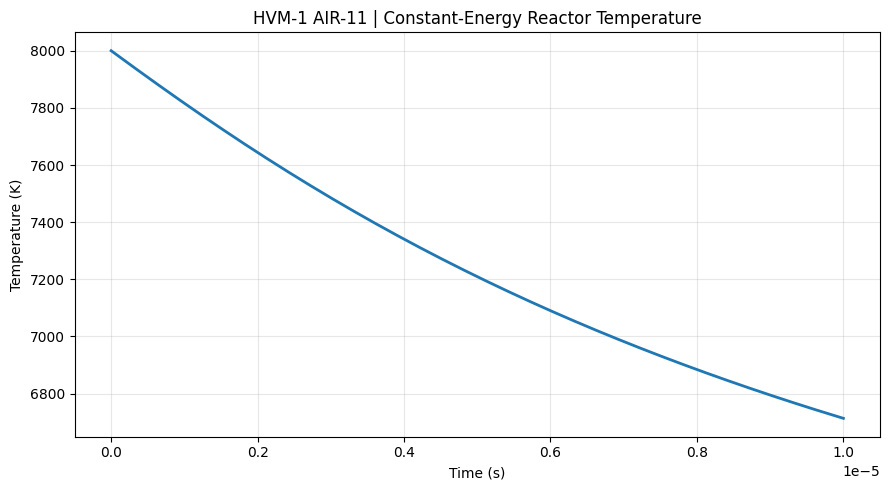

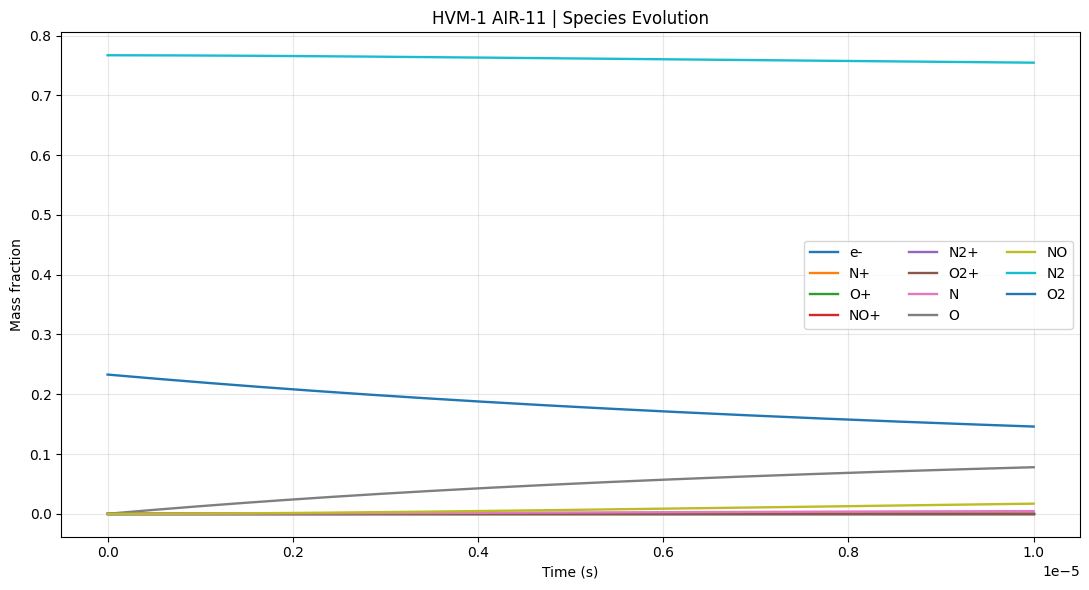

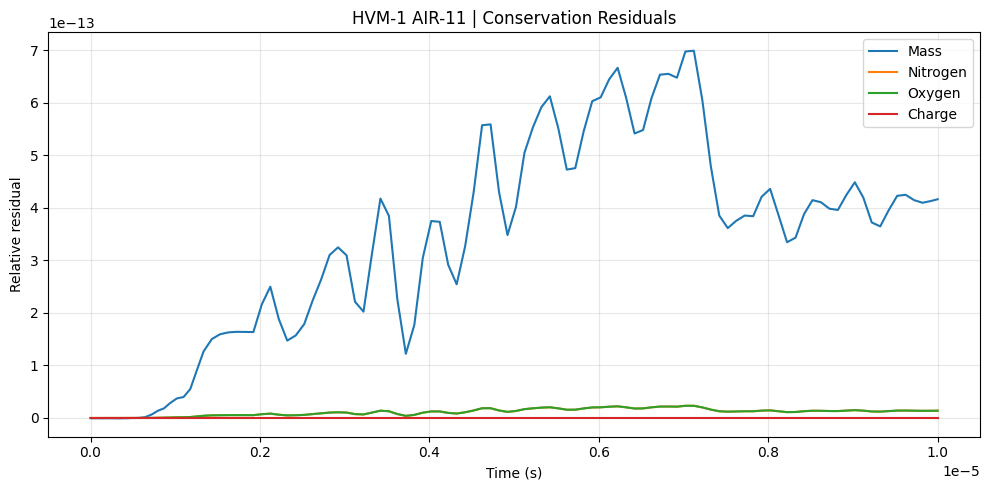


HVM-1 | AIR-11 REACTOR RESULTS
Initial T: 8000.00000000 K
Final T:   6713.39880108 K

Initial density: 1.000000000000e-03 kg/m^3
Final density:   1.000000000000e-03 kg/m^3

Maximum absolute conservation residuals:
Mass:     6.98659880e-13
Nitrogen: 2.32730502e-14
Oxygen:   2.32869279e-14
Charge:   2.18375682e-22

Minimum raw species density: 0.0
Negative solver entries: 0

Final species mass fractions:
   e-: 1.862173544956e-10
   N+: 7.482791325920e-10
   O+: 5.310308094021e-09
  NO+: 8.977293673692e-06
  N2+: 1.604120625617e-08
  O2+: 1.257778823238e-06
    N: 4.487586568853e-03
    O: 7.791657036804e-02
   NO: 1.696116574329e-02
   N2: 7.546733057456e-01
   O2: 1.459511142157e-01

Artifacts:
/content/HVM1_AIR11_ZERO_D/air11_reactor_history.csv
/content/HVM1_AIR11_ZERO_D/temperature_history.png
/content/HVM1_AIR11_ZERO_D/species_mass_fractions.png
/content/HVM1_AIR11_ZERO_D/conservation_residuals.png
/content/HVM1_AIR11_ZERO_D/reactor_report.json

HVM-1 REACTOR EXECUTION FINISHED


In [ ]:

# =============================================================================
# HVM-1 | AIR-11 REACTOR EXECUTION
# Uses previously compiled Mutation++ C++ bridge.
# No recompilation required.
# =============================================================================

import ctypes
import json
import time
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

# -----------------------------------------------------------------------------
# 1. CONFIGURATION
# -----------------------------------------------------------------------------

ROOT = Path("/content/hypersonic_air")
INSTALL = ROOT / "install"
LIBDIR = INSTALL / "lib"

OUT = Path("/content/HVM1_AIR11_ZERO_D")
SO_FILE = OUT / "libhvm_air11_bridge.so"
MECHANISM = ROOT / "Mutationpp/data/mechanisms/air11_Park.xml"

SPECIES = [
    "e-", "N+", "O+", "NO+", "N2+", "O2+",
    "N", "O", "NO", "N2", "O2"
]

NS = len(SPECIES)

T0 = 8000.0
RHO0 = 1.0e-3

X_N2 = 0.79
X_O2 = 0.21

T_END = 1.0e-5
RTOL = 1.0e-7
ATOL = 1.0e-16
MAX_STEP = T_END / 100.0

if not SO_FILE.exists():
    raise FileNotFoundError("Compiled bridge not found.")

if not MECHANISM.exists():
    raise FileNotFoundError("AIR-11 mechanism not found.")

mechanism_sha256 = hashlib.sha256(
    MECHANISM.read_bytes()
).hexdigest()

# -----------------------------------------------------------------------------
# 2. LOAD AND CONFIGURE BRIDGE
# -----------------------------------------------------------------------------

bridge = ctypes.CDLL(str(SO_FILE))

double_ptr = ctypes.POINTER(ctypes.c_double)
char_ptr = ctypes.POINTER(ctypes.c_char)

bridge.hvm_initialize.argtypes = [
    double_ptr,
    ctypes.c_double,
    double_ptr,
    double_ptr,
    char_ptr,
    ctypes.c_int
]
bridge.hvm_initialize.restype = ctypes.c_int

bridge.hvm_rhs.argtypes = [
    double_ptr,
    ctypes.c_double,
    double_ptr,
    char_ptr,
    ctypes.c_int
]
bridge.hvm_rhs.restype = ctypes.c_int

bridge.hvm_temperature.argtypes = [
    double_ptr,
    ctypes.c_double,
    double_ptr,
    char_ptr,
    ctypes.c_int
]
bridge.hvm_temperature.restype = ctypes.c_int

bridge.hvm_species_count.restype = ctypes.c_int

print("=" * 88)
print("HVM-1 | AIR-11 REACTOR INITIALIZATION")
print("=" * 88)

# -----------------------------------------------------------------------------
# 3. INITIALIZE MOLECULAR WEIGHTS
# -----------------------------------------------------------------------------

mw = np.zeros(NS, dtype=np.float64)

placeholder = np.zeros(NS, dtype=np.float64)
placeholder[SPECIES.index("N2")] = RHO0

energy = np.zeros(1, dtype=np.float64)
error = ctypes.create_string_buffer(2048)

status = bridge.hvm_initialize(
    placeholder.ctypes.data_as(double_ptr),
    T0,
    mw.ctypes.data_as(double_ptr),
    energy.ctypes.data_as(double_ptr),
    error,
    len(error)
)

if status != 0:
    raise RuntimeError(
        "Mutation++ initialization failed: " +
        error.value.decode()
    )

if bridge.hvm_species_count() != NS:
    raise RuntimeError(
        f"Expected {NS} species; got {bridge.hvm_species_count()}"
    )

if np.any(~np.isfinite(mw)) or np.any(mw <= 0):
    raise RuntimeError("Invalid molecular weights.")

# -----------------------------------------------------------------------------
# 4. CONSTRUCT INITIAL AIR COMPOSITION
# -----------------------------------------------------------------------------

x0 = np.zeros(NS, dtype=np.float64)

x0[SPECIES.index("N2")] = X_N2
x0[SPECIES.index("O2")] = X_O2

mean_mw = np.sum(x0 * mw)

if mean_mw <= 0:
    raise RuntimeError("Invalid initial mean molecular weight.")

y0 = x0 * mw / mean_mw
rho0 = RHO0 * y0

# Initialize actual mixture and obtain conserved internal energy density.
status = bridge.hvm_initialize(
    rho0.ctypes.data_as(double_ptr),
    T0,
    mw.ctypes.data_as(double_ptr),
    energy.ctypes.data_as(double_ptr),
    error,
    len(error)
)

if status != 0:
    raise RuntimeError(
        "Initial mixture setup failed: " +
        error.value.decode()
    )

E0 = float(energy[0])

print("Species count:", bridge.hvm_species_count())
print("Mechanism SHA256:", mechanism_sha256)
print(f"Initial temperature: {T0:.6f} K")
print(f"Initial density: {RHO0:.8e} kg/m^3")
print(f"Initial energy density: {E0:.12e} J/m^3")

print("\nInitial composition:")
for name, value in zip(SPECIES, y0):
    if value > 0:
        print(f"{name:>5s}: Y = {value:.12e}")

# -----------------------------------------------------------------------------
# 5. CONSERVATION MATRIX
# -----------------------------------------------------------------------------

# Rows: N atoms, O atoms, electric charge.
# Columns: AIR-11 species ordering.

COMPOSITION = np.array([
    [0, 1, 0, 1, 2, 0, 1, 0, 1, 2, 0],
    [0, 0, 1, 1, 0, 2, 0, 1, 1, 0, 2],
    [-1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
], dtype=np.float64)

# -----------------------------------------------------------------------------
# 6. CHEMISTRY RHS
# -----------------------------------------------------------------------------

rhs_calls = 0

def chemistry_rhs(t, rho):
    global rhs_calls

    rho = np.asarray(rho, dtype=np.float64)
    rho_safe = np.maximum(rho, 0.0)

    rates = np.zeros(NS, dtype=np.float64)
    err = ctypes.create_string_buffer(2048)

    status = bridge.hvm_rhs(
        rho_safe.ctypes.data_as(double_ptr),
        E0,
        rates.ctypes.data_as(double_ptr),
        err,
        len(err)
    )

    if status != 0:
        raise RuntimeError(
            f"Mutation++ RHS error at t={t:.8e}: " +
            err.value.decode()
        )

    rhs_calls += 1

    return rates

# -----------------------------------------------------------------------------
# 7. STIFF BDF INTEGRATION
# -----------------------------------------------------------------------------

print("\n" + "=" * 88)
print("HVM-1 | BDF CHEMISTRY INTEGRATION")
print("=" * 88)

start = time.time()

sol = solve_ivp(
    chemistry_rhs,
    (0.0, T_END),
    rho0,
    method="BDF",
    rtol=RTOL,
    atol=ATOL,
    max_step=MAX_STEP
)

elapsed = time.time() - start

print("Success:", sol.success)
print("Message:", sol.message)
print("Function evaluations:", sol.nfev)
print("Jacobian evaluations:", sol.njev)
print("LU decompositions:", sol.nlu)
print("RHS calls:", rhs_calls)
print(f"Elapsed time: {elapsed:.4f} s")

if not sol.success:
    raise RuntimeError("BDF integration failed: " + sol.message)

# -----------------------------------------------------------------------------
# 8. RECONSTRUCT STATE HISTORY
# -----------------------------------------------------------------------------

t = sol.t
rho_raw = sol.y.T

rho = np.maximum(rho_raw, 0.0)

density = np.sum(rho, axis=1)

if np.any(density <= 0):
    raise RuntimeError("Non-positive mixture density.")

Y = rho / density[:, None]

T = np.zeros(len(t), dtype=np.float64)

for j in range(len(t)):
    Tout = np.zeros(1, dtype=np.float64)
    err = ctypes.create_string_buffer(2048)

    status = bridge.hvm_temperature(
        rho[j].astype(np.float64).ctypes.data_as(double_ptr),
        E0,
        Tout.ctypes.data_as(double_ptr),
        err,
        len(err)
    )

    if status != 0:
        raise RuntimeError(
            f"Temperature reconstruction failed at sample {j}: " +
            err.value.decode()
        )

    T[j] = Tout[0]

# -----------------------------------------------------------------------------
# 9. CONSERVATION DIAGNOSTICS
# -----------------------------------------------------------------------------

# Mass conservation
mass_res = (density - density[0]) / max(abs(density[0]), 1e-300)

# Molar concentrations, mol/m^3
concentration = rho / mw[None, :]

# Elemental and charge inventories
inventory = concentration @ COMPOSITION.T
inventory0 = inventory[0]

N_scale = max(abs(inventory0[0]), 1.0)
O_scale = max(abs(inventory0[1]), 1.0)
charge_scale = max(np.sum(concentration[0]), 1.0)

N_res = (inventory[:, 0] - inventory0[0]) / N_scale
O_res = (inventory[:, 1] - inventory0[1]) / O_scale
charge_res = (inventory[:, 2] - inventory0[2]) / charge_scale

minimum_raw_density = float(np.min(rho_raw))
negative_entries = int(np.sum(rho_raw < 0))

# The energy density is imposed as a fixed constraint in this model.
# It is not an independently integrated conservation equation.
energy_constraint_res = np.zeros_like(t)

# -----------------------------------------------------------------------------
# 10. HISTORY DATAFRAME
# -----------------------------------------------------------------------------

data = {
    "time_s": t,
    "temperature_K": T,
    "density_kg_m3": density,
    "mass_residual": mass_res,
    "nitrogen_residual": N_res,
    "oxygen_residual": O_res,
    "charge_residual": charge_res
}

for i, name in enumerate(SPECIES):
    data[f"rho_{name}_kg_m3"] = rho_raw[:, i]
    data[f"Y_{name}"] = Y[:, i]

df = pd.DataFrame(data)

csv_path = OUT / "air11_reactor_history.csv"
df.to_csv(csv_path, index=False)

# -----------------------------------------------------------------------------
# 11. TEMPERATURE PLOT
# -----------------------------------------------------------------------------

plt.figure(figsize=(9, 5))
plt.plot(t, T, linewidth=2)
plt.xlabel("Time (s)")
plt.ylabel("Temperature (K)")
plt.title("HVM-1 AIR-11 | Constant-Energy Reactor Temperature")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "temperature_history.png", dpi=180)
plt.show()

# -----------------------------------------------------------------------------
# 12. SPECIES MASS FRACTION PLOT
# -----------------------------------------------------------------------------

plt.figure(figsize=(11, 6))

for i, name in enumerate(SPECIES):
    if np.max(Y[:, i]) > 1e-12:
        plt.plot(t, Y[:, i], label=name, linewidth=1.7)

plt.xlabel("Time (s)")
plt.ylabel("Mass fraction")
plt.title("HVM-1 AIR-11 | Species Evolution")
plt.grid(True, alpha=0.3)
plt.legend(ncol=3)
plt.tight_layout()
plt.savefig(OUT / "species_mass_fractions.png", dpi=180)
plt.show()

# -----------------------------------------------------------------------------
# 13. CONSERVATION PLOT
# -----------------------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(t, mass_res, label="Mass")
plt.plot(t, N_res, label="Nitrogen")
plt.plot(t, O_res, label="Oxygen")
plt.plot(t, charge_res, label="Charge")

plt.xlabel("Time (s)")
plt.ylabel("Relative residual")
plt.title("HVM-1 AIR-11 | Conservation Residuals")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "conservation_residuals.png", dpi=180)
plt.show()

# -----------------------------------------------------------------------------
# 14. REPORT
# -----------------------------------------------------------------------------

species_report = {}

for i, name in enumerate(SPECIES):
    species_report[name] = {
        "initial_mass_fraction": float(Y[0, i]),
        "final_mass_fraction": float(Y[-1, i]),
        "final_density_kg_m3": float(rho[-1, i])
    }

report = {
    "project": "HVM-1",
    "model": "AIR-11 constant-energy homogeneous reactor",
    "state_model": "ChemNonEq1T",
    "mechanism_sha256": mechanism_sha256,
    "initial_temperature_K": T0,
    "initial_density_kg_m3": RHO0,
    "initial_energy_density_J_m3": E0,
    "integration": {
        "method": "BDF",
        "time_end_s": T_END,
        "rtol": RTOL,
        "atol": ATOL,
        "max_step_s": MAX_STEP,
        "success": bool(sol.success),
        "nfev": int(sol.nfev),
        "njev": int(sol.njev),
        "nlu": int(sol.nlu),
        "rhs_calls": int(rhs_calls),
        "wall_time_s": float(elapsed)
    },
    "diagnostics": {
        "maximum_absolute_mass_residual": float(np.max(np.abs(mass_res))),
        "maximum_absolute_nitrogen_residual": float(np.max(np.abs(N_res))),
        "maximum_absolute_oxygen_residual": float(np.max(np.abs(O_res))),
        "maximum_absolute_charge_residual": float(np.max(np.abs(charge_res))),
        "minimum_raw_species_density_kg_m3": minimum_raw_density,
        "negative_solver_entries": negative_entries
    },
    "final_temperature_K": float(T[-1]),
    "final_density_kg_m3": float(density[-1]),
    "species": species_report,
    "qualification_note": (
        "Numerical reactor demonstration. Constant energy is imposed "
        "through the state reconstruction; it is not independently "
        "integrated. Negative solver trial states are clipped before "
        "Mutation++ RHS evaluation. Not empirical or CFD validation."
    )
}

report_path = OUT / "reactor_report.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

# -----------------------------------------------------------------------------
# 15. FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 88)
print("HVM-1 | AIR-11 REACTOR RESULTS")
print("=" * 88)

print(f"Initial T: {T[0]:.8f} K")
print(f"Final T:   {T[-1]:.8f} K")

print(f"\nInitial density: {density[0]:.12e} kg/m^3")
print(f"Final density:   {density[-1]:.12e} kg/m^3")

print("\nMaximum absolute conservation residuals:")
print(f"Mass:     {np.max(np.abs(mass_res)):.8e}")
print(f"Nitrogen: {np.max(np.abs(N_res)):.8e}")
print(f"Oxygen:   {np.max(np.abs(O_res)):.8e}")
print(f"Charge:   {np.max(np.abs(charge_res)):.8e}")

print("\nMinimum raw species density:", minimum_raw_density)
print("Negative solver entries:", negative_entries)

print("\nFinal species mass fractions:")
for name, value in zip(SPECIES, Y[-1]):
    print(f"{name:>5s}: {value:.12e}")

print("\nArtifacts:")
for name in [
    "air11_reactor_history.csv",
    "temperature_history.png",
    "species_mass_fractions.png",
    "conservation_residuals.png",
    "reactor_report.json"
]:
    print(OUT / name)

print("\nHVM-1 REACTOR EXECUTION FINISHED")


What the chemistry calculation shows
The gas cooled by approximately 1,286.6 K while maintaining the imposed constant internal-energy constraint. The final composition shows substantial dissociation and some NO formation.
The ionized species remain minor in mass fraction. That is not surprising: electrons contribute very little mass, and ionization is not the dominant mass-transfer process in this particular calculation.

In [ ]:

# =============================================================================
# HVM-1 | AIR-11 REACTOR NUMERICAL CONVERGENCE STUDY
# Reuses the compiled Mutation++ bridge.
# =============================================================================

import ctypes
import json
import time
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp

ROOT = Path("/content/hypersonic_air")
OUT = Path("/content/HVM1_AIR11_ZERO_D")
SO_FILE = OUT / "libhvm_air11_bridge.so"
MECHANISM = ROOT / "Mutationpp/data/mechanisms/air11_Park.xml"

SPECIES = [
    "e-", "N+", "O+", "NO+", "N2+", "O2+",
    "N", "O", "NO", "N2", "O2"
]
NS = len(SPECIES)

T0 = 8000.0
RHO0 = 1.0e-3
X_N2 = 0.79
X_O2 = 0.21
T_END = 1.0e-5

COMPOSITION = np.array([
    [0, 1, 0, 1, 2, 0, 1, 0, 1, 2, 0],
    [0, 0, 1, 1, 0, 2, 0, 1, 1, 0, 2],
    [-1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
], dtype=float)

# Three numerical configurations.
CASES = [
    {
        "name": "baseline",
        "rtol": 1e-7,
        "atol": 1e-16,
        "max_step": T_END / 100
    },
    {
        "name": "refined",
        "rtol": 1e-9,
        "atol": 1e-18,
        "max_step": T_END / 200
    },
    {
        "name": "high_refinement",
        "rtol": 1e-10,
        "atol": 1e-19,
        "max_step": T_END / 400
    }
]

if not SO_FILE.exists():
    raise FileNotFoundError(SO_FILE)

bridge = ctypes.CDLL(str(SO_FILE))

double_ptr = ctypes.POINTER(ctypes.c_double)
char_ptr = ctypes.POINTER(ctypes.c_char)

bridge.hvm_initialize.argtypes = [
    double_ptr, ctypes.c_double,
    double_ptr, double_ptr,
    char_ptr, ctypes.c_int
]
bridge.hvm_initialize.restype = ctypes.c_int

bridge.hvm_rhs.argtypes = [
    double_ptr, ctypes.c_double,
    double_ptr, char_ptr, ctypes.c_int
]
bridge.hvm_rhs.restype = ctypes.c_int

bridge.hvm_species_count.restype = ctypes.c_int

def initialize_case():
    mw = np.zeros(NS, dtype=np.float64)
    energy = np.zeros(1, dtype=np.float64)
    error = ctypes.create_string_buffer(2048)

    placeholder = np.zeros(NS, dtype=np.float64)
    placeholder[SPECIES.index("N2")] = RHO0

    status = bridge.hvm_initialize(
        placeholder.ctypes.data_as(double_ptr),
        T0,
        mw.ctypes.data_as(double_ptr),
        energy.ctypes.data_as(double_ptr),
        error,
        len(error)
    )

    if status != 0:
        raise RuntimeError(error.value.decode())

    if bridge.hvm_species_count() != NS:
        raise RuntimeError("AIR-11 species count mismatch.")

    x0 = np.zeros(NS)
    x0[SPECIES.index("N2")] = X_N2
    x0[SPECIES.index("O2")] = X_O2

    mean_mw = np.sum(x0 * mw)
    y0 = x0 * mw / mean_mw
    rho0 = RHO0 * y0

    status = bridge.hvm_initialize(
        rho0.astype(np.float64).ctypes.data_as(double_ptr),
        T0,
        mw.ctypes.data_as(double_ptr),
        energy.ctypes.data_as(double_ptr),
        error,
        len(error)
    )

    if status != 0:
        raise RuntimeError(error.value.decode())

    return mw, rho0, float(energy[0])

def run_case(config):
    mw, rho0, E0 = initialize_case()

    rhs_calls = 0

    def rhs(t, rho):
        nonlocal rhs_calls

        rho_safe = np.maximum(
            np.asarray(rho, dtype=np.float64), 0.0
        )

        rates = np.zeros(NS, dtype=np.float64)
        error = ctypes.create_string_buffer(2048)

        status = bridge.hvm_rhs(
            rho_safe.ctypes.data_as(double_ptr),
            E0,
            rates.ctypes.data_as(double_ptr),
            error,
            len(error)
        )

        if status != 0:
            raise RuntimeError(
                f"{config['name']} RHS failure: "
                + error.value.decode()
            )

        rhs_calls += 1
        return rates

    start = time.time()

    sol = solve_ivp(
        rhs,
        (0.0, T_END),
        rho0,
        method="BDF",
        rtol=config["rtol"],
        atol=config["atol"],
        max_step=config["max_step"]
    )

    elapsed = time.time() - start

    if not sol.success:
        raise RuntimeError(
            f"{config['name']} integration failed: {sol.message}"
        )

    rho_raw = sol.y.T
    rho = np.maximum(rho_raw, 0.0)

    density = rho.sum(axis=1)
    Y = rho / density[:, None]
    concentration = rho / mw[None, :]

    inventory = concentration @ COMPOSITION.T
    inventory0 = inventory[0]

    N_scale = max(abs(inventory0[0]), 1.0)
    O_scale = max(abs(inventory0[1]), 1.0)
    charge_scale = max(concentration[0].sum(), 1.0)

    residuals = {
        "mass": float(np.max(
            np.abs((density-density[0])/density[0])
        )),
        "nitrogen": float(np.max(
            np.abs((inventory[:,0]-inventory0[0])/N_scale)
        )),
        "oxygen": float(np.max(
            np.abs((inventory[:,1]-inventory0[1])/O_scale)
        )),
        "charge": float(np.max(
            np.abs((inventory[:,2]-inventory0[2])/charge_scale)
        ))
    }

    # Reconstruct temperature at final state.
    final_temperature = np.zeros(1, dtype=np.float64)
    error = ctypes.create_string_buffer(2048)

    bridge.hvm_temperature.argtypes = [
        double_ptr, ctypes.c_double,
        double_ptr, char_ptr, ctypes.c_int
    ]
    bridge.hvm_temperature.restype = ctypes.c_int

    status = bridge.hvm_temperature(
        rho[-1].astype(np.float64).ctypes.data_as(double_ptr),
        E0,
        final_temperature.ctypes.data_as(double_ptr),
        error,
        len(error)
    )

    if status != 0:
        raise RuntimeError(error.value.decode())

    return {
        "name": config["name"],
        "time": sol.t,
        "rho": rho,
        "Y": Y,
        "mw": mw,
        "temperature": float(final_temperature[0]),
        "density": float(density[-1]),
        "residuals": residuals,
        "nfev": int(sol.nfev),
        "njev": int(sol.njev),
        "nlu": int(sol.nlu),
        "rhs_calls": int(rhs_calls),
        "elapsed": float(elapsed),
        "negative_entries": int(np.sum(rho_raw < 0)),
        "minimum_raw_density": float(np.min(rho_raw)),
        "energy_density": E0
    }

# -----------------------------------------------------------------------------
# RUN ALL THREE CASES SEQUENTIALLY
# -----------------------------------------------------------------------------

print("=" * 88)
print("HVM-1 | AIR-11 CONVERGENCE STUDY")
print("=" * 88)

results = []

for config in CASES:
    print(f"\nRunning: {config['name']}")
    print("rtol:", config["rtol"])
    print("atol:", config["atol"])
    print("max_step:", config["max_step"])

    result = run_case(config)
    results.append(result)

    print("Success")
    print("Final temperature:", result["temperature"])
    print("Final density:", result["density"])
    print("Function evaluations:", result["nfev"])
    print("Wall time:", result["elapsed"])
    print("Residuals:", result["residuals"])

# -----------------------------------------------------------------------------
# COMPARE FINAL STATES
# -----------------------------------------------------------------------------

baseline = results[0]
refined = results[1]
high = results[2]

rows = []

for result in results:
    rows.append({
        "case": result["name"],
        "rtol": CASES[len(rows)]["rtol"],
        "atol": CASES[len(rows)]["atol"],
        "max_step_s": CASES[len(rows)]["max_step"],
        "final_temperature_K": result["temperature"],
        "final_density_kg_m3": result["density"],
        "mass_residual": result["residuals"]["mass"],
        "nitrogen_residual": result["residuals"]["nitrogen"],
        "oxygen_residual": result["residuals"]["oxygen"],
        "charge_residual": result["residuals"]["charge"],
        "nfev": result["nfev"],
        "wall_time_s": result["elapsed"],
        "negative_entries": result["negative_entries"]
    })

summary = pd.DataFrame(rows)

print("\n" + "=" * 88)
print("CONVERGENCE SUMMARY")
print("=" * 88)
display(summary)

# Relative/absolute differences from baseline.
comparison = []

for result in results[1:]:
    delta_T = result["temperature"] - baseline["temperature"]

    delta_Y = result["Y"][-1] - baseline["Y"][-1]

    comparison.append({
        "case": result["name"],
        "temperature_difference_K": delta_T,
        "temperature_relative_difference": (
            delta_T / baseline["temperature"]
        ),
        "maximum_absolute_species_fraction_difference": (
            np.max(np.abs(delta_Y))
        ),
        "species_fraction_L1_difference": (
            np.sum(np.abs(delta_Y))
        )
    })

comparison_df = pd.DataFrame(comparison)

print("\nDifference relative to baseline:")
display(comparison_df)

# -----------------------------------------------------------------------------
# SAVE ARTIFACTS
# -----------------------------------------------------------------------------

summary.to_csv(
    OUT / "convergence_summary.csv",
    index=False
)

comparison_df.to_csv(
    OUT / "convergence_comparison.csv",
    index=False
)

convergence_report = {
    "mechanism_sha256": hashlib.sha256(
        MECHANISM.read_bytes()
    ).hexdigest(),
    "cases": rows,
    "comparisons_to_baseline": comparison,
    "species_order": SPECIES,
    "interpretation": (
        "Numerical convergence comparison only. Agreement between "
        "solver configurations does not establish experimental validity."
    )
}

with open(OUT / "convergence_report.json", "w") as f:
    json.dump(convergence_report, f, indent=2)

print("\nSaved:")
print(OUT / "convergence_summary.csv")
print(OUT / "convergence_comparison.csv")
print(OUT / "convergence_report.json")

print("\nHVM-1 CONVERGENCE STUDY COMPLETE")


HVM-1 | AIR-11 CONVERGENCE STUDY

Running: baseline
rtol: 1e-07
atol: 1e-16
max_step: 1.0000000000000001e-07
Success
Final temperature: 6713.398801087279
Final density: 0.0010000000000004161
Function evaluations: 287
Wall time: 0.24162554740905762
Residuals: {'mass': 6.986598799496591e-13, 'nitrogen': 2.3273050153704844e-14, 'oxygen': 2.328692794151266e-14, 'charge': 2.183756817139993e-22}

Running: refined
rtol: 1e-09
atol: 1e-18
max_step: 5.0000000000000004e-08
Success
Final temperature: 6713.398807658865
Final density: 0.0010000000000000026
Function evaluations: 893
Wall time: 0.4224357604980469
Residuals: {'mass': 2.8189256484623115e-15, 'nitrogen': 9.71445146547012e-17, 'oxygen': 9.540979117872439e-17, 'charge': 2.9116757561866574e-22}

Running: high_refinement
rtol: 1e-10
atol: 1e-19
max_step: 2.5000000000000002e-08
Success
Final temperature: 6713.3988047877665
Final density: 0.0009999999999999987
Function evaluations: 1382
Wall time: 0.6073260307312012
Residuals: {'mass': 1.7347

,case,rtol,atol,max_step_s,final_temperature_K,final_density_kg_m3,mass_residual,nitrogen_residual,oxygen_residual,charge_residual,nfev,wall_time_s,negative_entries
0,baseline,1.000000e-07,1.000000e-16,1.000000e-07,6713.398801,0.001,6.986599e-13,2.327305e-14,2.328693e-14,2.183757e-22,287,0.241626,0
1,refined,1.000000e-09,1.000000e-18,5.000000e-08,6713.398808,0.001,2.818926e-15,9.714451e-17,9.540979e-17,2.911676e-22,893,0.422436,0
2,high_refinement,1.000000e-10,1.000000e-19,2.500000e-08,6713.398805,0.001,1.734723e-15,1.179612e-16,1.387779e-17,2.845501e-22,1382,0.607326,0



Difference relative to baseline:


,case,temperature_difference_K,temperature_relative_difference,maximum_absolute_species_fraction_difference,species_fraction_L1_difference
0,refined,0.000007,9.788761e-10,5.856744e-10,1.434317e-09
1,high_refinement,0.000004,5.512092e-10,3.983637e-10,1.014067e-09



Saved:
/content/HVM1_AIR11_ZERO_D/convergence_summary.csv
/content/HVM1_AIR11_ZERO_D/convergence_comparison.csv
/content/HVM1_AIR11_ZERO_D/convergence_report.json

HVM-1 CONVERGENCE STUDY COMPLETE


In [ ]:

# =============================================================================
# HVM-1 | MUTATION++ MULTITEMPERATURE API DISCOVERY
# Determine supported temperature models before building the next reactor.
# =============================================================================

from pathlib import Path
import re

ROOT = Path("/content/hypersonic_air/Mutationpp")
INSTALL = Path("/content/hypersonic_air/install")

SEARCH_ROOTS = [
    ROOT / "src",
    ROOT / "include",
    ROOT / "docs",
    ROOT / "examples",
    INSTALL / "include"
]

PATTERNS = [
    "ChemNonEq1T",
    "ChemNonEq2T",
    "ChemNonEq3T",
    "ChemNonEqTTv",
    "ChemNonEq",
    "nEnergyEqns",
    "setState(",
    "Tv()",
    "Te()",
    "vibrationalEnergy",
    "electronEnergy",
    "energyTransfer",
    "energyExchange"
]

EXTENSIONS = {".h", ".hpp", ".cpp", ".xml", ".md", ".txt"}

print("=" * 88)
print("HVM-1 | MULTITEMPERATURE API DISCOVERY")
print("=" * 88)

# -----------------------------------------------------------------------------
# 1. SEARCH INSTALLED SOURCE AND HEADERS
# -----------------------------------------------------------------------------

matches = {pattern: [] for pattern in PATTERNS}

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file() or path.suffix not in EXTENSIONS:
            continue

        try:
            lines = path.read_text(
                encoding="utf-8",
                errors="ignore"
            ).splitlines()
        except Exception:
            continue

        for line_number, line in enumerate(lines, start=1):
            for pattern in PATTERNS:
                if pattern.lower() in line.lower():
                    matches[pattern].append(
                        (path, line_number, line.strip())
                    )

# -----------------------------------------------------------------------------
# 2. REPORT MODEL NAMES
# -----------------------------------------------------------------------------

print("\n[1] STATE MODEL REFERENCES")

for pattern in [
    "ChemNonEq1T",
    "ChemNonEq2T",
    "ChemNonEq3T",
    "ChemNonEqTTv",
    "ChemNonEq"
]:
    print(f"\n--- {pattern} ---")

    entries = matches[pattern][:35]

    if not entries:
        print("No references found.")
        continue

    for path, line, content in entries:
        print(f"{path}:{line}: {content}")

# -----------------------------------------------------------------------------
# 3. ENERGY EQUATION INTERFACE
# -----------------------------------------------------------------------------

print("\n\n[2] ENERGY EQUATION INTERFACE")

for pattern in [
    "nEnergyEqns",
    "vibrationalEnergy",
    "electronEnergy",
    "energyTransfer",
    "energyExchange"
]:
    print(f"\n--- {pattern} ---")

    entries = matches[pattern][:25]

    if not entries:
        print("No references found.")
        continue

    for path, line, content in entries:
        print(f"{path}:{line}: {content}")

# -----------------------------------------------------------------------------
# 4. TEMPERATURE AND STATE INTERFACE
# -----------------------------------------------------------------------------

print("\n\n[3] TEMPERATURE AND STATE INTERFACE")

for pattern in ["setState(", "Tv()", "Te()"]:
    print(f"\n--- {pattern} ---")

    entries = matches[pattern][:30]

    if not entries:
        print("No references found.")
        continue

    for path, line, content in entries:
        print(f"{path}:{line}: {content}")

# -----------------------------------------------------------------------------
# 5. PRINT CORE PUBLIC HEADERS
# -----------------------------------------------------------------------------

CORE_HEADERS = [
    INSTALL / "include/mutation++/StateModel.h",
    INSTALL / "include/mutation++/Mixture.h",
    INSTALL / "include/mutation++/MixtureOptions.h",
    INSTALL / "include/mutation++/Kinetics.h",
    INSTALL / "include/mutation++/Thermodynamics.h"
]

print("\n\n[4] CORE PUBLIC API HEADERS")

for path in CORE_HEADERS:
    print("\n" + "=" * 88)
    print(path)

    if not path.exists():
        print("NOT FOUND")
        continue

    lines = path.read_text(
        encoding="utf-8",
        errors="ignore"
    ).splitlines()

    if path.name == "StateModel.h":
        selected = range(min(len(lines), 260))
    elif path.name == "MixtureOptions.h":
        selected = range(min(len(lines), 220))
    else:
        selected = range(min(len(lines), 170))

    for i in selected:
        print(f"{i+1:04d}: {lines[i]}")

# -----------------------------------------------------------------------------
# 6. SAVE DISCOVERY REPORT
# -----------------------------------------------------------------------------

report_path = Path(
    "/content/HVM1_AIR11_ZERO_D/multitemperature_api_discovery.txt"
)

with open(report_path, "w") as f:
    for pattern, entries in matches.items():
        f.write(f"\n{'='*80}\n{pattern}\n{'='*80}\n")

        for path, line, content in entries:
            f.write(f"{path}:{line}: {content}\n")

print("\nDiscovery report saved:")
print(report_path)

print("\nMULTITEMPERATURE API DISCOVERY COMPLETE")


HVM-1 | MULTITEMPERATURE API DISCOVERY

[1] STATE MODEL REFERENCES

--- ChemNonEq1T ---
/content/hypersonic_air/Mutationpp/src/general/MixtureOptions.cpp:83: m_state_model = "ChemNonEq1T";
/content/hypersonic_air/Mutationpp/src/thermo/ChemNonEqStateModel.cpp:202: ChemNonEqStateModel, StateModel> chem_non_eq_1T("ChemNonEq1T");
/content/hypersonic_air/Mutationpp/docs/testing.md:155: air5_RRHO_ChemNonEq1T
/content/hypersonic_air/Mutationpp/docs/input-files.md:121: `state_model`          | __ChemNonEq1T__, `ChemNonEqTTv`, `Equil`, `EquilTP` | choice of [state model](#statemodels)
/content/hypersonic_air/Mutationpp/examples/python/Mars_adiabatic_reactor.md:69: opts.setStateModel("ChemNonEq1T")
/content/hypersonic_air/Mutationpp/examples/python/Air11_isothermal_reactor.md:71: opts.setStateModel("ChemNonEq1T")
/content/hypersonic_air/Mutationpp/examples/python/Air11_adiabatic_reactor.md:110: opts.setStateModel("ChemNonEq1T")
/content/hypersonic_air/Mutationpp/examples/c++/O2_dissociation/O2_d

In [ ]:
from pathlib import Path

ROOT = Path("/content/hypersonic_air/Mutationpp")

FILES = {
    "ChemNonEqTTvStateModel.cpp":
        ROOT / "src/thermo/ChemNonEqTTvStateModel.cpp",

    "ChemNonEqStateModel.cpp":
        ROOT / "src/thermo/ChemNonEqStateModel.cpp",

    "StateModel.h":
        ROOT / "src/thermo/StateModel.h",

    "Thermodynamics.h":
        ROOT / "src/thermo/Thermodynamics.h",

    "tutorial.cpp":
        ROOT / "examples/c++/tutorial/tutorial.cpp",

    "getting-started.md":
        ROOT / "docs/getting-started.md",
}

KEYWORDS = (
    "ChemNonEqTTv",
    "setState",
    "getTemperatures",
    "getEnergiesMass",
    "energyTransferSource",
    "m_Te",
    "m_Tv",
    "m_T",
    "nenergy",
    "nEnergyEqns",
    "transfer",
    "vibrational",
    "electron",
)

print("=" * 100)
print("HVM-1 | TTv IMPLEMENTATION AND ENERGY-CLOSURE INSPECTION")
print("=" * 100)

for name, path in FILES.items():
    print(f"\n\n{'=' * 35} {name} {'=' * 35}")

    if not path.exists():
        print("NOT FOUND:", path)
        continue

    lines = path.read_text(errors="replace").splitlines()

    if name in ("ChemNonEqTTvStateModel.cpp",
                "ChemNonEqStateModel.cpp",
                "tutorial.cpp"):
        for i, line in enumerate(lines, 1):
            print(f"{i:04d}: {line}")

    else:
        hits = [
            i for i, line in enumerate(lines)
            if any(k.lower() in line.lower() for k in KEYWORDS)
        ]

        selected = set()
        for i in hits:
            selected.update(range(max(0, i-5), min(len(lines), i+9)))

        previous = -2
        for i in sorted(selected):
            if i > previous + 1:
                print("      ...")
            print(f"{i+1:04d}: {lines[i]}")
            previous = i

print("\n\nINSPECTION COMPLETE")

HVM-1 | TTv IMPLEMENTATION AND ENERGY-CLOSURE INSPECTION


=================================== ChemNonEqTTvStateModel.cpp ===================================
0001: /**
0002:  * @file ChemNonEqTTvStateModel.h
0003:  *
0004:  * @brief Provides ChemNonEqTTvStateModel.
0005:  */
0006: 
0007: /*
0008:  * Copyright 2014-2020 von Karman Institute for Fluid Dynamics (VKI)
0009:  *
0010:  * This file is part of MUlticomponent Thermodynamic And Transport
0011:  * properties for IONized gases in C++ (Mutation++) software package.
0012:  *
0013:  * Mutation++ is free software: you can redistribute it and/or modify
0014:  * it under the terms of the GNU Lesser General Public License as
0015:  * published by the Free Software Foundation, either version 3 of the
0016:  * License, or (at your option) any later version.
0017:  *
0018:  * Mutation++ is distributed in the hope that it will be useful,
0019:  * but WITHOUT ANY WARRANTY; without even the implied warranty of
0020:  * MERCHANTABILITY or FITNE

In [ ]:

from pathlib import Path
import re

ROOT = Path("/content/hypersonic_air/Mutationpp")
OUT = Path("/content/HVM1_AIR11_ZERO_D/ttv_energy_source_audit.txt")
OUT.parent.mkdir(parents=True, exist_ok=True)

patterns = [
    "energyTransferSource",
    "getEnergiesMass",
    "mixtureEnergyMass",
    "netProductionRates",
    "energySource",
    "source()",
    "productionRates",
    "m_transfer_models",
]

roots = [
    ROOT / "src",
    ROOT / "include",
    ROOT / "examples",
]

extensions = {".h", ".cpp", ".hpp", ".cc"}
matches = []

for base in roots:
    if not base.exists():
        continue

    for path in base.rglob("*"):
        if path.suffix not in extensions:
            continue

        try:
            lines = path.read_text(errors="ignore").splitlines()
        except Exception:
            continue

        hit_lines = [
            i for i, line in enumerate(lines)
            if any(p.lower() in line.lower() for p in patterns)
        ]

        if not hit_lines:
            continue

        selected = set()
        for i in hit_lines:
            selected.update(range(max(0, i-12), min(len(lines), i+19)))

        matches.append((path, lines, sorted(selected)))

with OUT.open("w") as f:
    f.write("HVM-1 | TTv ENERGY-SOURCE IMPLEMENTATION AUDIT\n")
    f.write("=" * 100 + "\n")

    for path, lines, selected in matches:
        f.write(f"\n\nFILE: {path}\n")
        f.write("-" * 100 + "\n")

        previous = -2
        for i in selected:
            if i > previous + 1:
                f.write("      ...\n")
            f.write(f"{i+1:05d}: {lines[i]}\n")
            previous = i

print(f"Matched files: {len(matches)}")
print(f"Audit saved: {OUT}")
print("\n" + OUT.read_text()[:50000])


Matched files: 21
Audit saved: /content/HVM1_AIR11_ZERO_D/ttv_energy_source_audit.txt

HVM-1 | TTv ENERGY-SOURCE IMPLEMENTATION AUDIT


FILE: /content/hypersonic_air/Mutationpp/src/apps/checkmix.cpp
----------------------------------------------------------------------------------------------------
      ...
00364:     if (argc < 2 || argc > 3) {
00365:         cout << "- checkmix mixture-name" << endl;
00366:         cout << "           or          " << endl;
00367:         cout << "- checkmix database(NASA-7, NASA-9, RRHO) species-descriptor" << endl;
00368:         exit(1);
00369:     } else if (argc == 2) {
00370:         opts.loadFromFile(argv[1]);
00371:     } else {
00372:         opts.setThermodynamicDatabase(argv[1]);
00373:         opts.setSpeciesDescriptor(argv[2]);
00374:     }
00375:     
00376:     cout << "location: " << opts.getSource() << endl;
00377: 
00378:     try {
00379:         printMixtureInfo(opts);
00380:         std::cout << "checkmix succeeded." << std::endl

In [ ]:
from pathlib import Path

ROOT = Path("/content/hypersonic_air/Mutationpp")
OUT = Path("/content/HVM1_AIR11_ZERO_D")
OUT.mkdir(exist_ok=True)

targets = {
    "ChemNonEqTTvStateModel.cpp": [
        (1, 175),
        (176, 310),
    ],
    "ChemNonEqStateModel.cpp": [
        (1, 155),
    ],
    "StateModel.h": [
        (100, 165),
        (250, 300),
    ],
    "air_11.xml": [
        (1, 240),
    ],
    "MixtureOptions.cpp": [
        (180, 330),
    ],
}

paths = {
    "ChemNonEqTTvStateModel.cpp":
        ROOT / "src/thermo/ChemNonEqTTvStateModel.cpp",
    "ChemNonEqStateModel.cpp":
        ROOT / "src/thermo/ChemNonEqStateModel.cpp",
    "StateModel.h":
        ROOT / "src/thermo/StateModel.h",
    "air_11.xml":
        ROOT / "data/mixtures/air_11.xml",
    "MixtureOptions.cpp":
        ROOT / "src/general/MixtureOptions.cpp",
}

report = []

for name, sections in targets.items():
    path = paths[name]
    report.append(f"\n{'='*90}\nFILE: {path}\n{'='*90}")

    if not path.exists():
        report.append("FILE NOT FOUND")
        continue

    lines = path.read_text(errors="replace").splitlines()

    for first, last in sections:
        report.append(f"\n--- LINES {first}-{last} ---")
        for i in range(first - 1, min(last, len(lines))):
            report.append(f"{i+1:05d}: {lines[i]}")

result = "\n".join(report)
destination = OUT / "ttv_complete_state_model_audit.txt"
destination.write_text(result)

print(result)
print(f"\n\nFull audit saved: {destination}")


FILE: /content/hypersonic_air/Mutationpp/src/thermo/ChemNonEqTTvStateModel.cpp

--- LINES 1-175 ---
00001: /**
00002:  * @file ChemNonEqTTvStateModel.h
00003:  *
00004:  * @brief Provides ChemNonEqTTvStateModel.
00005:  */
00006: 
00007: /*
00008:  * Copyright 2014-2020 von Karman Institute for Fluid Dynamics (VKI)
00009:  *
00010:  * This file is part of MUlticomponent Thermodynamic And Transport
00011:  * properties for IONized gases in C++ (Mutation++) software package.
00012:  *
00013:  * Mutation++ is free software: you can redistribute it and/or modify
00014:  * it under the terms of the GNU Lesser General Public License as
00015:  * published by the Free Software Foundation, either version 3 of the
00016:  * License, or (at your option) any later version.
00017:  *
00018:  * Mutation++ is distributed in the hope that it will be useful,
00019:  * but WITHOUT ANY WARRANTY; without even the implied warranty of
00020:  * MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the

In [ ]:
from pathlib import Path
import re

ROOT = Path("/content/hypersonic_air/Mutationpp")
OUT = Path("/content/HVM1_AIR11_ZERO_D")
OUT.mkdir(parents=True, exist_ok=True)

terms = [
    "energyTransferSource",
    "netProductionRates",
    "mixtureEnergyMass",
    "getEnergiesMass",
    "getCvsMass",
    "nEnergyEqns",
    "source()",
]

# Search implementation, public headers, examples, and solver-facing code.
roots = [
    ROOT / "src",
    ROOT / "examples",
    ROOT / "docs",
]

extensions = {".h", ".hpp", ".cpp", ".md", ".txt"}

hits = []
for base in roots:
    if not base.exists():
        continue
    for path in base.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in extensions:
            continue
        try:
            lines = path.read_text(errors="ignore").splitlines()
        except Exception:
            continue

        matched = [
            i for i, line in enumerate(lines)
            if any(term in line for term in terms)
        ]
        if not matched:
            continue

        hits.append((path, lines, matched))

report = []
report.append("=" * 100)
report.append("HVM-1 | AIR-11 TWO-TEMPERATURE ENERGY-SOURCE API AUDIT")
report.append("=" * 100)

for path, lines, matched in hits:
    report.append(f"\nFILE: {path}")
    # Merge nearby matches to avoid printing the same source repeatedly.
    ranges = []
    for i in matched:
        a, b = max(0, i - 8), min(len(lines), i + 13)
        if ranges and a <= ranges[-1][1] + 2:
            ranges[-1] = (ranges[-1][0], max(ranges[-1][1], b))
        else:
            ranges.append((a, b))

    for a, b in ranges:
        report.append(f"\n--- LINES {a+1}-{b} ---")
        for j in range(a, b):
            report.append(f"{j+1:05d}: {lines[j]}")

text = "\n".join(report)
dest = OUT / "ttv_energy_source_api_audit.txt"
dest.write_text(text)

print(text)
print("\n" + "=" * 100)
print(f"Saved: {dest}")
print(f"Files containing relevant API/source terms: {len(hits)}")

HVM-1 | AIR-11 TWO-TEMPERATURE ENERGY-SOURCE API AUDIT

FILE: /content/hypersonic_air/Mutationpp/src/transport/Transport.cpp

--- LINES 69-90 ---
00069: 
00070:     // Load the diffusion matrix calculator
00071:     setDiffusionMatrixAlgo("Ramshaw");
00072: 
00073:     // Allocate work array storage
00074:     mp_wrk1 = new double [m_thermo.nGas()*3];
00075:     mp_wrk2 = mp_wrk1 + m_thermo.nGas();
00076:     mp_wrk3 = mp_wrk2 + m_thermo.nGas();
00077:     if(m_thermo.nEnergyEqns() > 1) {
00078:         mp_tag  = new int [m_thermo.nEnergyEqns()*5];
00079:         m_thermo.getTagModes(mp_tag);
00080:     }
00081: 
00082:     //thermo.stateModel()->notifyOnUpdate(this);
00083: }
00084: 
00085: //==============================================================================
00086: 
00087: Transport::~Transport()
00088: {
00089:     delete mp_esubsyst;
00090:     delete mp_viscosity;

--- LINES 166-186 ---
00166: {
00167:     mp_thermal_conductivity->thermalDiffusionRatios(p_k);
00168: }
0

In [ ]:
from pathlib import Path

R = Path("/content/hypersonic_air/Mutationpp")
terms = [
    "energyTransferSource",
    "netProductionRates",
    "mixtureEnergyMass",
    "getEnergiesMass",
    "nEnergyEqns",
]

for folder in ["src", "examples"]:
    for p in (R / folder).rglob("*"):
        if p.suffix not in [".h", ".cpp"]:
            continue
        lines = p.read_text(errors="ignore").splitlines()
        hits = [i for i, s in enumerate(lines)
                if any(t in s for t in terms)]
        if hits:
            print(f"\n### {p}")
            shown = set()
            for i in hits:
                for j in range(max(0, i-3), min(len(lines), i+7)):
                    if j not in shown:
                        print(f"{j+1}: {lines[j]}")
                        shown.add(j)


### /content/hypersonic_air/Mutationpp/src/transport/Transport.cpp
74:     mp_wrk1 = new double [m_thermo.nGas()*3];
75:     mp_wrk2 = mp_wrk1 + m_thermo.nGas();
76:     mp_wrk3 = mp_wrk2 + m_thermo.nGas();
77:     if(m_thermo.nEnergyEqns() > 1) {
78:         mp_tag  = new int [m_thermo.nEnergyEqns()*5];
79:         m_thermo.getTagModes(mp_tag);
80:     }
81: 
82:     //thermo.stateModel()->notifyOnUpdate(this);
83: }
84: 
171: 
172: void Transport::frozenThermalConductivityVector(double* const p_lambda)
173: {
174:     const int neq = m_thermo.nEnergyEqns();
175:     double lambda_th, lambda_te, lambda_rot, lambda_vib, lambda_elec;
176: 
177:     if(neq > 1) {
178:         lambda_th   = heavyThermalConductivity();
179:         lambda_te   = electronThermalConductivity();
180:         lambda_rot  = rotationalThermalConductivity();

### /content/hypersonic_air/Mutationpp/src/apps/mppequil.cpp
824:                     if (units == "J/mol")
825:                         value = mix.mixtur

In [ ]:
from pathlib import Path
import os, subprocess

ROOT = Path("/content/hypersonic_air")
OUT = Path("/content/HVM1_AIR11_TTV")
OUT.mkdir(exist_ok=True)

src = r'''
#include "mutation++.h"
#include <vector>
#include <memory>
#include <algorithm>
#include <exception>

using namespace Mutation;

static std::unique_ptr<Mixture> mix;
static int ns = 0;
static std::string error_message;

extern "C" {

int hvm_init() {
    try {
        MixtureOptions opts("air_11");
        opts.setStateModel("ChemNonEqTTv");
        mix.reset(new Mixture(opts));
        ns = mix->nSpecies();
        return ns;
    } catch (const std::exception& e) {
        error_message = e.what();
        return -1;
    }
}

int hvm_species_mw(double* mw) {
    if (!mix) return -1;
    for (int i=0; i<ns; ++i)
        mw[i] = mix->speciesMw(i);
    return ns;
}

int hvm_primitive(const double* rho, double T, double Tv,
                  double* energy) {
    try {
        double temp[2] = {T, Tv};
        mix->setState(rho, temp, 1);
        mix->mixtureEnergies(energy);
        for (int j=0; j<2; ++j)
            energy[j] *= mix->density();
        return 0;
    } catch (const std::exception& e) {
        error_message = e.what();
        return -1;
    }
}

int hvm_rhs(const double* y, double* dydt) {
    try {
        std::vector<double> rho(ns), wdot(ns);
        for (int i=0; i<ns; ++i)
            rho[i] = std::max(y[i], 0.0);

        double energy[2] = {y[ns], y[ns+1]};
        mix->setState(rho.data(), energy, 0);
        mix->netProductionRates(wdot.data());

        double omega[1] = {0.0};
        mix->energyTransferSource(omega);

        for (int i=0; i<ns; ++i)
            dydt[i] = wdot[i];

        dydt[ns]   = 0.0;
        dydt[ns+1] = omega[0];
        return 0;
    } catch (const std::exception& e) {
        error_message = e.what();
        return -1;
    }
}

int hvm_properties(const double* y, double* p) {
    try {
        std::vector<double> rho(ns);
        for (int i=0; i<ns; ++i)
            rho[i] = std::max(y[i], 0.0);

        double energy[2] = {y[ns], y[ns+1]};
        mix->setState(rho.data(), energy, 0);

        p[0] = mix->T();
        p[1] = mix->Tv();
        p[2] = mix->P();
        p[3] = mix->density();
        return 0;
    } catch (const std::exception& e) {
        error_message = e.what();
        return -1;
    }
}

const char* hvm_error() {
    return error_message.c_str();
}

}
'''

cpp = OUT / "hvm_air11_ttv.cpp"
lib = OUT / "libhvm_air11_ttv.so"
cpp.write_text(src)

cmd = [
    "g++", "-std=c++11", "-O2", "-fPIC", "-shared",
    str(cpp),
    "-I" + str(ROOT / "install/include"),
    str(ROOT / "install/lib/libmutation++.so"),
    "-Wl,-rpath," + str(ROOT / "install/lib"),
    "-o", str(lib)
]

result = subprocess.run(cmd, capture_output=True, text=True)

print("Compilation return code:", result.returncode)
print(result.stdout)
print(result.stderr[-5000:] if result.stderr else "No compiler errors.")

if result.returncode == 0:
    print("\nBridge compiled:", lib)

Compilation return code: 1

/content/HVM1_AIR11_TTV/hvm_air11_ttv.cpp:2:10: fatal error: mutation++.h: No such file or directory
    2 | #include "mutation++.h"
      |          ^~~~~~~~~~~~~~
compilation terminated.



In [ ]:

from pathlib import Path
import subprocess

ROOT = Path("/content/hypersonic_air")
INC = ROOT / "install/include"
LIB = ROOT / "install/lib/libmutation++.so"
OUT = Path("/content/HVM1_AIR11_TTV")
OUT.mkdir(parents=True, exist_ok=True)

# Locate the actual installed header
headers = list(INC.rglob("mutation++.h"))
if not headers:
    raise FileNotFoundError(
        f"mutation++.h not found under {INC}"
    )

HEADER = headers[0]
HEADER_DIR = HEADER.parent

print("Header:", HEADER)
print("Library:", LIB)

if not LIB.exists():
    raise FileNotFoundError(f"Library not found: {LIB}")

src = r'''
#include <mutation++.h>
#include <vector>
#include <memory>
#include <algorithm>
#include <exception>
#include <string>

using namespace Mutation;

static std::unique_ptr<Mixture> mix;
static int ns = 0;
static std::string error_message;

extern "C" {

int hvm_init() {
    try {
        MixtureOptions opts("air_11");
        opts.setStateModel("ChemNonEqTTv");
        mix.reset(new Mixture(opts));
        ns = mix->nSpecies();
        return ns;
    } catch (const std::exception& e) {
        error_message = e.what();
        return -1;
    }
}

int hvm_species_mw(double* mw) {
    if (!mix) return -1;
    for (int i = 0; i < ns; ++i)
        mw[i] = mix->speciesMw(i);
    return ns;
}

int hvm_primitive(const double* rho, double T, double Tv,
                  double* energy) {
    try {
        double temp[2] = {T, Tv};
        mix->setState(rho, temp, 1);
        mix->mixtureEnergies(energy);
        for (int j = 0; j < 2; ++j)
            energy[j] *= mix->density();
        return 0;
    } catch (const std::exception& e) {
        error_message = e.what();
        return -1;
    }
}

int hvm_rhs(const double* y, double* dydt) {
    try {
        std::vector<double> rho(ns), wdot(ns);

        for (int i = 0; i < ns; ++i)
            rho[i] = std::max(y[i], 0.0);

        double energy[2] = {y[ns], y[ns+1]};
        mix->setState(rho.data(), energy, 0);
        mix->netProductionRates(wdot.data());

        double omega[1] = {0.0};
        mix->energyTransferSource(omega);

        for (int i = 0; i < ns; ++i)
            dydt[i] = wdot[i];

        dydt[ns] = 0.0;
        dydt[ns+1] = omega[0];
        return 0;
    } catch (const std::exception& e) {
        error_message = e.what();
        return -1;
    }
}

int hvm_properties(const double* y, double* p) {
    try {
        std::vector<double> rho(ns);

        for (int i = 0; i < ns; ++i)
            rho[i] = std::max(y[i], 0.0);

        double energy[2] = {y[ns], y[ns+1]};
        mix->setState(rho.data(), energy, 0);

        p[0] = mix->T();
        p[1] = mix->Tv();
        p[2] = mix->P();
        p[3] = mix->density();
        return 0;
    } catch (const std::exception& e) {
        error_message = e.what();
        return -1;
    }
}

const char* hvm_error() {
    return error_message.c_str();
}

}
'''

cpp = OUT / "hvm_air11_ttv.cpp"
so = OUT / "libhvm_air11_ttv.so"
cpp.write_text(src)

cmd = [
    "g++", "-std=c++11", "-O2", "-fPIC", "-shared",
    str(cpp),
    "-I" + str(INC),
    "-I" + str(HEADER_DIR),
    str(LIB),
    "-Wl,-rpath," + str(LIB.parent),
    "-o", str(so)
]

result = subprocess.run(cmd, capture_output=True, text=True)

print("\nCompilation return code:", result.returncode)
if result.stdout:
    print(result.stdout)
if result.stderr:
    print(result.stderr[-6000:])

if result.returncode != 0:
    raise RuntimeError("Mutation++ bridge compilation failed.")

print("\nSUCCESS: Bridge compiled")
print("Shared library:", so)
print("Header used:", HEADER)


FileNotFoundError: mutation++.h not found under /content/hypersonic_air/install/include

In [ ]:

from pathlib import Path

SEARCH_ROOTS = [
    Path("/content/hypersonic_air"),
    Path("/usr/local/include"),
    Path("/usr/include"),
]

matches = []

for root in SEARCH_ROOTS:
    if root.exists():
        for pattern in ["mutation++.h", "Mixture.h"]:
            matches.extend(root.rglob(pattern))

matches = sorted(set(matches))

print("HEADER SEARCH RESULTS")
for p in matches:
    print(p)

print("\nINSTALL INCLUDE DIRECTORY")
inc = Path("/content/hypersonic_air/install/include")
if inc.exists():
    for p in inc.iterdir():
        print(p)
else:
    print("Directory does not exist:", inc)


HEADER SEARCH RESULTS

INSTALL INCLUDE DIRECTORY
Directory does not exist: /content/hypersonic_air/install/include
